# Limit order book and multi-agent market simulation

A limit order book (LOB) exchange built from scratch, a population of trading agents that interact through it, and a set of measurements taken from *Trades, Quotes and Prices* (Bouchaud, Bonart, Donier, Gould, Cambridge University Press, 2018). The study asks two questions: **what does a trading strategy really earn once it pays the spread and moves the price**, and **which behaviours of the market participants produce the statistical regularities of real markets**.

1. **The matching engine**: price-time priority, market and limit orders, cancel and modify, a tick grid.
2. **The rules of the exchange**, shown on a small book.
3. **Six directional strategies** (quantity, buy and sell, random, bullish, bearish, moving average) and a **baseline market** where they trade against a uniform random flow.
4. to 6. **The baseline market** measured with the tools of the book, and what the strategies earn in it.
7. **The market ecology**: zero-intelligence liquidity, a market maker, an informed trader, institutional metaorders and latent liquidity, all trading through an exchange that settles every agent on his real fills, passive ones included.
8. to 14. **Studies**: one run of the ecology, which ingredient creates which stylized fact, who trades with whom and who earns what, how news gets into the price, the six strategies in both markets, the optimal spread of a market maker, and the impact of a metaorder.
15. **Insights.**

Convention used everywhere: `'bid'` is a **buy** order and `'ask'` is a **sell** order. The sign of a trade is the sign of the aggressor: +1 if the aggressor buys, -1 if it sells.

The code lives in `src/` and is embedded cell by cell below, so the tests run exactly what this notebook runs. Every random generator is seeded, so every run gives the same numbers.

## 1. The matching engine

`Order`, `OrderList` (a doubly linked list of the orders at one price, oldest first), `OrderTree` (one side of the book, prices kept sorted) and `OrderBook`. The structure and the quote format (`type`, `side`, `quantity`, `price`, `trade_id`) follow the open source project [dyn4mik3/OrderBook](https://github.com/dyn4mik3/OrderBook). Prices and quantities are `Decimal`, limit prices must lie on the tick grid, and invalid orders raise `ValueError`.

In [1]:
# Now we are going to drop quite a few of the simplifying assumptions we had made until now.
# We are really going to try to build an order book system that can process not only
# market orders but also limit orders.
# A limit bid order works as follows: we set a limit price, and when the best Ask (i.e. the min)
# reaches this price, our order is converted into a market order. A limit ask order works similarly:
# we set a limit price, and when the best Bid (i.e. the max) reaches this price, our order is
# converted into a market order. While coding our order book we asked ourselves, for a same price
# when we have several orders, which one should be served first, which raises the question of the
# priority rule. We chose a FIFO approach where the first to arrive is also the first to leave,
# which seems more realistic, and for reasons of simplification and of simulating reality
# we included a notion of time: each order is given a timestamp.
from decimal import Decimal
from collections import deque
from io import StringIO
from numbers import Integral, Real
from sortedcontainers import SortedDict


def to_decimal(value):
    '''
    Converts a price or a quantity to Decimal. Floats go through their shortest string
    representation (Decimal(0.1) would otherwise keep the binary noise of the float and
    two "equal" prices would end up on two different price levels).
    '''
    if isinstance(value, Decimal):
        return value
    if isinstance(value, Integral):
        return Decimal(int(value))
    if isinstance(value, Real):
        return Decimal(str(float(value)))
    return Decimal(value)


class Order(object):
    '''
    The Order class is the fundamental element of the exchange. Every bid/ask is an Order.
    Orders are doubly linked within a same bid/ask price and we define the attributes that will
    help us update the orders tied to a same price: next_order, prev_order
    '''
    def __init__(self, quote, order_list):
        self.timestamp = int(quote['timestamp']) # an integer representing the creation time of the order
        self.quantity = to_decimal(quote['quantity']) # The quantity specified in the order, it can be non-integer
        self.price = to_decimal(quote['price']) # The price specified in the order
        self.order_id = int(quote['order_id'])
        self.trade_id = quote['trade_id']
        # a doubly linked list to make it easy to rearrange the orders sharing a same price
        self.next_order = None
        self.prev_order = None
        self.order_list = order_list

    def update_quantity(self, new_quantity, new_timestamp):
        new_quantity = to_decimal(new_quantity)
        if new_quantity > self.quantity and self.order_list.tail_order != self:
            # if the order is not already the last one of the OrderList and its quantity increases, it loses its time priority
            self.order_list.move_to_tail(self) # Put it at the tail of the list
        self.order_list.volume -= (self.quantity - new_quantity) # Update the volume of the OrderList
        self.timestamp = new_timestamp
        self.quantity = new_quantity

    def __str__(self):
        return "quantity : {}, price : {}/ Trade_id : {} - Order timestamp : {} seconds".format(self.quantity, self.price,
                                      self.trade_id, self.timestamp)


class OrderList(object):
    '''
    Since a same price can have several orders tied to it, these orders are held in an OrderList,
    which is a doubly linked list. When there is a match, i.e. two or more orders at the same price,
    this list is arranged by time and of course the orders at the head of the list have priority over
    the orders at the end of the queue.
    '''

    def __init__(self):
        self.head_order = None # First Order in the list
        self.tail_order = None # Last order in the list
        self.length = 0 # Number of orders in the list
        self.volume = 0 # The sum of the quantities of the orders in the list, i.e. the Volume
        self.last = None # We use this element to iterate over the list

    def __len__(self):
        '''
        Special method returning the number of orders
        '''
        return self.length

    def __iter__(self):
        self.last = self.head_order
        return self

    def next(self):
        '''Takes the next order in the list.
        Sets self.last to the next order. If there is no next order
        in the list then an error is raised to stop the iteration.
        '''
        if self.last == None:
            raise StopIteration
        else:
            return_value = self.last
            self.last = self.last.next_order
            return return_value

    __next__ = next

    def get_head_order(self):
      """
      Returns the order that has priority
      """
      return self.head_order

    def append_order(self, order):
        """
        Adds an order to our list. If our list is empty, i.e. no order,
        then this new order is both the tail and the head and there is no order before or after it.

        """
        if len(self) == 0:
            order.next_order = None
            order.prev_order = None
            self.head_order = order
            self.tail_order = order
        else:
            order.prev_order = self.tail_order
            order.next_order = None
            self.tail_order.next_order = order
            self.tail_order = order
        self.length +=1
        self.volume += order.quantity

    def remove_order(self, order):
        self.volume -= order.quantity
        self.length -= 1

        # To remove an order from the OrderList. First we take the next_order / prev_order
        # of the order we are going to remove. Then we redo all the right re-associations. Finally
        # we remove the Order.
        next_order = order.next_order
        prev_order = order.prev_order
        if next_order != None and prev_order != None:
            next_order.prev_order = prev_order
            prev_order.next_order = next_order
        elif next_order != None:  # If there was no order before the order we remove
            next_order.prev_order = None
            self.head_order = next_order # The order following the one we remove from the OrderList becomes the head
        elif prev_order != None: # And if there was no order after the one we remove
            prev_order.next_order = None
            self.tail_order = prev_order # The prev_order becomes the last of the OrderList once the order is removed
        else: # It was the only order of the list: the list is now empty, no stale pointer must remain
            self.head_order = None
            self.tail_order = None
        order.next_order = None
        order.prev_order = None

    def move_to_tail(self, order):
        '''
        After updating the quantity of the order, we have to put it at the end of the OrderList queue
        '''
        if order.next_order is None: # already the last one
            return
        if order.prev_order != None:  # If this order is not the first in the OrderList
            order.prev_order.next_order = order.next_order # link prev_order and next_order, then move the order to the end of the queue
        else: # If the order is the first in the OrderList
            self.head_order = order.next_order # We have to make next_order the first one

        order.next_order.prev_order = order.prev_order
        order.prev_order = self.tail_order
        order.next_order = None
        # Move the Order to the last position.
        self.tail_order.next_order = order
        self.tail_order = order

    def __repr__(self):
        return 'OrderList(length={}, volume={})'.format(self.length, self.volume)

    def __str__(self):
        temp_file = StringIO()
        for order in self:
            temp_file.write("%s\n" % str(order))
        return temp_file.getvalue()


class OrderTree(object):
    '''We use a sorted dictionary (SortedDict, sortedcontainers) to keep our OrderLists in price order
    (it plays the role of a balanced search tree such as a red-black tree: ordered access to the best price in logarithmic time).
    The exchange uses the OrderTree to collect the bid/ask data (with one OrderTree per side, i.e Bid side and Ask side).
    This choice of data structure makes the detection of a match between orders simpler and faster.
    '''

    def __init__(self):
        self.price_map = SortedDict() # A dictionary containing {price : an OrderList object}
        self.prices = self.price_map.keys()# The keys of this dict are of course the prices
        self.order_map = {} # Dictionary containing {order_id : an Order object}
        self.volume = 0 # The total quantity of all the orders in a tree
        self.num_orders = 0 # Contains the number of orders in a tree
        self.depth = 0 # Number of distinct prices in a tree which gives us the depth of a market

    def __len__(self):
        #Returns the number of orders
        return len(self.order_map)

    def get_price_list(self, price):
        return self.price_map[price]

    def get_order(self, order_id):
        return self.order_map[order_id]

    def create_price(self, price):
        self.depth += 1 # Adds a price to the tree, i.e. a new level of depth for the market
        new_list = OrderList()
        self.price_map[price] = new_list

    def remove_price(self, price):
        self.depth -= 1 # We remove a price from the tree, i.e. one level of depth less for the market
        del self.price_map[price]

    def price_exists(self, price):
        #Used to check whether a price exists in our tree, it returns a boolean
        return price in self.price_map

    def order_exists(self, order):
        #Used to check whether an order exists in our tree, it returns a boolean
        return order in self.order_map

    def insert_order(self, quote):
        if self.order_exists(quote['order_id']):
            self.remove_order_by_id(quote['order_id'])
        self.num_orders += 1
        quote['price'] = to_decimal(quote['price'])
        if quote['price'] not in self.price_map:
            self.create_price(quote['price']) # if the price of the order is not in our tree, then we create a node in our tree
        order = Order(quote, self.price_map[quote['price']]) # We create a new Order
        self.price_map[order.price].append_order(order) # Adds the order to the OrderList in the Price Map
        self.order_map[order.order_id] = order
        self.volume += order.quantity

    def update_order(self, order_update):
        order = self.order_map[order_update['order_id']]
        order_update.setdefault('trade_id', order.trade_id) # the update does not have to repeat the owner of the order
        order_update['price'] = to_decimal(order_update['price'])
        order_update['quantity'] = to_decimal(order_update['quantity'])
        original_quantity = order.quantity
        if order_update['price'] != order.price:
            # If the price has changed then we remove the order and update the tree
            # (remove_order_by_id also removes the price level when it becomes empty and
            # keeps volume, depth and num_orders consistent, insert_order puts the order back at its new price).
            self.remove_order_by_id(order_update['order_id'])
            self.insert_order(order_update)
        else:
            # If the quantity has changed but the price stayed the same
            order.update_quantity(order_update['quantity'], order_update['timestamp'])
            self.volume += order.quantity - original_quantity

    def remove_order_by_id(self, order_id):
        self.num_orders -= 1
        order = self.order_map[order_id]
        self.volume -= order.quantity
        order.order_list.remove_order(order)
        if len(order.order_list) == 0:
            self.remove_price(order.price)
        del self.order_map[order_id]

    def max_price(self):
        if self.depth > 0:
            return self.prices[-1]
        else:
            return None

    def min_price(self):
        if self.depth > 0:
            return self.prices[0]
        else:
            return None

    def max_price_list(self):
        if self.depth > 0:
            return self.get_price_list(self.max_price())
        else:
            return None

    def min_price_list(self):
        if self.depth > 0:
            return self.get_price_list(self.min_price())
        else:
            return None

class OrderBook(object):
    def __init__(self, tick_size = 0.0001):
        self.tape = deque(maxlen=None) # Trades in chronological order: the last element is the most recent Trade that was executed
        self.bids = OrderTree()
        self.asks = OrderTree()
        self.last_tick = None
        self.last_timestamp = 0
        self.tick_size = tick_size
        self.tick = to_decimal(tick_size) # every limit price must be a multiple of the tick
        self.time = 0
        self.next_order_id = 0

    def update_time(self):
        self.time += 1

    def process_order(self, quote, from_data=False, verbose=False):
        order_type = quote['type']
        order_in_book = None
        if from_data:
            self.time = quote['timestamp']
        else:
            self.update_time()
            quote['timestamp'] = self.time
        quote['quantity'] = to_decimal(quote['quantity'])
        if quote['quantity'] <= 0:
            raise ValueError('process_order() was given a quantity <= 0')
        if not from_data:
            self.next_order_id += 1
        if order_type == 'market':
            trades = self.process_market_order(quote, verbose)
        elif order_type == 'limit':
            quote['price'] = to_decimal(quote['price'])
            self.check_tick(quote['price'])
            trades, order_in_book = self.process_limit_order(quote, from_data, verbose)
        else:
            raise ValueError("order_type given to process_order() is neither 'market' nor 'limit'")
        return trades, order_in_book

    def check_tick(self, price):
        # An exchange only accepts prices on its tick grid (chapter 3.1 of Trades, Quotes and Prices)
        if price <= 0 or price % self.tick != 0:
            raise ValueError('price {} is not a positive multiple of the tick size {}'.format(price, self.tick))

    def process_order_list(self, side, order_list, quantity_still_to_trade, quote, verbose):
        '''
        Takes as argument an OrderList (collection of orders at a given price) and the incoming order and matches
        the right trades given the quantity specified in the order.
        '''
        trades = []
        quantity_to_trade = quantity_still_to_trade
        while len(order_list) > 0 and quantity_to_trade > 0:
            head_order = order_list.get_head_order()
            traded_price = head_order.price
            counter_party = head_order.trade_id
            new_book_quantity = None
            if quantity_to_trade < head_order.quantity:
                traded_quantity = quantity_to_trade
                # Carry out the transaction
                new_book_quantity = head_order.quantity - quantity_to_trade
                head_order.update_quantity(new_book_quantity, head_order.timestamp)
                if side == 'bid':
                    self.bids.volume -= traded_quantity
                else:
                    self.asks.volume -= traded_quantity
                quantity_to_trade = 0
            elif quantity_to_trade == head_order.quantity:
                traded_quantity = quantity_to_trade
                if side == 'bid':
                    self.bids.remove_order_by_id(head_order.order_id)
                else:
                    self.asks.remove_order_by_id(head_order.order_id)
                quantity_to_trade = 0
            else: # If the quantity to process is larger than the order at the head of the queue
                traded_quantity = head_order.quantity
                if side == 'bid':
                    self.bids.remove_order_by_id(head_order.order_id)
                else:
                    self.asks.remove_order_by_id(head_order.order_id)
                quantity_to_trade -= traded_quantity
            if verbose:
                print(("TRADE: Time - {} seconds, Price - {}, Quantity - {}, TradeID - {}, Matching TradeID - {}".format(self.time, traded_price, traded_quantity, counter_party, quote['trade_id'])))

            transaction_record = {
                    'timestamp': self.time,
                    'price': traded_price,
                    'quantity': traded_quantity,
                    'time': self.time
                    }

            if side == 'bid':
                transaction_record['party1'] = [counter_party, 'bid', head_order.order_id, new_book_quantity]
                transaction_record['party2'] = [quote['trade_id'], 'ask', None, None]
            else:
                transaction_record['party1'] = [counter_party, 'ask', head_order.order_id, new_book_quantity]
                transaction_record['party2'] = [quote['trade_id'], 'bid', None, None]

            self.tape.append(transaction_record)
            trades.append(transaction_record)
        return quantity_to_trade, trades

    def process_market_order(self, quote, verbose):
        trades = []
        quantity_to_trade = quote['quantity']
        side = quote['side']
        if side == 'bid':
            while quantity_to_trade > 0 and self.asks:
                best_price_asks = self.asks.min_price_list()
                quantity_to_trade, new_trades = self.process_order_list('ask', best_price_asks, quantity_to_trade, quote, verbose)
                trades += new_trades
        elif side == 'ask':
            while quantity_to_trade > 0 and self.bids:
                best_price_bids = self.bids.max_price_list()
                quantity_to_trade, new_trades = self.process_order_list('bid', best_price_bids, quantity_to_trade, quote, verbose)
                trades += new_trades
        else:
            raise ValueError('process_market_order() received neither "bid" nor "ask"')
        return trades

    def process_limit_order(self, quote, from_data, verbose):
        order_in_book = None
        trades = []
        quantity_to_trade = quote['quantity']
        side = quote['side']
        price = quote['price']
        if side == 'bid':
            while (self.asks and price >= self.asks.min_price() and quantity_to_trade > 0):
                best_price_asks = self.asks.min_price_list()
                quantity_to_trade, new_trades = self.process_order_list('ask', best_price_asks, quantity_to_trade, quote, verbose)
                trades += new_trades
            if quantity_to_trade > 0:
                if not from_data:
                    quote['order_id'] = self.next_order_id
                quote['quantity'] = quantity_to_trade
                self.bids.insert_order(quote)
                order_in_book = quote
        elif side == 'ask':
            while (self.bids and price <= self.bids.max_price() and quantity_to_trade > 0):
                best_price_bids = self.bids.max_price_list()
                quantity_to_trade, new_trades = self.process_order_list('bid', best_price_bids, quantity_to_trade, quote, verbose)
                trades += new_trades
            if quantity_to_trade > 0:
                if not from_data:
                    quote['order_id'] = self.next_order_id
                quote['quantity'] = quantity_to_trade
                self.asks.insert_order(quote)
                order_in_book = quote
        else:
            raise ValueError('process_limit_order() received neither "bid" nor "ask"')
        return trades, order_in_book

    def cancel_order(self, side, order_id, time=None):
        if time:
            self.time = time
        else:
            self.update_time()
        if side == 'bid':
            if self.bids.order_exists(order_id):
                self.bids.remove_order_by_id(order_id)
        elif side == 'ask':
            if self.asks.order_exists(order_id):
                self.asks.remove_order_by_id(order_id)
        else:
            raise ValueError('cancel_order() received neither "bid" nor "ask"')

    def modify_order(self, order_id, order_update, time=None):
        if time:
            self.time = time
        else:
            self.update_time()
        side = order_update['side']
        self.check_tick(to_decimal(order_update['price']))
        order_update['order_id'] = order_id
        order_update['timestamp'] = self.time
        if side == 'bid':
            if self.bids.order_exists(order_update['order_id']):
                self.bids.update_order(order_update)
        elif side == 'ask':
            if self.asks.order_exists(order_update['order_id']):
                self.asks.update_order(order_update)
        else:
            raise ValueError('modify_order() received neither "bid" nor "ask"')

    def get_volume_at_price(self, side, price):
        price = to_decimal(price)
        if side == 'bid':
            volume = 0
            if self.bids.price_exists(price):
                volume = self.bids.get_price_list(price).volume
            return volume
        elif side == 'ask':
            volume = 0
            if self.asks.price_exists(price):
                volume = self.asks.get_price_list(price).volume
            return volume
        else:
            raise ValueError('get_volume_at_price() received neither "bid" nor "ask"')

    def get_best_bid(self):
        return self.bids.max_price()

    def get_worst_bid(self):
        return self.bids.min_price()

    def get_best_ask(self):
        return self.asks.min_price()

    def get_worst_ask(self):
        return self.asks.max_price()

    def get_mid_price(self):
        # Mid-price m = (best bid + best ask) / 2, None while one side of the book is empty
        if self.bids.depth == 0 or self.asks.depth == 0:
            return None
        return (self.get_best_bid() + self.get_best_ask()) / 2

    def get_spread(self):
        # Bid-ask spread s = best ask - best bid, None while one side of the book is empty
        if self.bids.depth == 0 or self.asks.depth == 0:
            return None
        return self.get_best_ask() - self.get_best_bid()

    def tape_dump(self, filename, filemode, tapemode):
        with open(filename, filemode) as dumpfile:
            for tapeitem in self.tape:
                dumpfile.write('Time: %s seconds, Price: %s, Quantity: %s\n' % (tapeitem['time'],
                                                                        tapeitem['price'],
                                                                        tapeitem['quantity']))
        if tapemode == 'wipe':
            self.tape.clear()

    def get_all(self):
        bid_orders = []
        ask_orders = []
        if self.bids != None and len(self.bids) > 0:
          for key, value in reversed(self.bids.price_map.items()):
                bid_orders.append(value)
        if self.asks != None and len(self.asks) > 0:
          for key, value in self.asks.price_map.items():
                ask_orders.append(value)
        trades_done = []
        if self.tape != None and len(self.tape) > 0:
          for entry in self.tape:
                dico = {
                        'quantity' : entry['quantity'],
                        'price' : entry['price'],
                        'timestamp' : entry['timestamp'],
                        'counterparty1_id' : entry['party1'],
                        'counterparty2_id' : entry['party2']
                    }
                trades_done.append(dico)
        return bid_orders, ask_orders, trades_done

    def __str__(self):
        tempfile = StringIO()
        tempfile.write("***Bids***\n")
        if self.bids != None and len(self.bids) > 0:
            for key, value in reversed(self.bids.price_map.items()):
                tempfile.write('%s' % value)
        tempfile.write("\n***Asks***\n")
        if self.asks != None and len(self.asks) > 0:
            for key, value in self.asks.price_map.items():
                tempfile.write('%s' % value)
        tempfile.write("\n***Trades***\n")
        if self.tape != None and len(self.tape) > 0:
            num = 0
            for entry in self.tape:
                if num < 10:
                    tempfile.write('quantity : ' + str(entry['quantity']) + " , Price : " + str(entry['price']) + " (Trade execution time : " + str(entry['timestamp']) + " seconds), Id_party1 : " + str(entry['party1'][0]) + "/ Id_party2 : " + str(entry['party2'][0]) + "\n")
                    num += 1
                else:
                    break
        tempfile.write("\n")
        return tempfile.getvalue()

## 2. The rules of the exchange

Eight non-crossing limit orders give the book some depth, then a crossing limit order, a big crossing limit order and a market order show how time priority, partial fills and liquidity consumption work.

In [2]:
#We are going to run a test to make sure that our exchange works well
#and also to explain the rules of the latter
order_book = OrderBook()

# We create limit orders to give our market some depth

limit_orders = [{'type' : 'limit',
                   'side' : 'ask',
                    'quantity' : 5,
                    'price' : 101,
                    'trade_id' : 100},
                   {'type' : 'limit',
                    'side' : 'ask',
                    'quantity' : 5,
                    'price' : 103,
                    'trade_id' : 101},
                   {'type' : 'limit',
                    'side' : 'ask',
                    'quantity' : 5,
                    'price' : 101,
                    'trade_id' : 102},
                   {'type' : 'limit',
                    'side' : 'ask',
                    'quantity' : 5,
                    'price' : 101,
                    'trade_id' : 103},
                   {'type' : 'limit',
                    'side' : 'bid',
                    'quantity' : 5,
                    'price' : 99,
                    'trade_id' : 100},
                   {'type' : 'limit',
                    'side' : 'bid',
                    'quantity' : 5,
                    'price' : 98,
                    'trade_id' : 101},
                   {'type' : 'limit',
                    'side' : 'bid',
                    'quantity' : 5,
                    'price' : 99,
                    'trade_id' : 102},
                   {'type' : 'limit',
                    'side' : 'bid',
                    'quantity' : 5,
                    'price' : 97,
                    'trade_id' : 103},
                   ]

# We add the orders to our Orderbook
for order in limit_orders:
    trades, order_id = order_book.process_order(order, False, False)

# The current book can be displayed with a print
print(order_book)
# As we can see, at this point we have our order book with the Bids, the asks and the Trades
# There is no trade for the moment and this is on purpose in the way we specified the orders
# They are all limit orders that do not cross each other so the result is that no trade can take place
# Let us also see why we chose a sorted price structure: we have a double classification
# The bids are sorted first by decreasing price and then by the timestamp of the order within a same price in increasing order
# The asks are sorted first by increasing price and then by the timestamp of the orders within a same price in increasing order
# In other words the best Ask, the one that is going to be served first for any incoming order, is the Ask with the lowest price that arrived the earliest
# And the best Bid is the one that is going to be served first for any incoming Ask order, the Bid that has priority is the Bid with the highest price that arrived the earliest
# And this is exactly how an exchange works

print(order_book.get_best_ask())
print(order_book.get_volume_at_price('bid', order_book.get_best_bid()))
print(order_book.get_best_bid())
bids, asks, trades_done = order_book.get_all()
print(trades_done)
print(bids[0])
print(asks)
print("#########################")
# We submit a limit order Bid that has a price higher than the best Ask, i.e. the Ask with the lowest price
crossing_limit_order = {'type': 'limit',
                        'side': 'bid',
                        'quantity': 2,
                        'price': 102,
                        'trade_id': 109}

print(crossing_limit_order)
trades, order_in_book = order_book.process_order(crossing_limit_order, False, False)
print("A Trade takes place because the incoming Bid crosses the best Ask")
print(trades)
#We can see that a trade did take place at the price of the best Ask, i.e. 101, and that 2 units were exchanged
#The interesting thing to note here is that only the first seller took part in the transaction
#And this is the proof that the order of arrival of the orders is what matters: it is the best Ask that arrived the earliest that took part in the transaction
print(order_book)
bids, asks, trades_done = order_book.get_all()
print(trades_done[0]['price'])
print(trades_done[0]['quantity'])
print(trades_done)
#And here we can see how the order book was updated accordingly: indeed the quantity of the best Ask order decreased by 2 to reach 3
print("###############")
# If a limit order bid crosses the best Ask but is only partially matched, due to an insufficient volume at this price, the remaining volume will be
# placed in the book as a limit order Bid for the remaining quantity, always respecting the order of priority
big_crossing_limit_order = {'type': 'limit',
                            'side': 'bid',
                            'quantity': 50,
                            'price': 102,
                            'trade_id': 110}
print(big_crossing_limit_order)
trades, order_in_book = order_book.process_order(big_crossing_limit_order, False, False)
print("A big limit order bid crosses the best ask. The remaining volume is placed in the book")
print(trades)
print(order_book)
print("###########################")

# Market Order
#Market orders focus on the quantity whatever the price
# Market orders only need the specification of a side (bid or ask), a quantity, and their unique trade id
market_order = {'type': 'market',
                'side': 'ask',
                'quantity': 40,
                'trade_id': 111}
trades, order_id = order_book.process_order(market_order, False, False)
print("#################")
print(trades)
print("#############")
print("a market order takes the specified volume from the inside of the book, whatever the price")
#Market orders consume liquidity in the market
print("A market ask for 40 gives us:")
print(order_book)
print("###############")

***Bids***
quantity : 5, price : 99/ Trade_id : 100 - Order timestamp : 5 seconds
quantity : 5, price : 99/ Trade_id : 102 - Order timestamp : 7 seconds
quantity : 5, price : 98/ Trade_id : 101 - Order timestamp : 6 seconds
quantity : 5, price : 97/ Trade_id : 103 - Order timestamp : 8 seconds

***Asks***
quantity : 5, price : 101/ Trade_id : 100 - Order timestamp : 1 seconds
quantity : 5, price : 101/ Trade_id : 102 - Order timestamp : 3 seconds
quantity : 5, price : 101/ Trade_id : 103 - Order timestamp : 4 seconds
quantity : 5, price : 103/ Trade_id : 101 - Order timestamp : 2 seconds

***Trades***


101
10
99
[]
quantity : 5, price : 99/ Trade_id : 100 - Order timestamp : 5 seconds
quantity : 5, price : 99/ Trade_id : 102 - Order timestamp : 7 seconds

[OrderList(length=3, volume=15), OrderList(length=1, volume=5)]
#########################
{'type': 'limit', 'side': 'bid', 'quantity': 2, 'price': 102, 'trade_id': 109}
A Trade takes place because the incoming Bid crosses the best As

## 3. Six directional strategies and the baseline market

### 3.1 The strategies

Each trader keeps a balance sheet (`Current Capital`, `Cumulative Pnl`, `Gross Return`, number of shares) and decides from the state of the book:

| Strategy | Idea |
|---|---|
| `Trader_quantity` | buys at the best ask when his capital buys fewer shares than the best ask displays, sells at the best bid when the best bid is higher than what he paid |
| `Trader_Buy_and_sell` | buys the whole best ask queue at the start, sells everything once the best bid is above his purchase price |
| `Trader_random` | flips a coin every time: market buy with all his cash or market sell of his shares |
| `Trader_bullish` | market buy with all his cash, then limit sell at the worst bid |
| `Trader_bearish` | market sell of his shares, then limit buy at the worst ask, then limit sell at the worst bid |
| `Trader_MA` | buys when the last trade price is above its moving average, sells when it is below |

A trader updates his balance sheet when he sends his order, as if it was fully executed at the quoted price. `settle` (section 3.3) then replaces this guess by what the book really executed. Orders are immediate-or-cancel: the part of a limit order that cannot be executed is cancelled.

In [3]:
# Note that here we consider a change of the Capital from the moment the order is sent and not at the moment
# the trade took place. It is a simplification of course, but it can be justified by the fact that, for the sake of
# simplification, no trader will be able to change or delete his order, but note that every trader could modify or even
# delete his order, our OrderBook() Class can handle this case without problem while keeping the priority.
# The simulation loop then compares this optimistic update with what the order book really executed
# (see settle() in simulation.py) and corrects the capital, the pnl and the number of shares.
# Convention used everywhere: 'bid' = BUY order, 'ask' = SELL order (the side of the order itself, as in the order book).
import numpy as np
from decimal import Decimal, ROUND_DOWN

QTY_STEP = Decimal('0.0001') # smallest tradable quantity, avoids dust orders

def quantize_qty(x):
  return to_decimal(x).quantize(QTY_STEP, rounding=ROUND_DOWN)

def affordable_market_buy(order_book, budget):
  '''Largest quantity a market buy can sweep from the ask side without spending more than the budget'''
  remaining = to_decimal(budget)
  quantity = Decimal(0)
  for price, order_list in order_book.asks.price_map.items():
    take = min(order_list.volume, remaining/price)
    quantity += take
    remaining -= take*price
    if take < order_list.volume:
      break
  return quantize_qty(quantity)

class Trader:
  '''Helpers shared by all the strategies'''
  def gross_return(self):
    return self.K/self.K_initial if self.K_initial else 0

  def _skip(self):
    # no order is sent this time: we only record the state of the trader
    quote = {'type' : np.nan,
             'side' : np.nan,
             'quantity' : np.nan,
             'price' : np.nan,
             'trade_id' : self.trade_id}
    self.current_return = self.gross_return()
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)
    self.val=False
    return self.val, quote, self.trader_balance_sheet


def mvt_avg(a, n=3):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def generate_lim_orders(nb_orders, price_range_bid, price_range_ask, qty_range_ask, qty_range_bid):
  '''Draws nb_orders random limit orders (a Bid or an Ask with equal probability), uniform in price and in quantity'''
  limit_orders = []
  trade_id_list = []
  for i in range(nb_orders):
    order_type = 'limit'
    alea = np.random.randint(0,2) # coin flip: 0 -> Ask, 1 -> Bid
    if alea == 0:
      side = 'ask'
      quantity = np.random.randint(qty_range_ask[0], qty_range_ask[1]+1)
      price = np.random.randint(price_range_ask[0], price_range_ask[1]+1)
      trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
      quote = {'type' : order_type,
               'side' : side,
               'quantity' : quantity,
               'price' : price,
               'trade_id' : trade_id}
      limit_orders.append(quote)
    else:
      side = 'bid'
      quantity = np.random.randint(qty_range_bid[0], qty_range_bid[1]+1)
      price = np.random.randint(price_range_bid[0], price_range_bid[1]+1)
      trade_id = 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
      quote = {'type' : order_type,
               'side' : side,
               'quantity' : quantity,
               'price' : price,
               'trade_id' : trade_id}
      limit_orders.append(quote)
  return limit_orders



class Trader_quantity(Trader):

  def __init__(self, K, pnl=0, nb_shares=0):
    self.K = K
    self.K_initial = self.K
    self.nb_shares = nb_shares
    self.pnl = pnl
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    quote = {'type' : np.nan,
               'side' : np.nan,
               'quantity' : np.nan,
               'price' : np.nan,
               'trade_id' : self.trade_id}
    self.current_return = self.gross_return()
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares, 'order_sent' : quote}
    self.val=False

  def trade_first(self, order_book):
    best_ask = order_book.get_best_ask()
    best_bid = order_book.get_best_bid()
    if best_ask is None or best_bid is None: # one side of the book is empty: nothing to do
      return self._skip()
    qty_best_ask = order_book.get_volume_at_price('ask', best_ask)
    qty_best_bid = order_book.get_volume_at_price('bid', best_bid)
    vol_possible_to_buy = quantize_qty(self.K/best_ask)
    vol_possible_to_sell = self.nb_shares
    if self.K>0 and vol_possible_to_buy>0 and vol_possible_to_buy<qty_best_ask:
      self.order_type = 'limit'
      self.side = 'bid' # buy at the best ask: a marketable limit order
      self.quantity = vol_possible_to_buy
      self.price = best_ask
      self.last_price = best_ask
      quote = {'type' : self.order_type,
               'side' : self.side,
               'quantity' : self.quantity,
               'price' : self.price,
               'trade_id' : self.trade_id}
      self.K -= vol_possible_to_buy*best_ask
      self.pnl -= vol_possible_to_buy*best_ask
      self.nb_shares += self.quantity
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares, 'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=True
    elif self.nb_shares<qty_best_bid and self.nb_shares>0:
        self.order_type = 'limit'
        self.side = 'ask' # sell at the best bid: a marketable limit order
        self.quantity = max(self.nb_shares-1,0)
        if self.quantity<=0:
          quote = {'type' : np.nan,
                  'side' : np.nan,
                  'quantity' : np.nan,
                  'price' : np.nan,
                  'trade_id' : self.trade_id}
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=False
        else:
          self.price = best_bid
          self.last_price = self.price
          quote = {'type' : self.order_type,
                  'side' : self.side,
                  'quantity' : self.quantity,
                  'price' : self.price,
                  'trade_id' : self.trade_id}
          self.K += self.quantity*best_bid
          self.pnl += self.quantity*best_bid
          self.nb_shares -= self.quantity
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

  def tradeSecond(self, order_book):
    if self.nb_shares>0 and self.val==True:
      best_bid = order_book.get_best_bid()
      if best_bid is None:
        return self._skip()
      if best_bid>self.last_price:
        self.order_type = 'limit'
        self.side = 'ask'
        self.quantity = max(self.nb_shares-1,0)
        if self.quantity<=0:
          quote = {'type' : np.nan,
                  'side' : np.nan,
                  'quantity' : np.nan,
                  'price' : np.nan,
                  'trade_id' : self.trade_id}
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=False
        else:
          self.price = order_book.get_best_bid()
          quote = {'type' : self.order_type,
                  'side' : self.side,
                  'quantity' : self.quantity,
                  'price' : self.price,
                  'trade_id' : self.trade_id}
          self.K += self.quantity*best_bid
          self.pnl += self.quantity*best_bid
          self.nb_shares -= self.quantity
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=True
      else:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

class Trader_Buy_and_sell(Trader):

  def __init__(self, order_book):
    best_ask = order_book.get_best_ask()
    if best_ask is None:
      raise ValueError('Trader_Buy_and_sell needs a non-empty ask side to buy from')
    qty_best_ask = order_book.get_volume_at_price('ask', best_ask)
    self.K = qty_best_ask*best_ask
    self.K_initial = self.K
    self.pnl = 0
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    self.last_price = best_ask
    self.pnl -= self.K
    self.K -= self.K
    self.nb_shares = qty_best_ask
    type_order = 'limit'
    self.side = 'bid' # he starts by buying the whole best ask queue
    quote = {  'type' : type_order,
               'side' : self.side,
               'quantity' : qty_best_ask,
               'price' : best_ask,
               'trade_id' : self.trade_id}
    self.initial_quote = quote # the simulation sends it to the order book
    self.current_return = self.gross_return()
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)
    self.val=True

  def trade(self, order_book):
    if self.nb_shares > 0:
      best_bid = order_book.get_best_bid()
      if best_bid is None:
        return self._skip()
      qty_best_bid = max(self.nb_shares,0)
      if qty_best_bid<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        if best_bid>self.last_price:
          type_order = 'limit'
          self.side = 'ask' # he sells everything he holds at the best bid
          self.K += best_bid*qty_best_bid
          self.pnl += best_bid*qty_best_bid
          self.nb_shares -= qty_best_bid
          quote = {  'type' : type_order,
                'side' : self.side,
                'quantity' : qty_best_bid,
                'price' : best_bid,
                'trade_id' : self.trade_id}
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=True
        else:
          quote = {'type' : np.nan,
                  'side' : np.nan,
                  'quantity' : np.nan,
                  'price' : np.nan,
                  'trade_id' : self.trade_id}
          self.current_return = self.gross_return()
          record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
          self.trader_balance_sheet.append(record)
          self.val=False
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

class Trader_random(Trader):

  def __init__(self, K, pnl, nb_shares):
    self.K = K
    self.K_initial = self.K
    self.pnl = pnl
    self.nb_shares = nb_shares
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    self.current_return = self.gross_return()
    quote = {'type' : np.nan,
               'side' : np.nan,
               'quantity' : np.nan,
               'price' : np.nan,
               'trade_id' : self.trade_id}
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)
    self.val = False

  def trade(self, order_book):
    x = np.random.randint(0,2) # coin flip: 0 -> buy, 1 -> sell
    if order_book.get_best_ask() is None or order_book.get_best_bid() is None:
      return self._skip()
    if x == 0 and self.K >= 0:
      type_order = 'market'
      self.side = 'bid' # market buy
      quantity = max(affordable_market_buy(order_book, self.K),0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type': type_order,
                  'side': self.side,
                  'quantity': quantity,
                  'trade_id': self.trade_id}
        self.K -= quantity*order_book.get_best_ask()
        self.pnl -= quantity*order_book.get_best_ask()
        self.nb_shares += quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    elif x == 1 and self.nb_shares > 0:
      type_order = 'market'
      self.side = 'ask' # market sell
      quantity = max(self.nb_shares-1,0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type': type_order,
                  'side': self.side,
                  'quantity': quantity,
                  'trade_id': self.trade_id}
        self.K += quantity*order_book.get_best_bid()
        self.pnl += quantity*order_book.get_best_bid()
        self.nb_shares -= quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

class Trader_bullish(Trader):
  #This trader thinks he will be able to sell very high so he buys with a market order and then sends a limit sell order at the worst of the Bids
  def __init__(self, K, pnl, nb_shares):
    self.K = K
    self.K_initial = self.K
    self.nb_shares = nb_shares
    self.pnl = pnl
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    self.current_return = self.gross_return()
    quote = {'type' : np.nan,
               'side' : np.nan,
               'quantity' : np.nan,
               'price' : np.nan,
               'trade_id' : self.trade_id}
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)
    self.val=False

  def tradeFirst(self, order_book):
     if order_book.get_best_ask() is None:
        return self._skip()
     type_order = 'market'
     self.side = 'bid' # market buy
     quantity = max(affordable_market_buy(order_book, self.K),0)
     if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
     else:
        quote = {'type': type_order,
                  'side': self.side,
                  'quantity': quantity,
                  'trade_id': self.trade_id}
        self.K -= quantity*order_book.get_best_ask()
        self.pnl -= quantity*order_book.get_best_ask()
        self.nb_shares += quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
     return self.val, quote, self.trader_balance_sheet

  def SecondTrade(self, order_book):
    if self.nb_shares>0 and order_book.get_worst_bid() is not None:
      worst_bid = order_book.get_worst_bid()
      type_order = 'limit'
      self.side = 'ask' # limit sell at the worst bid
      quantity = max(self.nb_shares-1,0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type' : type_order,
                'side' : self.side,
                'quantity' : quantity,
                'price' : worst_bid,
                'trade_id' : self.trade_id}
        self.K += quantity*worst_bid
        self.pnl += quantity*worst_bid
        self.current_return = self.gross_return()
        self.nb_shares -= quantity
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

class Trader_bearish(Trader):
  #This one is the opposite of the previous one: he already holds shares and he thinks he will be able to buy them back very cheaply
  def __init__(self, K, pnl, nb_shares):
    self.K = K
    self.K_initial = self.K
    self.nb_shares = nb_shares
    self.pnl = pnl
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    self.current_return = self.gross_return()
    quote = {'type' : np.nan,
               'side' : np.nan,
               'quantity' : np.nan,
               'price' : np.nan,
               'trade_id' : self.trade_id}
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)
    self.val = False

  def tradeFirst(self, order_book):
    if self.nb_shares>0 and order_book.get_best_bid() is not None:
      type_order = 'market'
      self.side = 'ask' # market sell
      quantity = max(self.nb_shares-1,0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type': type_order,
                  'side': self.side,
                  'quantity': quantity,
                  'trade_id': self.trade_id}
        self.K += quantity*order_book.get_best_bid()
        self.pnl += quantity*order_book.get_best_bid()
        self.nb_shares -= quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

  def SecondTrade(self, order_book):
    if self.nb_shares<=1 and order_book.get_worst_ask() is not None: # tradeFirst always keeps 1 share
      worst_ask = order_book.get_worst_ask()
      type_order = 'limit'
      self.side = 'bid' # limit buy at the worst ask
      quantity = max(quantize_qty(self.K/order_book.get_worst_ask()-1),0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type' : type_order,
                'side' : self.side,
                'quantity' : quantity,
                'price' : worst_ask,
                'trade_id' : self.trade_id}
        self.K -= quantity*worst_ask
        self.pnl -= quantity*worst_ask
        self.current_return = self.gross_return()
        self.nb_shares += quantity
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

  def ThirdTrade(self, order_book):
    if self.nb_shares>0 and order_book.get_worst_bid() is not None:
      worst_bid = order_book.get_worst_bid()
      type_order = 'limit'
      self.side = 'ask' # limit sell at the worst bid
      quantity = max(self.nb_shares,0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        quote = {'type' : type_order,
                'side' : self.side,
                'quantity' : quantity,
                'price' : worst_bid,
                'trade_id' : self.trade_id}
        self.K += quantity*worst_bid
        self.pnl += quantity*worst_bid
        self.current_return = self.gross_return()
        self.nb_shares -= quantity
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

class Trader_MA(Trader):
  #This trader takes the n-period Moving Average of the trade prices and then watches for the moment when the price of the last trade goes below this MA(n): he will then sell,
  #he will send an adapted limit sell order so as to lose nothing and thus look for the best execution, and conversely if the price of the last trade goes above this MA(n) he will buy
  def __init__(self, K, pnl, nb_shares, n):
    self.val = False
    self.K = K
    self.K_initial = self.K
    self.nb_shares = nb_shares
    self.pnl = pnl
    self.n = n
    self.trade_id = 1000*np.random.randint(1,10) + 100*np.random.randint(1,10) + 10*np.random.randint(1,10) + np.random.randint(1,10)
    self.trader_balance_sheet = []
    self.current_return = self.gross_return()
    quote = {'type' : np.nan,
               'side' : np.nan,
               'quantity' : np.nan,
               'price' : np.nan,
               'trade_id' : self.trade_id}
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)

  def firstTrade(self, order_book):
    mva_order = self.n
    bids, asks, trades_done = order_book.get_all()
    prices_trades = [x['price'] for x in trades_done]
    if len(prices_trades) < mva_order or order_book.get_best_ask() is None or order_book.get_best_bid() is None:
      return self._skip() # not enough trades to compute the MA, or one side of the book is empty
    mva_avg = mvt_avg(prices_trades, mva_order)
    if prices_trades[-1] > mva_avg[-1] and self.K > 0:
      type_order = 'limit'
      self.side = 'bid' # limit buy at the best ask
      quantity = max(min(quantize_qty(self.K/order_book.get_best_ask()-1), order_book.get_volume_at_price('ask',order_book.get_best_ask())),0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        price = order_book.get_best_ask()
        quote = {'type' : type_order,
                'side' : self.side,
                'quantity' : quantity,
                'price' : price,
                'trade_id' : self.trade_id}
        self.K -= price*quantity
        self.pnl -= price*quantity
        self.nb_shares += quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    elif prices_trades[-1] < mva_avg[-1] and self.nb_shares > 0:
      type_order = 'limit'
      self.side = 'ask' # limit sell at the best bid
      quantity = max(self.nb_shares-1,0)
      if quantity<=0:
        quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=False
      else:
        price = order_book.get_best_bid()
        quote = {'type' : type_order,
                'side' : self.side,
                'quantity' : quantity,
                'price' : price,
                'trade_id' : self.trade_id}
        self.K += price*quantity
        self.pnl += price*quantity
        self.nb_shares -= quantity
        self.current_return = self.gross_return()
        record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
        self.trader_balance_sheet.append(record)
        self.val=True
    else:
      quote = {'type' : np.nan,
                'side' : np.nan,
                'quantity' : np.nan,
                'price' : np.nan,
                'trade_id' : self.trade_id}
      self.current_return = self.gross_return()
      record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.current_return, 'nb_shares' : self.nb_shares,'order_sent' : quote}
      self.trader_balance_sheet.append(record)
      self.val=False
    return self.val, quote, self.trader_balance_sheet

### 3.2 Measurement toolbox

Functions that measure a simulated market with the definitions of the book:

* spread distribution (chapter 4) and average volume at the best price levels (chapter 4.7),
* autocorrelation of the order signs $C(\ell)$ (chapter 10),
* lag-1 impact $R(1) = \langle \varepsilon_t (m_{t+1} - m_t) \rangle$, the response function $R(\ell)$ and the dependence of impact on the order volume (chapter 11, Eq. 11.5 and 11.7),
* execution cost against the mid-price (half-spread and price impact), markouts, the flow matrix between kinds of agents and an exact decomposition of every agent's PnL,
* a static book experiment on the impact of a market order (chapters 12 and 18).

In [4]:
# Microstructure diagnostics of a simulated limit order book.
# The definitions follow Bouchaud, Bonart, Donier and Gould, "Trades, Quotes and Prices"
# (Cambridge University Press, 2018): chapter 4 (spread and depth), chapter 10 (persistence of the order flow),
# chapter 11 (lag-1 impact of market orders, Eq. 11.5 and 11.7), chapter 12 (impact of metaorders, Eq. 12.6).
# Convention used all along: the sign of an order is +1 when the aggressor BUYS (it hits the asks) and -1 when it SELLS.
from itertools import islice
from decimal import Decimal

import numpy as np
import pandas as pd



class BookRecorder:
    '''
    Records a snapshot of the top of the book after every event (order processed or cancelled).
    A snapshot holds the best quotes and the price/volume of the `levels` best price levels of each side.
    '''
    def __init__(self, levels=5):
        self.levels = levels
        self.rows = []

    def record(self, order_book):
        row = {'time': order_book.time}
        bids = list(islice(reversed(order_book.bids.price_map.items()), self.levels))
        asks = list(islice(iter(order_book.asks.price_map.items()), self.levels))
        for k in range(self.levels):
            if k < len(bids):
                row['bid_p%d' % (k + 1)] = float(bids[k][0])
                row['bid_q%d' % (k + 1)] = float(bids[k][1].volume)
            else:
                row['bid_p%d' % (k + 1)] = np.nan
                row['bid_q%d' % (k + 1)] = 0.0
            if k < len(asks):
                row['ask_p%d' % (k + 1)] = float(asks[k][0])
                row['ask_q%d' % (k + 1)] = float(asks[k][1].volume)
            else:
                row['ask_p%d' % (k + 1)] = np.nan
                row['ask_q%d' % (k + 1)] = 0.0
        row['bid_volume'] = float(order_book.bids.volume)
        row['ask_volume'] = float(order_book.asks.volume)
        self.rows.append(row)

    def frame(self):
        df = pd.DataFrame(self.rows)
        df['mid'] = (df['bid_p1'] + df['ask_p1']) / 2
        df['spread'] = df['ask_p1'] - df['bid_p1']
        return df


def tape_frame(tape):
    '''Trade tape -> DataFrame (time, price, quantity, sign). The sign is the one of the aggressor.'''
    rows = [(t['time'], float(t['price']), float(t['quantity']), 1 if t['party2'][1] == 'bid' else -1) for t in tape]
    return pd.DataFrame(rows, columns=['time', 'price', 'quantity', 'sign'])


def order_frame(trades, snapshots):
    '''
    Aggregates the fills of every aggressive order (market order or marketable limit order), the
    "market order time" of the book. mid_before is the mid-price just before the order arrives, mid_after
    the one just after it was processed and vbest the volume displayed at the opposite best quote before it arrived.
    '''
    if len(trades) == 0:
        return pd.DataFrame(columns=['time', 'sign', 'volume', 'vwap', 'mid_before', 'mid_after', 'vbest'])
    trades = trades.assign(notional=trades['price'] * trades['quantity'])
    g = trades.groupby('time')
    orders = pd.DataFrame({'sign': g['sign'].first(), 'volume': g['quantity'].sum(), 'notional': g['notional'].sum()}).reset_index()
    orders['vwap'] = orders['notional'] / orders['volume']
    snaps = snapshots[['time', 'mid', 'spread', 'bid_q1', 'ask_q1']].sort_values('time')
    before = pd.merge_asof(orders[['time']], snaps, on='time', allow_exact_matches=False)
    after = pd.merge_asof(orders[['time']], snaps, on='time', allow_exact_matches=True)
    orders['mid_before'] = before['mid'].values
    orders['spread_before'] = before['spread'].values
    orders['mid_after'] = after['mid'].values
    orders['vbest'] = np.where(orders['sign'] > 0, before['ask_q1'].values, before['bid_q1'].values)
    return orders.drop(columns='notional')


def spread_summary(snapshots, tick=1.0):
    '''Distribution of the bid-ask spread expressed in ticks (chapter 4.3)'''
    s = (snapshots['spread'].dropna() / tick)
    return pd.Series({'mean': s.mean(), 'median': s.median(), 'p5': s.quantile(0.05), 'p95': s.quantile(0.95),
                      'share of 1 tick': (s <= 1).mean(), 'observations': len(s)})


def order_sign_acf(sign_series, max_lag=50):
    '''
    Autocorrelation C(l) = E[e_t e_(t+l)] - E[e]^2 of the order signs (chapter 10, Eq. 10.1),
    pooled over a list of independent simulations. se = 1/sqrt(number of pairs) is the standard error
    under the hypothesis of independent signs.
    '''
    allsigns = np.concatenate([np.asarray(s, dtype=float) for s in sign_series])
    mean = allsigns.mean()
    rows = []
    for lag in range(1, max_lag + 1):
        num, den = 0.0, 0
        for s in sign_series:
            s = np.asarray(s, dtype=float)
            if len(s) > lag:
                num += np.sum((s[:-lag] - mean) * (s[lag:] - mean))
                den += len(s) - lag
        rows.append((lag, num / den if den else np.nan, 1 / np.sqrt(den) if den else np.nan, den))
    return pd.DataFrame(rows, columns=['lag', 'acf', 'se', 'pairs'])


def fit_power_law(lags, values, se, min_points=5):
    '''
    Slope -gamma of log C(l) against log l, on the lags where C(l) is positive and larger than twice its standard error.
    Returns None when fewer than min_points lags qualify: no long memory can be claimed then.
    '''
    lags, values, se = np.asarray(lags, dtype=float), np.asarray(values, dtype=float), np.asarray(se, dtype=float)
    ok = values > 2 * se
    if ok.sum() < min_points:
        return None
    slope = np.polyfit(np.log(lags[ok]), np.log(values[ok]), 1)[0]
    return -slope


def lag1_impact(orders_by_simulation):
    '''
    Lag-1 unconditional impact R(1) = < e_t (m_(t+1) - m_t) > in market order time (chapter 11, Eq. 11.5), where m_t is
    the mid-price just before the t-th aggressive order. Returns (R(1), standard error, number of orders).
    '''
    values = []
    for o in orders_by_simulation:
        m = o['mid_before'].values
        e = o['sign'].values
        values.append(e[:-1] * (m[1:] - m[:-1]))
    values = np.concatenate(values) if values else np.array([])
    values = values[~np.isnan(values)]
    if len(values) == 0:
        return np.nan, np.nan, 0
    se = values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
    return values.mean(), se, len(values)


def impact_vs_volume(orders_by_simulation, nbins=8):
    '''
    Mean signed mid-price change as a function of the order volume normalised by the volume at the best opposite quote.
    immediate = m_after - m_before (mechanical impact of the order itself)
    lag1 = m_(t+1) - m_t, the quantity of Eq. 11.7 whose volume dependence is R(v, 1) ~ (v / Vbest)^zeta, zeta in 0-0.3 in the book.
    '''
    frames = []
    for o in orders_by_simulation:
        d = o.copy()
        d['lag1'] = d['sign'] * (d['mid_before'].shift(-1) - d['mid_before'])
        d['immediate'] = d['sign'] * (d['mid_after'] - d['mid_before'])
        frames.append(d)
    d = pd.concat(frames, ignore_index=True)
    d = d[(d['vbest'] > 0)].dropna(subset=['immediate'])
    d['v'] = d['volume'] / d['vbest']
    d['bin'] = pd.qcut(d['v'], nbins, duplicates='drop')
    out = d.groupby('bin', observed=True).agg(v=('v', 'mean'), immediate=('immediate', 'mean'), lag1=('lag1', 'mean'), orders=('v', 'size')).reset_index(drop=True)
    return out


def fit_exponent(x, y, min_points=4):
    '''Exponent of y ~ x^zeta by least squares on log-log values, on the positive points'''
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    ok = (x > 0) & (y > 0)
    if ok.sum() < min_points:
        return np.nan
    return np.polyfit(np.log(x[ok]), np.log(y[ok]), 1)[0]


def average_depth_profile(snapshots_list, levels=5):
    '''Average volume at the k-th best level of the bid side and of the ask side (chapter 4.7)'''
    cat = pd.concat(snapshots_list, ignore_index=True)
    bid = [cat['bid_q%d' % k].mean() for k in range(1, levels + 1)]
    ask = [cat['ask_q%d' % k].mean() for k in range(1, levels + 1)]
    return pd.DataFrame({'level': range(1, levels + 1), 'bid': bid, 'ask': ask})


def return_statistics(snapshots_list):
    '''Mid-price changes per event: standard deviation and excess kurtosis (fat tails, chapter 2)'''
    r = np.concatenate([s['mid'].diff().dropna().values for s in snapshots_list])
    r = r[np.isfinite(r)]
    r = r[r != 0] if (r != 0).any() else r
    return pd.Series({'non-zero mid changes': len(r), 'std': r.std(), 'excess kurtosis': pd.Series(r).kurt()})


def execution_costs(sheets):
    '''
    Execution cost of the orders of a balance sheet versus the mid-price just before each order was sent.
    Returns (half-spread cost, total cost, filled volume); total cost - half-spread cost is the price impact paid on top of the spread.
    '''
    spread_cost, total_cost, volume = 0.0, 0.0, 0.0
    for record in sheets:
        f = record.get('filled_quantity')
        if f is None or float(f) == 0:
            continue
        f = float(f)
        half_spread, slippage = 0.5 * float(record['spread_before']), float(record['slippage'])
        if np.isnan(half_spread) or np.isnan(slippage):
            continue
        spread_cost += half_spread * f
        total_cost += slippage * f
        volume += f
    return spread_cost, total_cost, volume


def static_book_impact(profile, quantities, nb_levels=3000, step=0.01, best_ask=100.0):
    '''
    Mechanical impact of a market buy of size Q on a static ask side, measured with the matching engine itself: I(Q) = ask after - ask before.
    profile = 'flat'   : the same volume at every price level            -> I(Q) ~ Q       (linear, Kyle-like impact)
    profile = 'linear' : volume proportional to the distance to the best  -> I(Q) ~ sqrt(Q) (the form of Eq. 18.20 for a linear volume profile)
    '''
    rows = []
    for q in quantities:
        book = OrderBook()
        for k in range(nb_levels):
            volume = 1 if profile == 'flat' else k + 1
            price = Decimal(str(best_ask)) + Decimal(str(step)) * k
            book.process_order({'type': 'limit', 'side': 'ask', 'quantity': volume, 'price': price, 'trade_id': 0}, False, False)
        before = book.get_best_ask()
        book.process_order({'type': 'market', 'side': 'bid', 'quantity': q, 'trade_id': 1}, False, False)
        rows.append((q, float(book.get_best_ask() - before)))
    return pd.DataFrame(rows, columns=['quantity', 'impact'])


# Colours of the six strategies (fixed order, validated categorical palette) and of the chart ink
COLORS = {'Trader_quantity': '#2a78d6', 'Trader_Buy_and_sell': '#eb6834', 'Trader_random': '#1baf7a',
          'Trader_bullish': '#eda100', 'Trader_bearish': '#e87ba4', 'Trader_MA': '#008300'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'


def _style(ax, title, xlabel='', ylabel=''):
    ax.set_title(title, fontsize=11, color=INK, loc='left')
    ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    ax.set_ylabel(ylabel, color=MUTED, fontsize=9)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)


def plot_microstructure(result, max_lag=30, save_path=None):
    '''Stylized facts of the simulated market (spread, depth, order flow, impact), one panel each'''
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
    snaps = pd.concat(result.snapshots, ignore_index=True)

    ax = axes[0, 0]
    ax.hist(snaps['spread'].dropna(), bins=range(0, 30), color='#2a78d6', edgecolor='#fcfcfb', linewidth=1)
    _style(ax, 'Bid-ask spread distribution', 'spread (ticks)', 'number of snapshots')

    ax = axes[0, 1]
    depth = average_depth_profile(result.snapshots)
    width = 0.38
    ax.bar(depth['level'] - width / 2, depth['bid'], width, color='#2a78d6', label='bid side', edgecolor='#fcfcfb')
    ax.bar(depth['level'] + width / 2, depth['ask'], width, color='#eb6834', label='ask side', edgecolor='#fcfcfb')
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Average volume at the k-th best price level', 'level k (1 = best quote)', 'volume')

    ax = axes[1, 0]
    acf = order_sign_acf([o['sign'].values for o in result.orders], max_lag)
    ax.bar(acf['lag'], acf['acf'], color='#2a78d6', width=0.7)
    ax.plot(acf['lag'], 2 * acf['se'], color=MUTED, linewidth=1.2, linestyle='--', label='+/- 2 standard errors (independent signs)')
    ax.plot(acf['lag'], -2 * acf['se'], color=MUTED, linewidth=1.2, linestyle='--')
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Autocorrelation of the order signs C(l)', 'lag l (in aggressive orders)', 'C(l)')

    ax = axes[1, 1]
    iv = impact_vs_volume(result.orders)
    ax.plot(iv['v'], iv['lag1'], marker='o', markersize=7, color='#2a78d6', linewidth=2, label='lag-1 impact R(v, 1)')
    ax.plot(iv['v'], iv['immediate'].where(iv['immediate'] > 0), marker='s', markersize=7, color='#eb6834', linewidth=2, label='immediate impact')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Impact of an aggressive order vs its size', 'order volume / volume at the best opposite quote', 'signed mid-price change')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def plot_strategies(metrics, save_path=None):
    '''Mark-to-market PnL of each strategy and breakdown of its execution costs'''
    import matplotlib.pyplot as plt
    names = list(COLORS)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    ax = axes[0]
    data = [metrics.loc[metrics['strategy'] == n, 'mtm_pnl'].values for n in names]
    try:
        bp = ax.boxplot(data, orientation='horizontal', patch_artist=True, widths=0.6, medianprops=dict(color=INK, linewidth=1.5), showfliers=True)
    except TypeError: # matplotlib < 3.10 does not know `orientation`
        bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6, medianprops=dict(color=INK, linewidth=1.5), showfliers=True)
    for patch, n in zip(bp['boxes'], names):
        patch.set_facecolor(COLORS[n])
        patch.set_edgecolor('#fcfcfb')
    ax.set_yticks(range(1, len(names) + 1))
    ax.set_yticklabels(names)
    ax.axvline(0, color=MUTED, linewidth=1)
    _style(ax, 'Mark-to-market PnL per simulation', 'PnL (money units)')
    ax = axes[1]
    g = metrics.groupby('strategy')[['half_spread_cost', 'execution_cost']].mean().reindex(names)
    impact = g['execution_cost'] - g['half_spread_cost']
    pos = np.arange(len(names))
    ax.barh(pos, g['half_spread_cost'], color='#2a78d6', edgecolor='#fcfcfb', linewidth=2, label='half-spread cost')
    ax.barh(pos, impact, left=g['half_spread_cost'], color='#eb6834', edgecolor='#fcfcfb', linewidth=2, label='price impact')
    ax.set_yticks(pos)
    ax.set_yticklabels(names)
    ax.invert_yaxis()
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Average execution cost per simulation', 'cost vs the mid-price before each order (money units)')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def plot_square_root(save_path=None):
    '''Impact of a market order on two static books: a flat depth profile (linear impact) and a linearly growing one (square-root impact)'''
    import matplotlib.pyplot as plt
    q = [10, 20, 40, 80, 160, 320, 640, 1280, 2560]
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    for profile, color, label in (('flat', '#2a78d6', 'flat depth profile'), ('linear', '#eb6834', 'depth growing linearly with the distance')):
        df = static_book_impact(profile, q)
        delta = fit_exponent(df['quantity'], df['impact'])
        ax.plot(df['quantity'], df['impact'], marker='o', markersize=7, linewidth=2, color=color, label='%s, fitted exponent %.2f' % (label, delta))
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Impact I(Q) of a market order on a static book', 'order size Q', 'price move of the best ask')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def response_function(orders_by_simulation, max_lag=50):
    '''
    Response function R(l) = < e_t (m_(t+l) - m_t) > in market order time (chapter 11.3.1, Figure 11.2): how much the mid-price
    has moved in the direction of an aggressive order l aggressive orders later. Returns lag, R, standard error.
    '''
    rows = []
    for lag in range(1, max_lag + 1):
        values = []
        for o in orders_by_simulation:
            m, e = o['mid_before'].values, o['sign'].values
            if len(m) > lag:
                values.append(e[:-lag]*(m[lag:] - m[:-lag]))
        v = np.concatenate(values) if values else np.array([])
        v = v[~np.isnan(v)]
        rows.append((lag, v.mean() if len(v) else np.nan, v.std(ddof=1)/np.sqrt(len(v)) if len(v) > 1 else np.nan))
    return pd.DataFrame(rows, columns=['lag', 'R', 'se'])


def standardized_changes(mid_series, horizon):
    '''Mid-price changes over `horizon` events, each simulation standardised by its own standard deviation'''
    out = []
    for m in mid_series:
        m = np.asarray(m, dtype=float)
        m = m[~np.isnan(m)]
        d = m[horizon::horizon] - m[:-horizon:horizon]
        if len(d) > 2 and d.std() > 0:
            out.append((d - d.mean())/d.std())
    return np.concatenate(out) if out else np.array([])


def mid_at(snapshots, times):
    '''Mid-price of the last snapshot at or before each time'''
    t, m = snapshots['time'].values, snapshots['mid'].values
    k = np.searchsorted(t, np.asarray(times), side='right') - 1
    return m[np.clip(k, 0, len(m) - 1)]


def fill_sides(fills):
    '''One row per (fill, counterparty): the agent, his kind, the sign of HIS trade (+1 bought) and whether he was the aggressor'''
    a = pd.DataFrame({'time': fills['time'], 'price': fills['price'], 'quantity': fills['quantity'], 'agent': fills['aggressor'],
                      'kind': fills['aggressor_kind'], 'other': fills['passive_kind'], 's': fills['sign'], 'aggressive': True})
    p = pd.DataFrame({'time': fills['time'], 'price': fills['price'], 'quantity': fills['quantity'], 'agent': fills['passive'],
                      'kind': fills['passive_kind'], 'other': fills['aggressor_kind'], 's': -fills['sign'], 'aggressive': False})
    return pd.concat([a, p], ignore_index=True)


def markouts(fills, snapshots, horizons, agent_kind='market maker', aggressive=False):
    '''
    Markout of the fills of one kind of agent: s * (m(t + h) - price) per share, in ticks, where s = +1 when he bought.
    At h = 0 it is the spread he earned (or paid), its decay with h is the adverse selection. Split by the kind of the counterparty.
    '''
    sides = fill_sides(fills)
    sides = sides[(sides['kind'] == agent_kind) & (sides['aggressive'] == aggressive)]
    mid_before = mid_at(snapshots, sides['time'].values - 1)
    rows = []
    for h in horizons:
        m = mid_before if h == 0 else mid_at(snapshots, sides['time'].values + h)
        value = sides['s'].values*(m - sides['price'].values)
        df = pd.DataFrame({'other': sides['other'].values, 'v': value*sides['quantity'].values, 'q': sides['quantity'].values})
        g = df.groupby('other')[['v', 'q']].sum()
        for other, r in g.iterrows():
            rows.append((h, other, r['v']/r['q'], r['q']))
    return pd.DataFrame(rows, columns=['horizon', 'counterparty', 'markout', 'volume'])


def flow_matrix(fills):
    '''Share of the traded volume between each kind of aggressor (rows) and each kind of passive counterparty (columns)'''
    m = fills.pivot_table(index='aggressor_kind', columns='passive_kind', values='quantity', aggfunc='sum', fill_value=0)
    return m/m.values.sum()


def pnl_decomposition(res, horizon=100):
    '''
    Mark-to-market PnL of every agent (in ticks), split exactly into three parts, summed over his fills (s = +1 when he bought):
      spread    = s q (m_before - price)          what he earned (positive) or paid (negative) against the mid-price
      adverse   = s q (m(t + horizon) - m_before) how the price moved against (negative) or with (positive) him just after the fill
      inventory = s q (m_end - m(t + horizon)) + initial shares * (m_end - m_start)   the rest: holding the position
    spread + adverse + inventory = final cash + final shares * m_end - (initial cash + initial shares * m_start).
    '''
    snaps = res.snapshots
    sides = fill_sides(res.fills)
    t = sides['time'].values
    m_before = mid_at(snaps, t - 1)
    m_h = mid_at(snaps, t + horizon)
    m_end, m_start = snaps['mid'].iloc[-1], snaps['mid'].iloc[0]
    q, s, p = sides['quantity'].values, sides['s'].values, sides['price'].values
    sides = sides.assign(spread=s*q*(m_before - p), adverse=s*q*(m_h - m_before), inventory=s*q*(m_end - m_h))
    g = sides.groupby('agent').agg(kind=('kind', 'first'), volume=('quantity', 'sum'), spread=('spread', 'sum'),
                                   adverse=('adverse', 'sum'), inventory=('inventory', 'sum'))
    for agent_id, agent in res.exchange.agents.items():
        if agent_id in g.index and res.exchange.kinds[agent_id] in res.strategy_start:
            g.loc[agent_id, 'inventory'] += res.strategy_start[res.exchange.kinds[agent_id]][1]*(m_end - m_start)
    g['total'] = g['spread'] + g['adverse'] + g['inventory']
    return g.reset_index()

### 3.3 The baseline market

`run_simulation` runs independent simulations of a deliberately simple market: a random book of limit orders with uniform prices and quantities, one trader of each strategy, and after some of their orders the rest of the market reacts with new uniform random limit orders (`REACTION_ORDERS`). It is the benchmark against which the market ecology of section 7 is compared.

In [5]:
import os
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


STRATEGIES = ['Trader_quantity', 'Trader_Buy_and_sell', 'Trader_random', 'Trader_bullish', 'Trader_bearish', 'Trader_MA']

# After some of the orders of the traders, new random limit orders are injected into the book: it is the reaction of the rest of
# the market. (number of orders, (shift of the lower, of the upper price bound of the bids), (shift of the lower, of the upper price bound of the asks))
REACTION_ORDERS = {
    'quantity_first': (5, (5, 5), (0, 0)),
    'buy_and_sell':   (5, (5, 5), (6, 5)),
    'bearish_first':  (2, (-5, -3), (-3, -5)),
    'bearish_second': (5, (5, 5), (7, 10)),
    'bullish_first':  (5, (5, 5), (4, 4)),
    'bullish_second': (3, (-4, -4), (-2, -2)),
    'MA':             (2, (1, 1), (1, 2)),
}


@dataclass
class SimulationConfig:
    '''
    Parameters of the baseline market simulation: the starting book, the trading rounds and the capital of each strategy.
    '''
    seed: int = 42
    nb_start_orders: int = 200 # number of limit orders in the book at the start
    price_range_bid_min: int = 90
    price_range_bid_max: int = 100
    price_range_ask_min: int = 95
    price_range_ask_max: int = 105
    qty_range_ask_min: int = 1
    qty_range_ask_max: int = 10
    qty_range_bid_min: int = 1
    qty_range_bid_max: int = 10
    nb_transac_times: int = 50 # number of times our traders can trade
    nb_trader_per_strat: int = 30 # number of traders per strategy = number of independent simulations
    K_trader_qty: int = 1000
    pnl_trader_qty: int = 0
    nb_shares_trader_qty: int = 0
    K_trader_random: int = 10000
    pnl_trader_random: int = 0
    nb_shares_trader_random: int = 50
    K_trader_bullish: int = 10000
    pnl_trader_bullish: int = 0
    nb_shares_trader_bullish: int = 0
    K_trader_bearish: int = 5000
    pnl_trader_bearish: int = 0
    nb_shares_trader_bearish: int = 100
    K_trader_MA: int = 10000
    pnl_trader_MA: int = 0
    nb_shares_trader_MA: int = 50
    mvg_trader_MA: int = 5 # order of the moving average
    reset_book: bool = True # every simulation starts from a new book, so that the simulations are independent

    def __post_init__(self):
        if self.price_range_bid_min > self.price_range_bid_max or self.price_range_ask_min > self.price_range_ask_max:
            raise ValueError('a minimum price is larger than the corresponding maximum price')
        if self.qty_range_ask_min < 1 or self.qty_range_bid_min < 1 or self.qty_range_ask_min > self.qty_range_ask_max or self.qty_range_bid_min > self.qty_range_bid_max:
            raise ValueError('the quantity ranges must satisfy 1 <= min <= max')
        for key, (nb, (bl, bh), (al, ah)) in REACTION_ORDERS.items():
            if self.price_range_bid_min + bl > self.price_range_bid_max + bh or self.price_range_ask_min + al > self.price_range_ask_max + ah:
                raise ValueError('the price ranges are too narrow for the reaction orders "%s"' % key)


def last_price(order_book):
    # price of the last trade, or the mid-price while nothing has been traded yet
    if len(order_book.tape) > 0:
        return order_book.tape[-1]['price']
    return order_book.get_mid_price()


def settle(order_book, trader, quote, state_before, mid_before, spread_before, recorder, exchange=None):
    '''
    Sends the order of a trader to the order book and corrects the optimistic accounting of the trader with what was really executed.
    Our traders only send marketable orders, so the part of a limit order that could not be executed is cancelled (immediate-or-cancel).
    With an exchange (see ecology.py) the order goes through it, so that the passive counterparties are told about their fills.
    '''
    K0, pnl0, shares0 = state_before
    if exchange is not None:
        trades, resting = exchange.send(trader, quote)
        if resting is not None:
            exchange.cancel(resting['side'], resting['order_id'])
    else:
        trades, resting = order_book.process_order(dict(quote), False, False)
        if recorder is not None:
            recorder.record(order_book)
        if resting is not None:
            order_book.cancel_order(resting['side'], resting['order_id'])
            if recorder is not None:
                recorder.record(order_book)
    filled = sum(t['quantity'] for t in trades)
    notional = sum(t['price'] * t['quantity'] for t in trades)
    sign = 1 if quote['side'] == 'ask' else -1 # a sell brings cash in and takes shares out
    trader.K = K0 + sign * notional
    trader.pnl = pnl0 + sign * notional
    trader.nb_shares = shares0 - sign * filled
    record = trader.trader_balance_sheet[-1]
    record['Current Capital'] = trader.K
    record['Cumulative Pnl'] = trader.pnl
    record['Gross Return'] = trader.gross_return()
    record['nb_shares'] = trader.nb_shares
    record['filled_quantity'] = filled
    vwap = notional / filled if filled > 0 else None
    record['avg_fill_price'] = vwap
    record['spread_before'] = np.nan if spread_before is None else float(spread_before)
    if filled > 0 and mid_before is not None:
        # execution cost per share versus the mid-price before the order: positive = paid by the trader
        record['slippage'] = float(vwap - mid_before) if quote['side'] == 'bid' else float(mid_before - vwap)
    else:
        record['slippage'] = np.nan
    return trades


class SimulationResult:
    '''Everything the simulation produces, grouped by strategy'''
    def __init__(self):
        self.sheets = {name: [] for name in STRATEGIES} # balance sheet of every trader (one per simulation)
        self.final_dist = {name: [] for name in STRATEGIES} # last record of every balance sheet
        self.trajecs = [] # last trade price of every simulation
        self.all_trajecs = [] # all the trade prices of every simulation
        self.metrics = [] # one row per (simulation, strategy)
        self.tapes = [] # trade tape of every simulation (DataFrame)
        self.snapshots = [] # top-of-book snapshots of every simulation (DataFrame)
        self.orders = [] # aggressive orders of every simulation (DataFrame)
        self.order_book = None # the book of the last simulation
        self.start_equity = [] # value of every trader at the start of every simulation


def run_simulation(cfg):
    '''
    Runs cfg.nb_trader_per_strat independent simulations of the baseline market.
    In every simulation there is one trader of each of the six strategies that trade on the same book.
    '''
    np.random.seed(cfg.seed)
    result = SimulationResult()
    order_book = None
    qty_range_ask = [cfg.qty_range_ask_min, cfg.qty_range_ask_max]
    qty_range_bid = [cfg.qty_range_bid_min, cfg.qty_range_bid_max]

    for n in range(cfg.nb_trader_per_strat):
        recorder = BookRecorder()
        if order_book is None or cfg.reset_book:
            order_book = OrderBook()
            start_orders = generate_lim_orders(cfg.nb_start_orders, [cfg.price_range_bid_min, cfg.price_range_bid_max],
                                               [cfg.price_range_ask_min, cfg.price_range_ask_max], qty_range_ask, qty_range_bid)
            for order in start_orders:
                order_book.process_order(order, False, False)
        if order_book.get_mid_price() is None:
            raise ValueError('the starting orders left one side of the book empty: widen the price ranges or add orders')
        tape_start = len(order_book.tape)
        recorder.record(order_book)
        mid_start = order_book.get_mid_price()

        all_trades = []
        traders = {
            'Trader_quantity': Trader_quantity(cfg.K_trader_qty, cfg.pnl_trader_qty, cfg.nb_shares_trader_qty),
            'Trader_Buy_and_sell': Trader_Buy_and_sell(order_book),
            'Trader_random': Trader_random(cfg.K_trader_random, cfg.pnl_trader_random, cfg.nb_shares_trader_random),
            'Trader_bullish': Trader_bullish(cfg.K_trader_bullish, cfg.pnl_trader_bullish, cfg.nb_shares_trader_bullish),
            'Trader_bearish': Trader_bearish(cfg.K_trader_bearish, cfg.pnl_trader_bearish, cfg.nb_shares_trader_bearish),
            'Trader_MA': Trader_MA(cfg.K_trader_MA, cfg.pnl_trader_MA, cfg.nb_shares_trader_MA, cfg.mvg_trader_MA),
        }
        # value of every trader at the start: cash + shares valued at the initial mid-price (the shares of
        # Trader_Buy_and_sell are bought at the start of the simulation, so he starts with cash only)
        start_equity = {name: float(t.K_initial) + (0 if name == 'Trader_Buy_and_sell' else float(t.nb_shares) * float(mid_start)) for name, t in traders.items()}
        result.start_equity.append(start_equity)
        start_shares = {name: (0 if name == 'Trader_Buy_and_sell' else float(t.nb_shares)) for name, t in traders.items()}
        all_trades.append(last_price(order_book))

        def send(trader, method):
            # the trader decides, then his order goes to the book
            state = (trader.K, trader.pnl, trader.nb_shares)
            mid_before, spread_before = order_book.get_mid_price(), order_book.get_spread()
            val, quote, balance_sheet = method(order_book)
            if val == True:
                settle(order_book, trader, quote, state, mid_before, spread_before, recorder)
                all_trades.append(last_price(order_book))
            return val

        def react(key):
            # the rest of the market reacts with new random limit orders
            nb, (bl, bh), (al, ah) = REACTION_ORDERS[key]
            orders = generate_lim_orders(nb, [cfg.price_range_bid_min + bl, cfg.price_range_bid_max + bh],
                                         [cfg.price_range_ask_min + al, cfg.price_range_ask_max + ah], qty_range_ask, qty_range_bid)
            for order in orders:
                order_book.process_order(order, False, False)
                recorder.record(order_book)
                all_trades.append(last_price(order_book))

        # The initial purchase of Trader_Buy_and_sell
        T = traders['Trader_Buy_and_sell']
        state = (T.K_initial, 0, 0) # the state before the purchase assumed by the constructor
        mid_before, spread_before = order_book.get_mid_price(), order_book.get_spread()
        settle(order_book, T, T.initial_quote, state, mid_before, spread_before, recorder)
        all_trades.append(last_price(order_book))
        # settle() works on the last record of the balance sheet, which is the one written by the constructor

        for nb in np.arange(cfg.nb_transac_times):
            if send(traders['Trader_quantity'], traders['Trader_quantity'].trade_first):
                react('quantity_first')
            send(traders['Trader_quantity'], traders['Trader_quantity'].tradeSecond)

            if send(traders['Trader_Buy_and_sell'], traders['Trader_Buy_and_sell'].trade):
                react('buy_and_sell')

            send(traders['Trader_random'], traders['Trader_random'].trade)

            if send(traders['Trader_bearish'], traders['Trader_bearish'].tradeFirst):
                react('bearish_first')
            if send(traders['Trader_bearish'], traders['Trader_bearish'].SecondTrade):
                react('bearish_second')
            send(traders['Trader_bearish'], traders['Trader_bearish'].ThirdTrade)

            if send(traders['Trader_bullish'], traders['Trader_bullish'].tradeFirst):
                react('bullish_first')
            if send(traders['Trader_bullish'], traders['Trader_bullish'].SecondTrade):
                react('bullish_second')

            if send(traders['Trader_MA'], traders['Trader_MA'].firstTrade):
                react('MA')

        mid_end = order_book.get_mid_price()
        mid_end = float(last_price(order_book)) if mid_end is None else float(mid_end)
        for name, t in traders.items():
            sheet = t.trader_balance_sheet
            result.sheets[name].append(sheet)
            result.final_dist[name].append(sheet[-1])
            equity = float(t.K) + float(t.nb_shares) * mid_end
            spread_cost, total_cost, volume = execution_costs(sheet)
            result.metrics.append({
                'simulation': n, 'strategy': name,
                'mtm_pnl': equity - start_equity[name],
                'passive_pnl': start_shares[name] * (mid_end - float(mid_start)),
                'orders_sent': sum(1 for r in sheet if isinstance(r['order_sent']['type'], str)),
                'filled_volume': volume, 'half_spread_cost': spread_cost, 'execution_cost': total_cost,
                'final_cash': float(t.K), 'final_shares': float(t.nb_shares)})
        result.trajecs.append(all_trades[-1])
        result.all_trajecs.append(all_trades)

        tape = [t for i, t in enumerate(order_book.tape) if i >= tape_start]
        snap = recorder.frame()
        trades_df = tape_frame(tape)
        result.tapes.append(trades_df)
        result.snapshots.append(snap)
        result.orders.append(order_frame(trades_df, snap))

    result.order_book = order_book
    result.metrics = pd.DataFrame(result.metrics)
    result.metrics['excess_pnl'] = result.metrics['mtm_pnl'] - result.metrics['passive_pnl']
    return result


def GetStats(Balancesheet,strategy_name, order_book, all_trades):
  '''Cross-sectional statistics (over the simulations) of the end of period balance sheet records of one strategy'''

  current_cap = []
  cum_pnl = []
  gross_ret = []

  for i in range(len(Balancesheet)):
    current_cap.append(float(Balancesheet[i]['Current Capital']))
    cum_pnl.append(float(Balancesheet[i]['Cumulative Pnl']))
    gross_ret.append(float(Balancesheet[i]['Gross Return']))

  all_trades = [float(x) for x in all_trades]
  trades_df = pd.DataFrame(list(zip(list(np.arange(len(all_trades))), all_trades)), columns = ['Trade order', 'Trade price'])
  mean_current_cap = np.mean(current_cap)
  std_current_cap = np.std(current_cap)
  min_current_cap = np.min(current_cap)
  max_current_cap = np.max(current_cap)
  q1_current_cap = np.quantile(current_cap, 0.25)
  q2_current_cap = np.quantile(current_cap, 0.5)
  q3_current_cap = np.quantile(current_cap, 0.75)
  q95_current_cap = np.quantile(current_cap, 0.95)
  count = len(current_cap)
  df_stats_current_cap = pd.DataFrame([count, mean_current_cap, std_current_cap, min_current_cap, max_current_cap,q1_current_cap,q2_current_cap,q3_current_cap, q95_current_cap],
                                      columns=['Descriptive statistics Current Capital for the strategy: {}'.format(strategy_name)],
                                      index=['count', 'Mean', 'Std', 'Min', 'Max', '1st quartile', 'median', '3rd quartile', '95th quantile'])

  mean_cum_pnl = np.mean(cum_pnl)
  std_cum_pnl = np.std(cum_pnl)
  min_cum_pnl = np.min(cum_pnl)
  max_cum_pnl = np.max(cum_pnl)
  q1_cum_pnl = np.quantile(cum_pnl, 0.25)
  q2_cum_pnl = np.quantile(cum_pnl, 0.5)
  q3_cum_pnl = np.quantile(cum_pnl, 0.75)
  q95_cum_pnl = np.quantile(cum_pnl, 0.95)
  count = len(cum_pnl)
  df_stats_cum_pnl = pd.DataFrame([count, mean_cum_pnl, std_cum_pnl, min_cum_pnl, max_cum_pnl,q1_cum_pnl,q2_cum_pnl,q3_cum_pnl, q95_cum_pnl],
                                      columns=['Descriptive statistics Cumulative Pnl for the strategy: {}'.format(strategy_name)],
                                      index=['count', 'Mean', 'Std', 'Min', 'Max', '1st quartile', 'median', '3rd quartile', '95th quantile'])

  mean_gross_ret = np.mean(gross_ret)
  std_gross_ret = np.std(gross_ret)
  min_gross_ret = np.min(gross_ret)
  max_gross_ret = np.max(gross_ret)
  count = len(gross_ret)
  q1_gross_ret = np.quantile(gross_ret, 0.25)
  q2_gross_ret = np.quantile(gross_ret, 0.5)
  q3_gross_ret = np.quantile(gross_ret, 0.75)
  q95_gross_ret = np.quantile(gross_ret, 0.95)
  df_stats_gross_ret = pd.DataFrame([count, mean_gross_ret, std_gross_ret, min_gross_ret, max_gross_ret,q1_gross_ret,q2_gross_ret,q3_gross_ret, q95_gross_ret],
                                      columns=['Descriptive statistics Gross Return for the strategy: {}'.format(strategy_name)],
                                      index=['count', 'Mean', 'Std', 'Min', 'Max', '1st quartile', 'median', '3rd quartile', '95th quantile'])

  mean_all_trades = np.mean(all_trades)
  std_all_trades = np.std(all_trades)
  min_all_trades = np.min(all_trades)
  max_all_trades = np.max(all_trades)
  count = len(all_trades)
  q1_all_trades = np.quantile(all_trades, 0.25)
  q2_all_trades = np.quantile(all_trades, 0.5)
  q3_all_trades = np.quantile(all_trades, 0.75)
  q95_all_trades = np.quantile(all_trades, 0.95)
  df_stats_all_trades = pd.DataFrame([count, mean_all_trades, std_all_trades, min_all_trades, max_all_trades, q1_all_trades, q2_all_trades, q3_all_trades, q95_all_trades],
                                      columns=['Descriptive statistics Trade Price for the strategy: {}'.format(strategy_name)],
                                      index=['count', 'Mean', 'Std', 'Min', 'Max', '1st quartile', 'median', '3rd quartile', '95th quantile'])

  return df_stats_current_cap, df_stats_cum_pnl, df_stats_gross_ret, trades_df, current_cap, cum_pnl, gross_ret


def GetList(traders, strategy_name, trajecs, save_path=None):

    for Balancesheet, j in zip(traders, range(len(traders))):
      current_cap = []
      cum_pnl = []
      gross_ret = []
      trajec = []

      for i in range(len(Balancesheet)):
        current_cap.append(float(Balancesheet[i]['Current Capital']))
        cum_pnl.append(float(Balancesheet[i]['Cumulative Pnl']))
        gross_ret.append(float(Balancesheet[i]['Gross Return']))

      for i in range(len(trajecs[j])):
        trajec.append(float(trajecs[j][i]))
      current_cap = np.array(current_cap)
      cum_pnl = np.array(cum_pnl)
      gross_ret = np.array(gross_ret)

      if j==0:
        df_current_cap = pd.DataFrame(current_cap, columns=["trader "+str(j)+' '+strategy_name])
        df_cum_pnl = pd.DataFrame(cum_pnl, columns=["trader "+str(j)+' '+strategy_name])
        df_gross_ret = pd.DataFrame(gross_ret, columns=["trader "+str(j)+' '+strategy_name])
        df_trajec = pd.DataFrame(trajec, columns=["trajectories "+str(j)+' '+strategy_name])

      else:
        df_current_cap["trader "+str(j)+' '+strategy_name] = current_cap
        df_cum_pnl["trader "+str(j)+' '+strategy_name] = cum_pnl
        df_gross_ret["trader "+str(j)+' '+strategy_name] = gross_ret
        # the trajectories do not all have the same length: one column per simulation, aligned on the first trade
        df_trajec = pd.concat([df_trajec, pd.DataFrame(trajec, columns=["trajectories "+str(j)+' '+strategy_name])], axis=1)
    GetVisualization2(df_current_cap, df_cum_pnl, df_gross_ret,df_trajec, strategy_name, save_path)

def GetVisualization2(df_current_cap, df_cum_pnl, df_gross_ret,df_trajec, strategy_name, save_path=None):
  # One panel per quantity. Instead of one line per simulation, the median over the simulations, the 25%-75% band and
  # the 5%-95% band (a fan chart), plus a few simulations drawn thin to show what a single path looks like
  fig=plt.figure(figsize=(16,8.5))
  panels = [(df_cum_pnl, 'Cumulative Pnl (cash flow)', 'step of the trader (record of his balance sheet)'),
            (df_gross_ret, 'Gross Return (cash / initial cash)', 'step of the trader (record of his balance sheet)'),
            (df_current_cap, 'Current Capital', 'step of the trader (record of his balance sheet)'),
            (df_trajec, 'Trade price of the market', 'trade number in the simulation')]
  for k, (df, title, xlabel) in enumerate(panels):
    ax = fig.add_subplot(2, 2, k + 1)
    q = df.quantile([0.05, 0.25, 0.5, 0.75, 0.95], axis=1).T
    q[df.notna().sum(axis=1) < max(5, 0.2*df.shape[1])] = np.nan # too few simulations reach this step: no band
    x = np.arange(len(q))
    ax.fill_between(x, q[0.05], q[0.95], color='#9ec5f4', alpha=0.45, linewidth=0, label='5%-95% of the simulations')
    ax.fill_between(x, q[0.25], q[0.75], color='#5598e7', alpha=0.55, linewidth=0, label='25%-75%')
    for c in df.columns[:3]:
      ax.plot(np.arange(len(df)), df[c].values, color='#52514e', linewidth=0.6, alpha=0.6)
    ax.plot(x, q[0.5], color='#0d366b', linewidth=2, label='median')
    ax.set_title('{} : {}'.format(title, strategy_name), fontsize=11, loc='left', color='#0b0b0b')
    ax.set_xlabel(xlabel, fontsize=9, color='#52514e')
    ax.grid(True, color='#e4e3df', linewidth=0.8)
    for side in ('top', 'right'):
      ax.spines[side].set_visible(False)
    if k == 0:
      ax.legend(frameon=False, fontsize=8.5)
  fig.tight_layout()
  if save_path is not None:
    fig.savefig(save_path, dpi=110, bbox_inches='tight')
  plt.show()

def end_of_period_tables(result, strategy_names=None):
    '''Descriptive statistics of the end of period balance sheets of each strategy over the simulations'''
    tables = {}
    for name in (strategy_names or STRATEGIES):
        df_cap, df_pnl, df_ret, trades_df, cap, pnl, ret = GetStats(result.final_dist[name], name, result.order_book, result.trajecs)
        table = pd.concat([df_cap, df_pnl, df_ret], axis=1, ignore_index=True)
        table.columns = ['Current Capital', 'Cumulative Pnl', 'Gross Return']
        tables[name] = table
    return tables


def export_tables(tables, nb_simulations, directory='results'):
    '''One Excel file per strategy (and the same table as csv)'''
    os.makedirs(directory, exist_ok=True)
    for name, table in tables.items():
        path = os.path.join(directory, 'End-of-period statistics with the strategy {} over {} simulations'.format(name, nb_simulations))
        with pd.ExcelWriter(path + '.xlsx') as writer:
            table.to_excel(writer)
        table.to_csv(path + '.csv')

### 3.4 Parameters and run

All parameters are set in one place, and the random seed makes the run reproducible.

In [6]:
cfg = SimulationConfig(
    seed=42,
    nb_start_orders=200,
    price_range_bid_min=90, price_range_bid_max=100,
    price_range_ask_min=95, price_range_ask_max=105,
    qty_range_ask_min=1, qty_range_ask_max=10,
    qty_range_bid_min=1, qty_range_bid_max=10,
    nb_transac_times=50,          # number of times our traders can trade
    nb_trader_per_strat=100,      # number of independent simulations
    K_trader_qty=1000, pnl_trader_qty=0, nb_shares_trader_qty=0,
    K_trader_random=10000, pnl_trader_random=0, nb_shares_trader_random=50,
    K_trader_bullish=10000, pnl_trader_bullish=0, nb_shares_trader_bullish=0,
    K_trader_bearish=5000, pnl_trader_bearish=0, nb_shares_trader_bearish=100,
    K_trader_MA=10000, pnl_trader_MA=0, nb_shares_trader_MA=50, mvg_trader_MA=5,
)
result = run_simulation(cfg)
print("simulations:", cfg.nb_trader_per_strat, "| aggressive orders per simulation:", round(sum(len(o) for o in result.orders) / len(result.orders), 1))

simulations: 100 | aggressive orders per simulation: 61.9


### 3.5 Paths of each strategy

Median, 25%-75% and 5%-95% bands over the simulations of each strategy's balance sheet and of the trade price (a few individual simulations drawn thin).

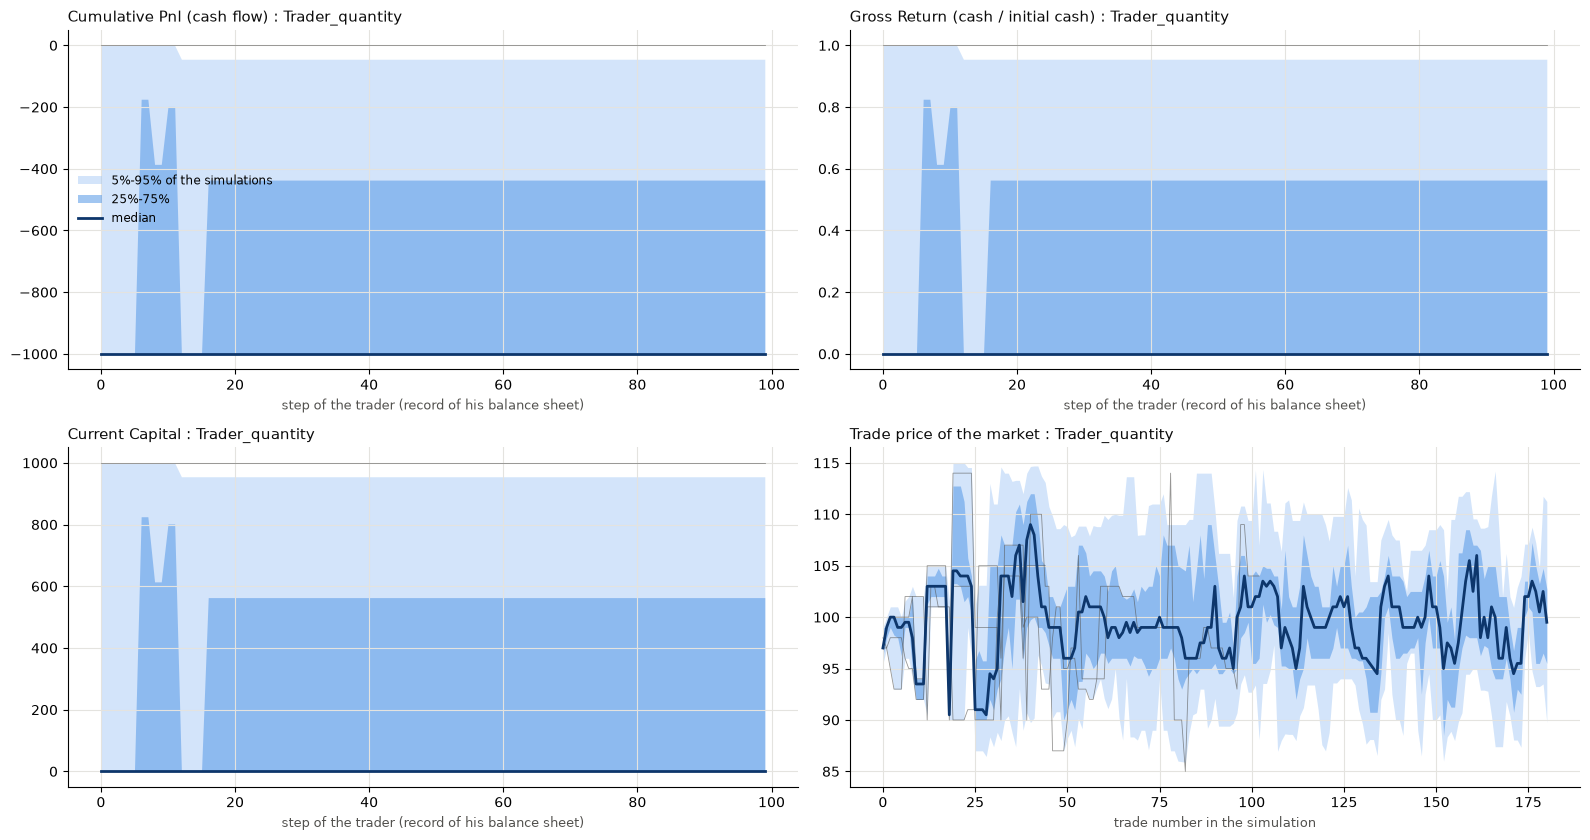

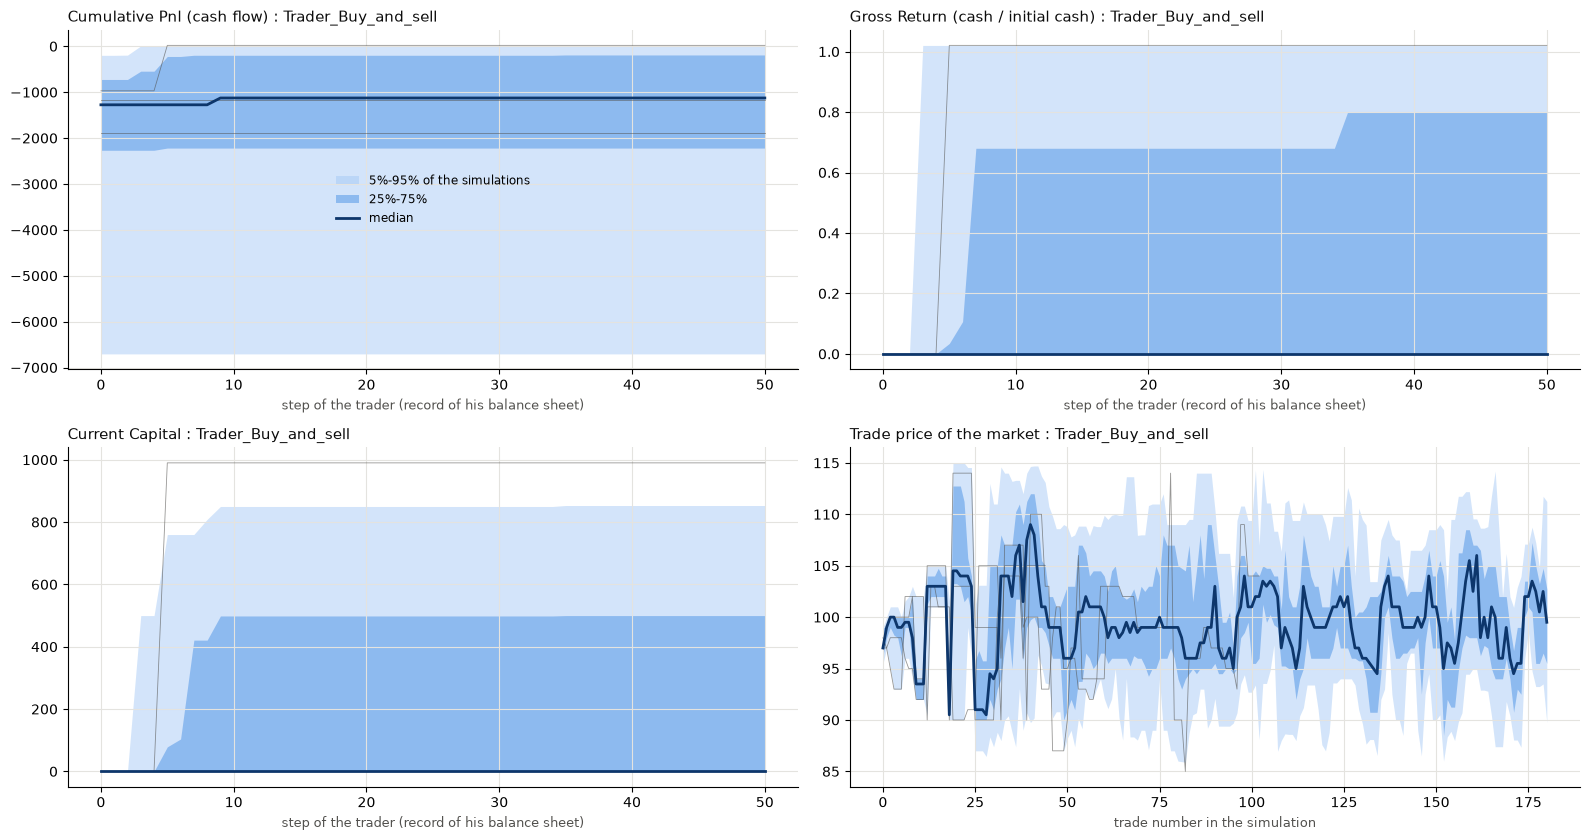

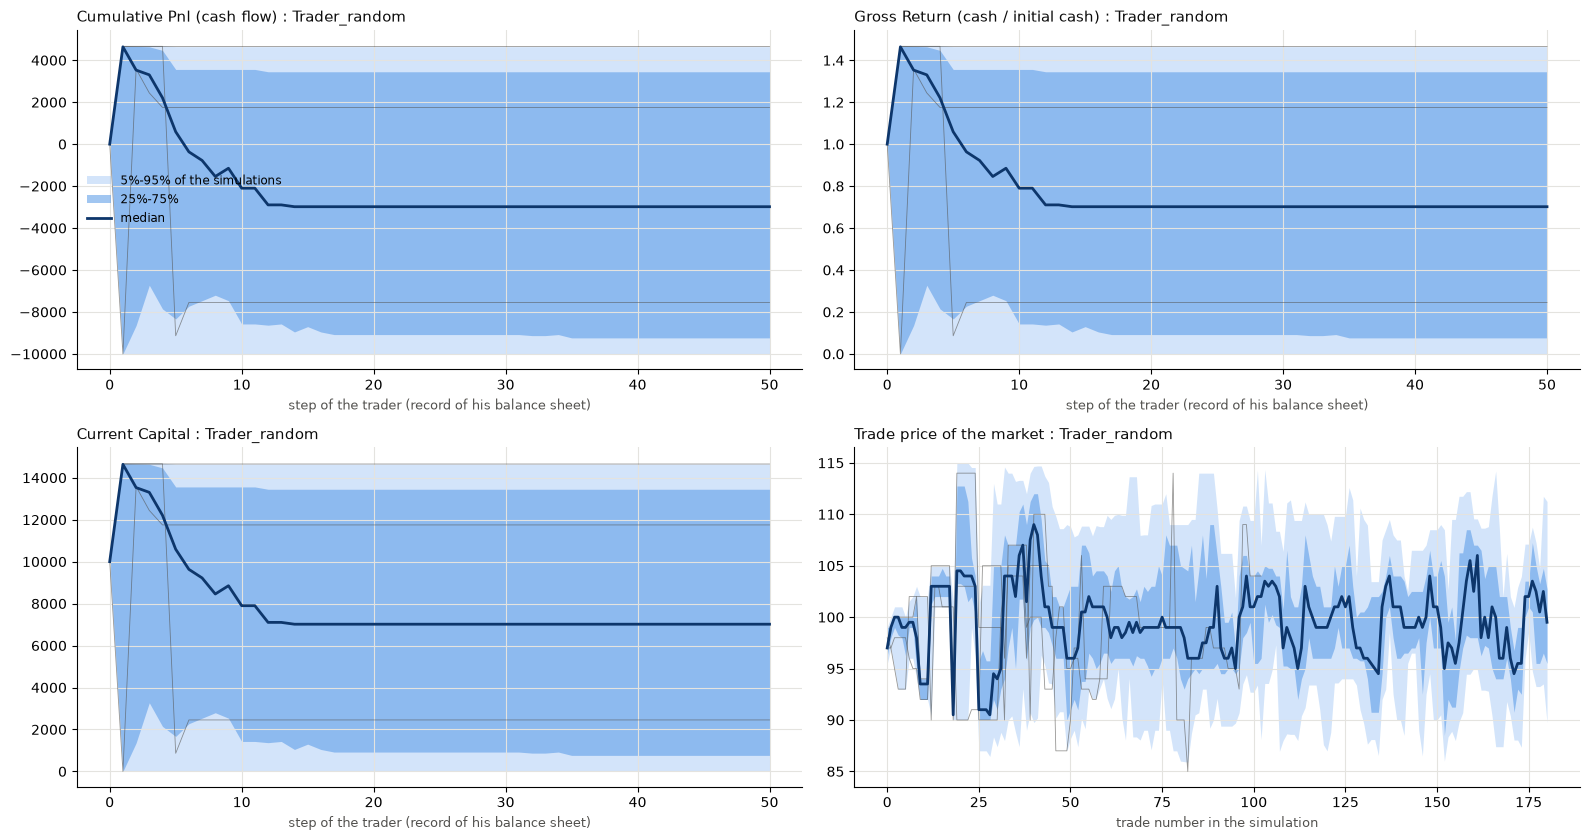

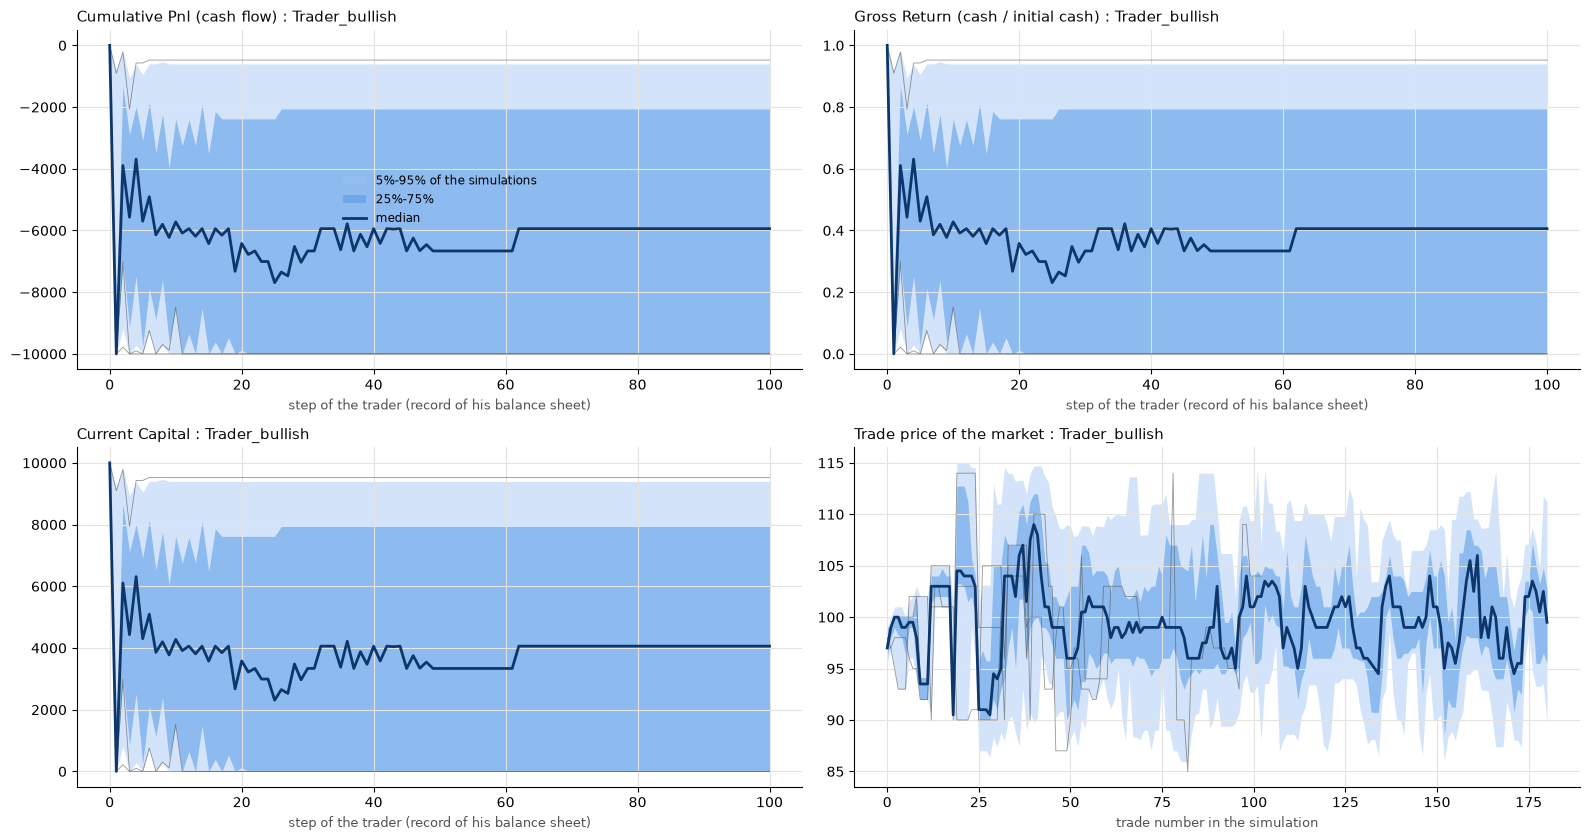

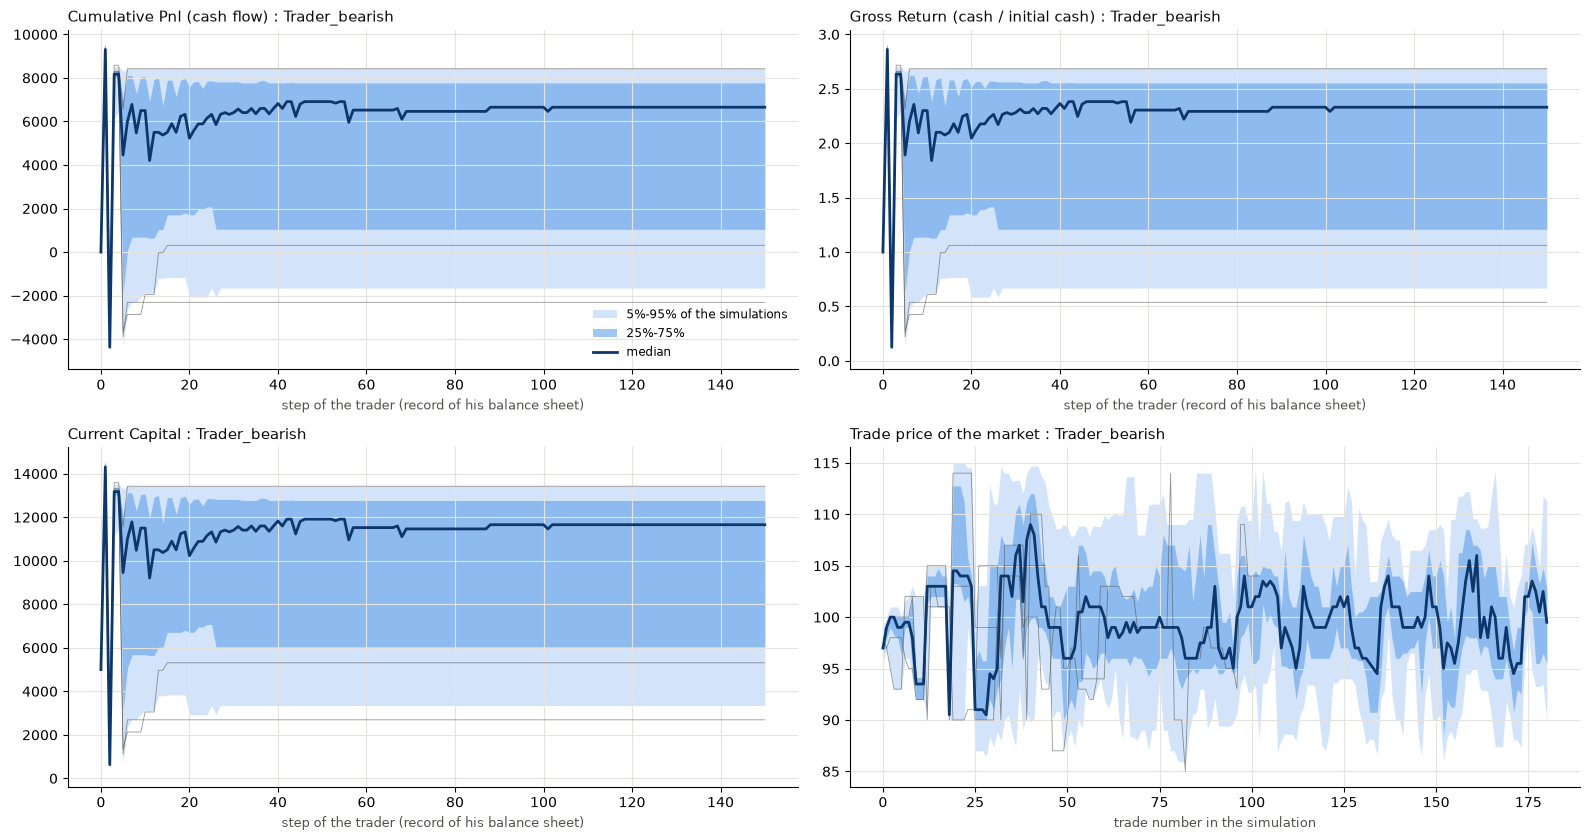

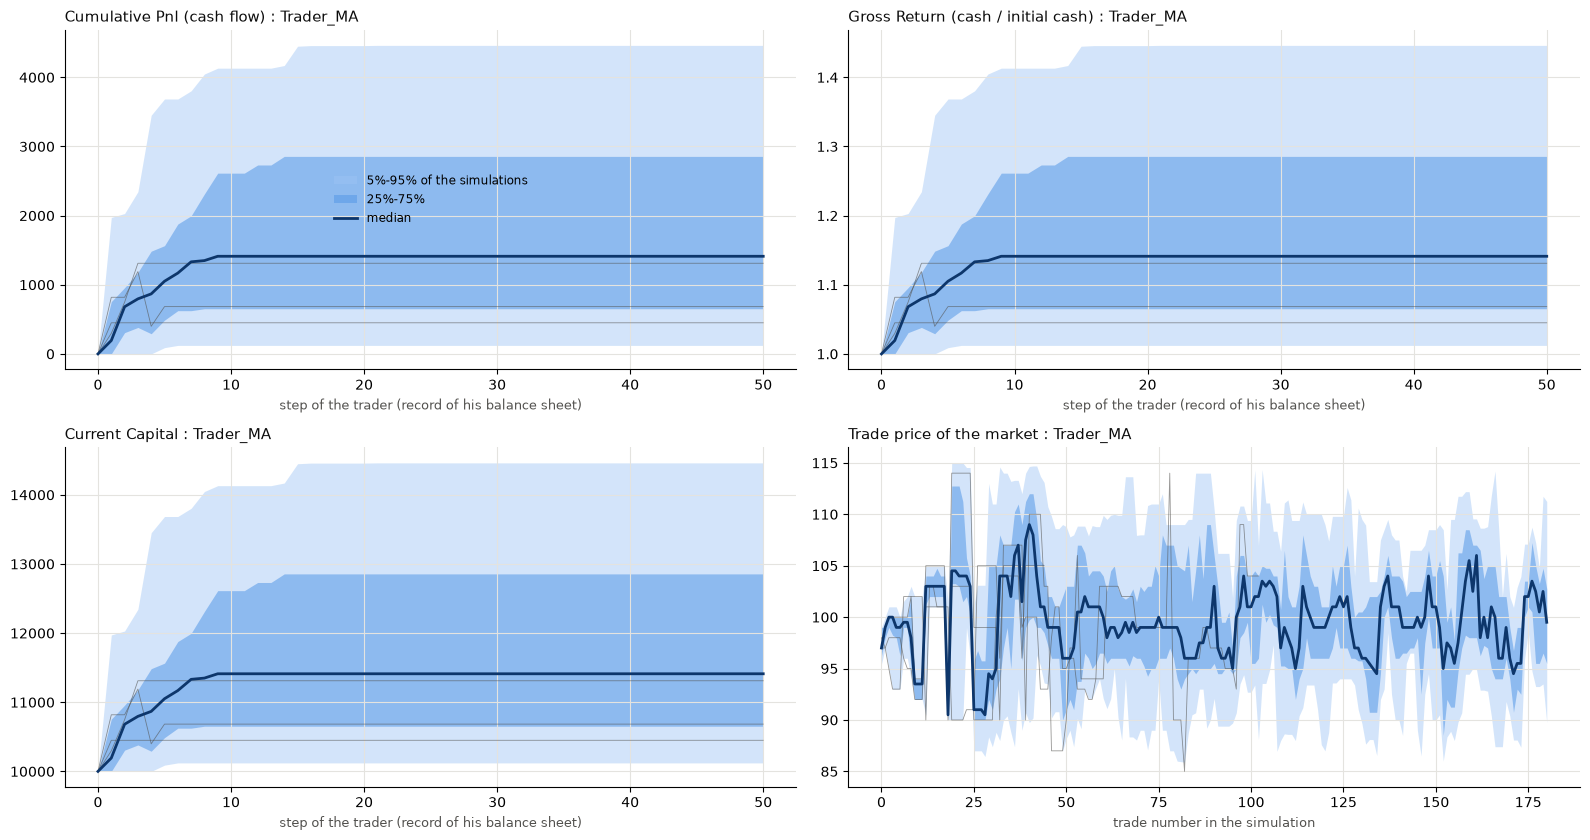

In [7]:
for name in STRATEGIES:
    GetList(result.sheets[name][:30], name, result.all_trajecs[:30])

### 3.6 End of period statistics

Descriptive statistics of the last balance sheet of each strategy over all the simulations. The tables are also written to `results/` (Excel and csv).

In [8]:
tables = end_of_period_tables(result)
for name, table in tables.items():
    print("End-of-period descriptive statistics over {} simulations made with the strategy {} with the specified parameters : ".format(cfg.nb_trader_per_strat, name))
    print(table)
    print("###################")
export_tables(tables, cfg.nb_trader_per_strat, '../results')

End-of-period descriptive statistics over 100 simulations made with the strategy Trader_quantity with the specified parameters : 
               Current Capital  Cumulative Pnl  Gross Return
count               100.000000      100.000000    100.000000
Mean                268.887963     -731.112037      0.268888
Std                 404.523151      404.523151      0.404523
Min                   0.000000    -1000.000000      0.000000
Max                1000.000000        0.000000      1.000000
1st quartile          0.000000    -1000.000000      0.000000
median                0.006500     -999.993500      0.000007
3rd quartile        794.537425     -205.462575      0.794537
95th quantile      1000.000000        0.000000      1.000000
###################
End-of-period descriptive statistics over 100 simulations made with the strategy Trader_Buy_and_sell with the specified parameters : 
               Current Capital  Cumulative Pnl  Gross Return
count               100.000000      100.00000

## 4. What does the baseline market look like?

A simulator is only useful if the market it produces behaves like a market. We measure the simulated tape and book with the tools of the book and compare with what is known about real markets:

| Quantity | Real markets (the book) | Where |
|---|---|---|
| Order signs | positively autocorrelated, $C(\ell)$ decays as a power law $\ell^{-\gamma}$ with $\gamma < 1$ (long memory) | chapter 10.1 |
| Lag-1 impact of a market order | $R(1) > 0$, and concave in the order volume: $R(v,1) \sim (v / V_{best})^{\zeta}$ with $\zeta$ between 0 and 0.3 | chapter 11.3, Eq. 11.5 and 11.7 |
| Spread | peaked at one tick for large-tick stocks, wide with an exponential tail for small-tick stocks | chapter 4.3 |
| Price changes | fat tails | chapter 2 |

Spread (ticks):
mean                   6.089
median                 5.000
p5                     1.000
p95                   14.000
share of 1 tick        0.117
observations       10178.000

Order sign autocorrelation: C(1) = -0.177 (standard error under independence 0.013)
Lags with a significantly positive C(l): 2 of 30
Power-law exponent gamma: not estimable (no long memory detected)

Lag-1 impact R(1) = 2.615 ticks (standard error 0.062, 3405 orders)


Exponent of the lag-1 impact against v / Vbest: zeta = 0.66
        v  immediate   lag1  orders
0   0.156      0.000  0.156     304
1   0.449      0.000  0.141     306
2   0.942      2.821  1.563     980
3   1.606      1.666  1.847     235
4   4.752      1.915  2.510     305
5  35.647      3.131  4.124     302

Mid-price changes:
non-zero mid changes    4003.000
std                        3.159
excess kurtosis            0.435


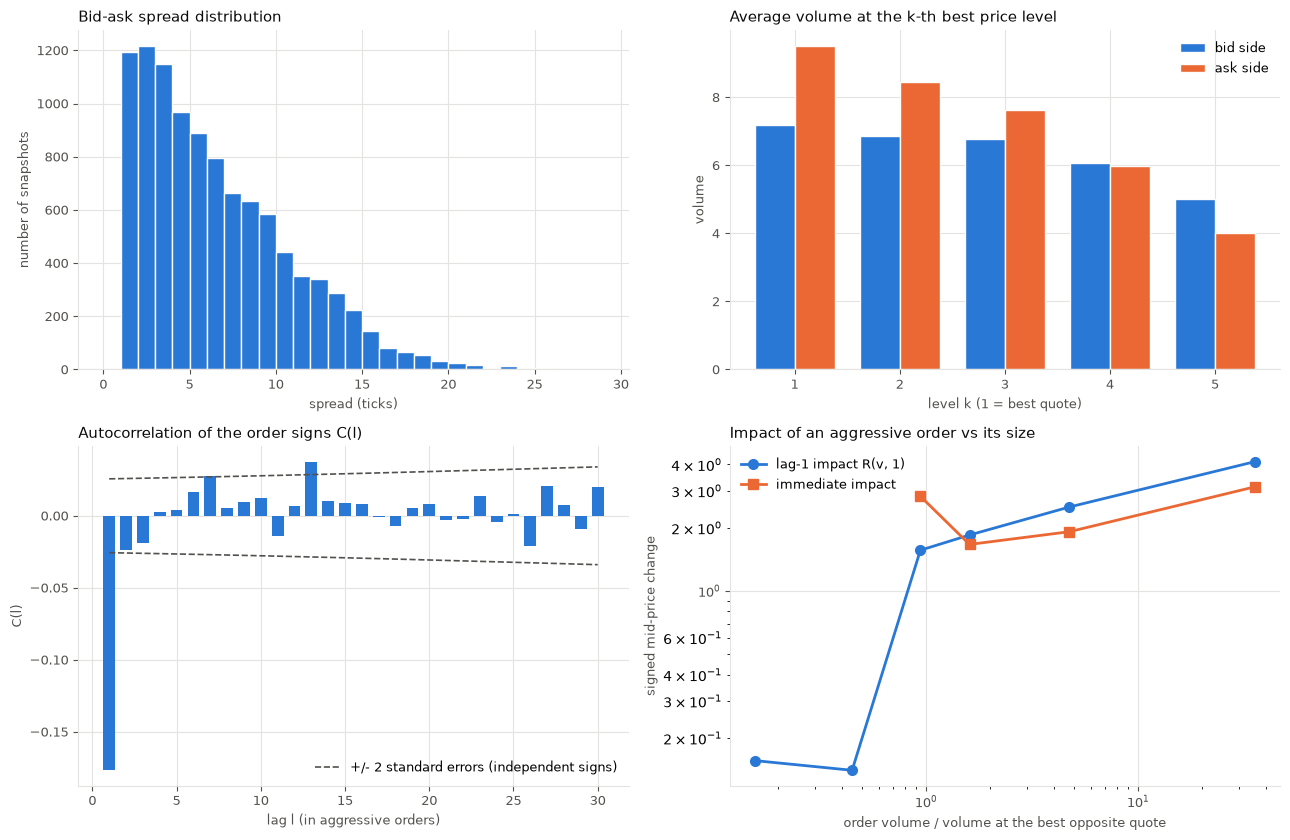

In [9]:
snaps = pd.concat(result.snapshots, ignore_index=True)
print("Spread (ticks):")
print(spread_summary(snaps).round(3).to_string())
print()
acf = order_sign_acf([o['sign'].values for o in result.orders], 30)
gamma = fit_power_law(acf['lag'], acf['acf'], acf['se'])
print("Order sign autocorrelation: C(1) = %.3f (standard error under independence %.3f)" % (acf.loc[0, 'acf'], acf.loc[0, 'se']))
print("Lags with a significantly positive C(l): %d of %d" % ((acf['acf'] > 2 * acf['se']).sum(), len(acf)))
print("Power-law exponent gamma:", "not estimable (no long memory detected)" if gamma is None else round(gamma, 2))
print()
r1, se, n = lag1_impact(result.orders)
print("Lag-1 impact R(1) = %.3f ticks (standard error %.3f, %d orders)" % (r1, se, n))
iv = impact_vs_volume(result.orders)
print("Exponent of the lag-1 impact against v / Vbest: zeta = %.2f" % fit_exponent(iv['v'], iv['lag1']))
print(iv.round(3).to_string())
print()
print("Mid-price changes:")
print(return_statistics(result.snapshots).round(3).to_string())
fig = plot_microstructure(result)

## 5. What do the strategies earn in the baseline market?

The `Cumulative Pnl` of the balance sheets is a cash flow (it only counts what was spent and received), so a strategy that bought shares looks like it lost money. Here every trader is valued **mark to market**: final cash plus shares valued at the final mid-price, minus the same at the start. `excess_pnl` removes what the initial shares would have earned just by being held.

The execution cost of an order is measured against the mid-price just before it was sent. The half-spread is the part every aggressive order pays, the rest is the price impact of walking through the book (chapters 11 and 16).

                     mtm_pnl_mean  mtm_pnl_std  excess_pnl_mean  share_profitable  orders_sent  filled_volume  half_spread_cost  execution_cost  impact_cost  t_stat
strategy                                                                                                                                                            
Trader_quantity            -27.82        72.29           -27.82              0.35         1.50          13.78             29.08           29.08         0.00   -3.85
Trader_Buy_and_sell          2.03       154.05             2.03              0.67         1.65          17.65             18.05           18.05         0.00    0.13
Trader_random             -778.10       750.10          -823.60              0.09         5.94         185.56            377.04          951.77       574.73  -10.37
Trader_bullish           -1464.41      1036.93         -1464.41              0.02        17.67         206.51            710.75         1335.30       624.54  -14.12
Trader_bea

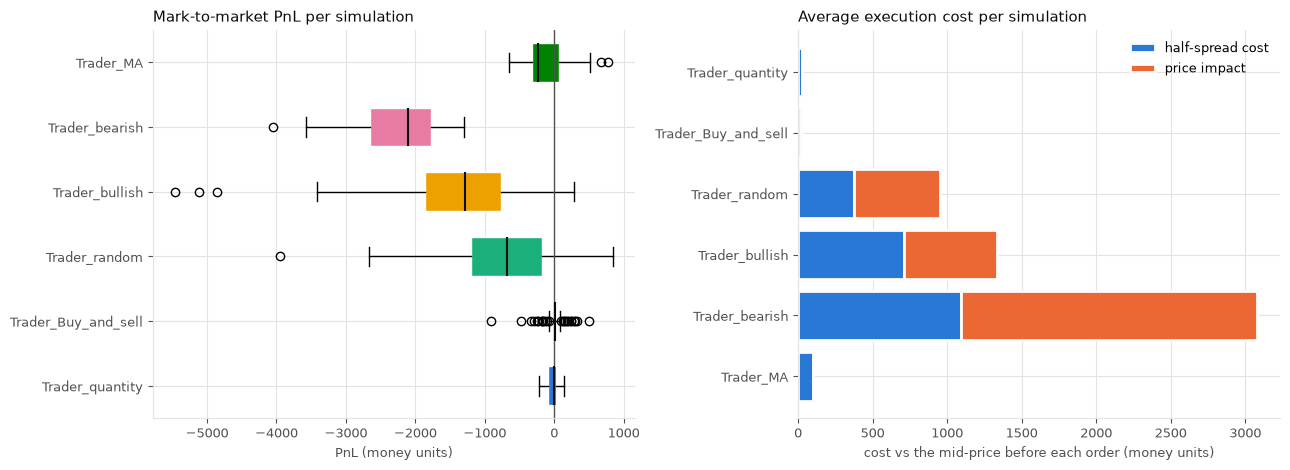

In [10]:
m = result.metrics
summary = m.groupby('strategy').agg(
    mtm_pnl_mean=('mtm_pnl', 'mean'), mtm_pnl_std=('mtm_pnl', 'std'),
    excess_pnl_mean=('excess_pnl', 'mean'), share_profitable=('mtm_pnl', lambda x: (x > 0).mean()),
    orders_sent=('orders_sent', 'mean'), filled_volume=('filled_volume', 'mean'),
    half_spread_cost=('half_spread_cost', 'mean'), execution_cost=('execution_cost', 'mean'))
summary['impact_cost'] = summary['execution_cost'] - summary['half_spread_cost']
summary['t_stat'] = summary['mtm_pnl_mean'] / (summary['mtm_pnl_std'] / np.sqrt(cfg.nb_trader_per_strat))
print(summary.loc[STRATEGIES].round(2).to_string())
fig = plot_strategies(m)

### Why the impact is what it is: a static book experiment

The price impact of a market order of size $Q$ walking through a static book is the inverse of the cumulative volume available. With the same volume at every price level the impact is linear in $Q$ (the Kyle-like case, exponent 1). If the volume grows linearly with the distance to the best price, the impact grows like $\sqrt{Q}$, which is the shape of Eq. 18.20 of the book for a linear volume profile and the order of magnitude of the empirical square-root law of Eq. 12.6 (exponent between 0.4 and 0.7). The experiment below uses the matching engine itself.

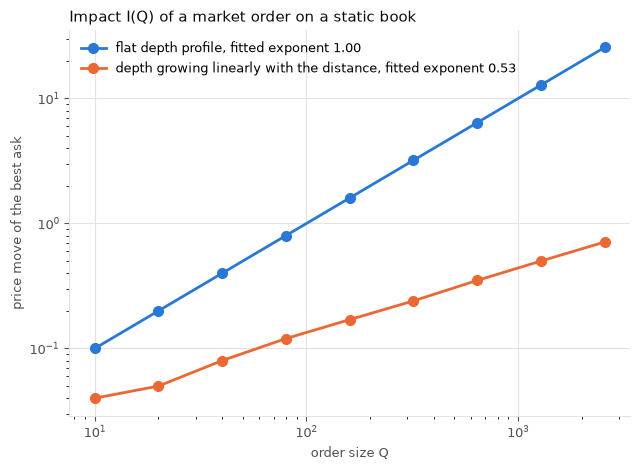

In [11]:
fig = plot_square_root()

## 6. What the baseline market teaches, and what it cannot

**The strategies.** Valued mark to market and against the real fills of the book, every strategy that sweeps several price levels loses money on average: `Trader_random` (t-statistic about -10), `Trader_bullish` (about -14) and `Trader_bearish` (about -37), and fewer than one simulation in ten ends in profit. Between 47% and 65% of their execution cost is price impact, the rest is the half-spread. The three strategies that only trade the best quote (`Trader_quantity`, `Trader_Buy_and_sell`, `Trader_MA`) pay only the half-spread, lose little, and `Trader_Buy_and_sell` is statistically indistinguishable from zero. The ranking is mostly a ranking of how aggressive each strategy is, which is what chapters 11 and 16 of the book predict for a market where nobody has an informational edge.

**The market.** The baseline tape reproduces one stylized fact: a market order moves the price against the trader that sends it (R(1) is positive and highly significant). It does not reproduce the others. The order signs are anti-correlated at lag 1 and show no long memory (real markets: positive, slowly decaying), the mid-price changes are close to Gaussian (real markets: fat tails), and the volume dependence of the impact (zeta about 0.66) is much stronger than the 0 to 0.3 of the book, because in this market the large orders are the ones sent by the traders, and these trigger the reaction orders of `REACTION_ORDERS`. The price path is therefore driven by those hard-coded reactions and by the uniform random flow, not by the strategies.

**Why an ecology.** The cost results are mechanical (they come from walking the book) and can be trusted. Conclusions about trend following (`Trader_MA`) cannot be carried over to real markets, since the baseline flow has no persistence for such a strategy to exploit. The market ecology below adds what the baseline market lacks: persistent order flow from split metaorders, information through an informed trader, and passive liquidity providers with a real PnL. The same measurements are then applied to it.

## 7. The market ecology

The baseline market has a spread of 6 ticks with a tick worth 1% of the price, no persistence in its order flow, and no passive liquidity provider with a PnL. The ecology replaces the uniform flow by agents that interact, each one modelled on a chapter of the book. Prices are on a grid of 0.01 (1 basis point of a price of 100).

| Agent | Behaviour | Book |
|---|---|---|
| `Trader_noise_maker` | zero-intelligence limit orders 1 to 20 ticks from the opposite best quote, each cancelled at a constant rate | chapter 8 (Santa Fe) |
| `Trader_noise_taker` | zero-intelligence market orders, buy or sell with equal probability | chapter 8 |
| `Trader_market_maker` | quotes both sides around a reservation price `mid - skew x inventory`, cancels and requotes | chapters 16 and 17 |
| `Trader_informed` | sees the fundamental value (a random walk with news jumps), buys when the ask is too low, sells when the bid is too high | chapters 15 and 16 |
| `Trader_metaorder` | 3 institutions with Pareto metaorder sizes (alpha = 1.5), executed as child market orders of 5 shares | chapters 10.5 and 12 |
| `Trader_latent_liquidity` | slow investors whose orders sit around a slow consensus price, depth growing linearly with the distance (used in section 14) | chapters 18 and 19 |
| the six directional strategies | the classes of section 3, settled on their real fills | section 3 |

The `Exchange` gives every agent a unique id and, for every trade, tells **both** counterparties about their fill (`on_fill`), so passive liquidity providers have a real PnL. Every event draws the same four uniform numbers whatever happens, so two runs with the same seed see the same randomness: section 14 uses this to measure the impact of a metaorder by running the market twice, with and without it (common random numbers).

In [12]:
# A market ecology for our limit order book.
# In the baseline market (simulation.py) the rest of the market is a uniform random flow of limit orders plus fixed reaction
# orders, and nobody is ever filled passively. Here the rest of the market is a set of interacting agents, each of them modelled
# on a chapter of Trades, Quotes and Prices (Bouchaud, Bonart, Donier, Gould, 2018):
#   Trader_noise_maker  : the zero-intelligence liquidity of the Santa Fe model, limit orders and cancellations (chapter 8)
#   Trader_noise_taker  : the zero-intelligence market orders of the Santa Fe model (chapter 8)
#   Trader_latent_liquidity : slow investors whose orders sit around a slowly moving consensus price, with a depth that grows
#                         linearly with the distance (latent liquidity, chapters 18 and 19, Mastromatteo, Toth and Bouchaud 2014)
#   Trader_market_maker : quotes on both sides around a reservation price skewed by his inventory (chapters 16 and 17)
#   Trader_informed     : trades towards a fundamental value that only he sees, the source of adverse selection (chapters 15 and 16)
#   Trader_metaorder    : institutional investors who split large orders with power-law sizes into small child orders (chapters 10.5 and 12)
# The six directional strategies of agents.py can trade in this market too (use_strategies).
# All the prices are handled in ticks (integers) by the agents and converted to Decimal on the tick grid of the book.
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd


KINDS = ['noise maker', 'noise taker', 'latent liquidity', 'market maker', 'informed', 'metaorder'] + STRATEGIES

# Order in which the six directional strategies act, the same order as in the baseline market
STRATEGY_STEPS = [('Trader_quantity', 'trade_first'), ('Trader_quantity', 'tradeSecond'), ('Trader_Buy_and_sell', 'trade'),
                ('Trader_random', 'trade'), ('Trader_bearish', 'tradeFirst'), ('Trader_bearish', 'SecondTrade'),
                ('Trader_bearish', 'ThirdTrade'), ('Trader_bullish', 'tradeFirst'), ('Trader_bullish', 'SecondTrade'),
                ('Trader_MA', 'firstTrade')]


class Exchange:
  '''
  Sits between the agents and the OrderBook. It gives every agent a unique trade_id, sends the orders, and tells the two
  counterparties of every trade that they were filled (on_fill), the passive one included. Every fill is also written in
  self.fills: (time, price, quantity, sign of the aggressor, trade_id of the aggressor, trade_id of the passive side).
  '''
  def __init__(self, order_book, recorder=None):
    self.order_book = order_book
    self.recorder = recorder
    self.agents = {}
    self.kinds = {}
    self.fills = []

  def register(self, agent, kind):
    agent.trade_id = len(self.agents) + 1
    agent.kind = kind
    self.agents[agent.trade_id] = agent
    self.kinds[agent.trade_id] = kind
    return agent

  def send(self, agent, quote):
    quote = dict(quote)
    quote['trade_id'] = agent.trade_id
    trades, resting = self.order_book.process_order(quote, False, False)
    sign = 1 if quote['side'] == 'bid' else -1
    for t in trades:
      passive = self.agents.get(t['party1'][0])
      if passive is not None and hasattr(passive, 'on_fill'):
        passive.on_fill(-sign, t['price'], t['quantity'], t['party1'][2], t['party1'][3])
      if hasattr(agent, 'on_fill'):
        agent.on_fill(sign, t['price'], t['quantity'], None, None)
      self.fills.append((t['time'], t['price'], t['quantity'], sign, agent.trade_id, t['party1'][0]))
    if self.recorder is not None:
      self.recorder.record(self.order_book)
    return trades, resting

  def cancel(self, side, order_id):
    self.order_book.cancel_order(side, order_id)
    if self.recorder is not None:
      self.recorder.record(self.order_book)


def best_ticks(order_book, tick):
  # best bid and best ask in ticks (None when the side is empty)
  bb, ba = order_book.get_best_bid(), order_book.get_best_ask()
  return (None if bb is None else int(bb / tick)), (None if ba is None else int(ba / tick))


class Agent:
  '''Accounting shared by the agents of the ecology: they are told about every fill, aggressive or passive'''
  def init_account(self, K, pnl, nb_shares):
    self.K = to_decimal(K)
    self.K_initial = self.K
    self.pnl = to_decimal(pnl)
    self.nb_shares = to_decimal(nb_shares)
    self.live = {} # order_id -> side of the orders of the agent resting in the book
    self.trader_balance_sheet = []

  def gross_return(self):
    return self.K/self.K_initial if self.K_initial else 0

  def on_fill(self, sign, price, quantity, order_id, remaining):
    # sign = +1 when the agent bought, -1 when he sold. remaining is None when his resting order was fully executed
    self.K -= sign*price*quantity
    self.pnl -= sign*price*quantity
    self.nb_shares += sign*quantity
    if order_id is not None and remaining is None:
      self.live.pop(order_id, None)

  def write(self, quote):
    record = {'Current Capital' : self.K, 'Cumulative Pnl' : self.pnl,'Gross Return' : self.gross_return(), 'nb_shares' : self.nb_shares,'order_sent' : quote}
    self.trader_balance_sheet.append(record)

  def post(self, exchange, side, price_ticks, quantity, tick):
    quote = {'type' : 'limit', 'side' : side, 'quantity' : quantity, 'price' : tick*price_ticks, 'trade_id' : self.trade_id}
    trades, resting = exchange.send(self, quote)
    if resting is not None:
      self.live[resting['order_id']] = side
    return quote

  def cancel_all(self, exchange):
    for order_id, side in list(self.live.items()):
      exchange.cancel(side, order_id)
    self.live = {}


def geometric_size(u, mean):
  # order sizes: 1 + an exponential variable, rounded down (mean about `mean` shares)
  return 1 + int(-math.log(1 - u)*(mean - 0.5))


class Trader_noise_maker(Agent):
  # The zero-intelligence liquidity of the Santa Fe model: many anonymous traders who place limit orders at a uniform distance
  # (1 to `window` ticks) from the opposite best quote, and cancel each of their orders at a constant rate
  def __init__(self, K, pnl, nb_shares, window, size_mean, tick, anchor_ticks):
    self.init_account(K, pnl, nb_shares)
    self.window, self.size_mean, self.tick, self.anchor = window, size_mean, tick, anchor_ticks
    self.ids = [] # the live order ids in a list, to pick one at random in O(1)
    self.position = {}

  def on_fill(self, sign, price, quantity, order_id, remaining):
    Agent.on_fill(self, sign, price, quantity, None, None)
    if order_id is not None and remaining is None:
      self._forget(order_id)

  def _forget(self, order_id):
    k = self.position.pop(order_id, None)
    if k is None:
      return
    last = self.ids.pop()
    if k < len(self.ids):
      self.ids[k] = last
      self.position[last] = k
    self.live.pop(order_id, None)

  def limit_order(self, exchange, u_side, u_price, u_size):
    bb, ba = best_ticks(exchange.order_book, self.tick)
    distance = 1 + int(u_price*self.window)
    if u_side < 0.5:
      side = 'bid'
      ref = ba if ba is not None else (bb + 1 if bb is not None else self.anchor)
      price = ref - distance
    else:
      side = 'ask'
      ref = bb if bb is not None else (ba - 1 if ba is not None else self.anchor)
      price = ref + distance
    if price <= 0:
      return None
    quote = {'type' : 'limit', 'side' : side, 'quantity' : geometric_size(u_size, self.size_mean), 'price' : self.tick*price, 'trade_id' : self.trade_id}
    trades, resting = exchange.send(self, quote)
    if resting is not None:
      self.live[resting['order_id']] = side
      self.position[resting['order_id']] = len(self.ids)
      self.ids.append(resting['order_id'])
    return quote

  def cancel_one(self, exchange, u):
    if not self.ids:
      return None
    order_id = self.ids[int(u*len(self.ids))]
    side = self.live[order_id]
    exchange.cancel(side, order_id)
    self._forget(order_id)
    return order_id


class Trader_latent_liquidity(Trader_noise_maker):
  # Slow investors (pension funds, asset managers) who are willing to buy below and sell above a consensus price that only moves
  # slowly (an exponential average of the mid-price over `tau` events). Their orders are placed at a distance d from this consensus
  # with a density proportional to d: almost nothing close to the price, more and more liquidity further away. This is the
  # V-shaped latent order book of chapters 18 and 19. When the price is pushed away from the consensus, it meets more and more
  # of this liquidity, and when the price is below the consensus some of their buy orders are directly executable.
  def __init__(self, K, pnl, nb_shares, window, size_mean, tick, anchor_ticks, tau):
    Trader_noise_maker.__init__(self, K, pnl, nb_shares, window, size_mean, tick, anchor_ticks)
    self.consensus = float(anchor_ticks)
    self.tau = tau

  def update(self, mid_ticks):
    if mid_ticks == mid_ticks: # not NaN
      self.consensus += (mid_ticks - self.consensus)/self.tau

  def limit_order(self, exchange, u_side, u_price, u_size):
    distance = 1 + int(self.window*math.sqrt(u_price)) # density of the distance proportional to the distance
    centre = int(round(self.consensus))
    side = 'bid' if u_side < 0.5 else 'ask'
    price = centre - distance if side == 'bid' else centre + distance
    if price <= 0:
      return None
    quote = {'type' : 'limit', 'side' : side, 'quantity' : geometric_size(u_size, self.size_mean), 'price' : self.tick*price, 'trade_id' : self.trade_id}
    trades, resting = exchange.send(self, quote)
    if resting is not None:
      self.live[resting['order_id']] = side
      self.position[resting['order_id']] = len(self.ids)
      self.ids.append(resting['order_id'])
    return quote


class Trader_noise_taker(Agent):
  # The zero-intelligence market orders of the Santa Fe model: buy or sell with equal probability, independently of everything
  def __init__(self, K, pnl, nb_shares, size_mean):
    self.init_account(K, pnl, nb_shares)
    self.size_mean = size_mean

  def trade(self, exchange, u_side, u_size):
    side = 'bid' if u_side < 0.5 else 'ask'
    quote = {'type': 'market', 'side': side, 'quantity': geometric_size(u_size, self.size_mean), 'trade_id': self.trade_id}
    exchange.send(self, quote)
    return quote


class Trader_market_maker(Agent):
  # This trader quotes on both sides of the book. He centres his quotes on a reservation price r = mid - skew*inventory
  # (the inventory control of Avellaneda and Stoikov, chapter 17): when he holds too many shares he lowers both quotes to sell
  # more and buy less. He earns the spread on the uninformed flow and loses on the informed flow (adverse selection, chapter 16).
  def __init__(self, K, pnl, nb_shares, half_spread, skew, size, max_inventory, tick):
    self.init_account(K, pnl, nb_shares)
    self.half_spread, self.skew, self.size, self.max_inventory, self.tick = half_spread, skew, size, max_inventory, tick
    self.inventory_path = []

  def requote(self, exchange):
    self.cancel_all(exchange)
    bb, ba = best_ticks(exchange.order_book, self.tick)
    if bb is None or ba is None:
      self.val = False
      return self.val
    inventory = float(self.nb_shares)
    r = (bb + ba)/2 - self.skew*inventory
    bid = min(math.floor(r - self.half_spread), ba - 1)
    ask = max(math.ceil(r + self.half_spread), bb + 1)
    if ask <= bid: # never quote against himself
      ask = bid + 1
    quotes = []
    if inventory < self.max_inventory and bid > 0:
      quotes.append(self.post(exchange, 'bid', bid, min(self.size, self.max_inventory - inventory), self.tick))
    if inventory > -self.max_inventory:
      quotes.append(self.post(exchange, 'ask', ask, min(self.size, self.max_inventory + inventory), self.tick))
    self.inventory_path.append((exchange.order_book.time, inventory))
    self.write(quotes)
    self.val = True
    return self.val


class Trader_informed(Agent):
  # This trader knows the fundamental value V of the share (a random walk with rare jumps: the news). When the best ask is
  # below V by more than a threshold he buys with a market order, when the best bid is above V by more than the threshold
  # he sells. He is the one who brings the information into the price.
  def __init__(self, K, pnl, nb_shares, threshold, size, max_position, tick):
    self.init_account(K, pnl, nb_shares)
    self.threshold, self.size, self.max_position, self.tick = threshold, size, max_position, tick

  def trade(self, exchange, value_ticks):
    bb, ba = best_ticks(exchange.order_book, self.tick)
    position = float(self.nb_shares)
    quote = None
    if ba is not None and value_ticks - ba > self.threshold and position < self.max_position:
      quote = {'type': 'market', 'side': 'bid', 'quantity': min(self.size, self.max_position - position), 'trade_id': self.trade_id}
    elif bb is not None and bb - value_ticks > self.threshold and position > -self.max_position:
      quote = {'type': 'market', 'side': 'ask', 'quantity': min(self.size, self.max_position + position), 'trade_id': self.trade_id}
    if quote is not None:
      exchange.send(self, quote)
      self.write(quote)
    return quote


class Trader_metaorder(Agent):
  # An institutional investor who must buy or sell a large quantity Q (a metaorder, chapter 12). Q has a Pareto distribution
  # P(Q > q) = (q_min / q)^alpha, and the metaorder is executed with small child market orders. Lillo, Mike and Farmer showed
  # that this splitting makes the signs of the market orders autocorrelated with C(l) ~ l^-(alpha - 1) (chapter 10.5).
  def __init__(self, K, pnl, nb_shares, alpha, q_min, q_max, child_size):
    self.init_account(K, pnl, nb_shares)
    self.alpha, self.q_min, self.q_max, self.child_size = alpha, q_min, q_max, child_size
    self.remaining, self.sign = 0, 0
    self.metaorders = [] # (start time, sign, size, end time)

  def trade(self, exchange, u_sign, u_size):
    if self.remaining <= 0:
      self.sign = 1 if u_sign < 0.5 else -1
      self.remaining = min(int(self.q_min*(1 - u_size)**(-1/self.alpha)), self.q_max)
      self.metaorders.append([exchange.order_book.time, self.sign, self.remaining, None])
    side = 'bid' if self.sign > 0 else 'ask'
    quantity = min(self.child_size, self.remaining)
    quote = {'type': 'market', 'side': side, 'quantity': quantity, 'trade_id': self.trade_id}
    trades, _ = exchange.send(self, quote)
    self.remaining -= quantity # an unfilled child (empty side) is not sent again: the investor gives up on it
    if self.remaining <= 0:
      self.metaorders[-1][3] = exchange.order_book.time
    return quote


@dataclass
class EcologyConfig:
  '''Parameters of the market ecology. Rates are relative: at every event, an agent is drawn with a probability proportional to its rate.'''
  seed: int = 11
  nb_events: int = 20000 # events after the warm-up
  warmup: int = 3000 # events of noise flow only, to build the book
  tick: float = 0.01
  start_price: float = 100.0
  # zero-intelligence (Santa Fe) flow
  window: int = 20 # limit orders are placed 1 to `window` ticks away from the opposite best quote
  limit_rate: float = 1.0 # per price level of the window and per side
  market_rate: float = 2.5 # noise market orders, per side
  cancel_rate: float = 0.15 # per resting noise order
  noise_size: float = 5.0
  # latent liquidity
  use_latent: bool = False
  latent_rate: float = 10.0
  latent_window: int = 60 # ticks
  latent_cancel_rate: float = 0.02 # per resting latent order
  latent_tau: float = 5000.0 # events, memory of the consensus price
  # market maker
  use_market_maker: bool = True
  mm_rate: float = 6.0
  mm_half_spread: float = 1.0 # ticks
  mm_skew: float = 0.05 # ticks of reservation price per share of inventory
  mm_size: int = 10
  mm_max_inventory: int = 100
  # informed trader and fundamental value
  use_informed: bool = True
  informed_rate: float = 3.0
  informed_threshold: float = 3.0 # ticks
  informed_size: int = 10
  informed_max_position: int = 3000
  fundamental_vol: float = 0.15 # ticks per event
  jump_probability: float = 0.0005 # news, per event
  jump_size: float = 15.0 # ticks
  # metaorders
  use_metaorders: bool = True
  nb_metaorder_traders: int = 3
  metaorder_rate: float = 1.5 # per institutional trader
  metaorder_alpha: float = 1.5
  metaorder_min: int = 10
  metaorder_max: int = 5000
  child_size: int = 5
  # the six directional strategies of agents.py
  use_strategies: bool = False
  strategy_rate: float = 0.5
  strategy_config: SimulationConfig = None
  record: bool = True


class EcologyResult:
  '''What a run of the ecology produces'''
  pass


def fundamental_path(cfg):
  # V_t = V_(t-1) + vol * N(0,1) + rare jumps (news). It has its own random generator, so that the market can be replayed
  rng = np.random.default_rng(cfg.seed + 1_000_003)
  n = cfg.warmup + cfg.nb_events
  steps = cfg.fundamental_vol*rng.standard_normal(n)
  jumps = (rng.random(n) < cfg.jump_probability)*cfg.jump_size*np.where(rng.random(n) < 0.5, -1, 1)
  return cfg.start_price/cfg.tick + np.cumsum(steps + jumps)


def run_ecology(cfg, hook=None):
  '''
  Runs the market ecology. Every event draws 4 uniform numbers from one generator whatever happens, so that two runs with the
  same seed see the same random numbers (common random numbers): `hook(i, exchange)` is called after the i-th event and can
  send extra orders (a test metaorder for instance) without changing the random numbers seen by the rest of the market.
  '''
  if cfg.use_strategies:
    np.random.seed(cfg.seed) # the six directional strategies use numpy's global generator
  rng = np.random.default_rng(cfg.seed)
  tick = to_decimal(cfg.tick)
  anchor = int(round(cfg.start_price/cfg.tick))
  order_book = OrderBook(tick_size=cfg.tick)
  recorder = BookRecorder(levels=5)
  exchange = Exchange(order_book, None)
  maker = exchange.register(Trader_noise_maker(10**9, 0, 10**7, cfg.window, cfg.noise_size, tick, anchor), 'noise maker')
  taker = exchange.register(Trader_noise_taker(10**9, 0, 10**7, cfg.noise_size), 'noise taker')
  latent = None
  if cfg.use_latent:
    latent = exchange.register(Trader_latent_liquidity(10**9, 0, 10**7, cfg.latent_window, cfg.noise_size, tick, anchor, cfg.latent_tau), 'latent liquidity')
  value = fundamental_path(cfg)
  mm = informed = None
  meta, strategies = [], {}
  mids = np.full(cfg.warmup + cfg.nb_events, np.nan)
  values = []
  step = 0

  for i in range(cfg.warmup + cfg.nb_events):
    u = rng.random(4)
    if i == cfg.warmup:
      # the book is built: the other agents arrive
      if cfg.record:
        exchange.recorder = recorder
        recorder.record(order_book)
      start_time = order_book.time
      if cfg.use_market_maker:
        mm = exchange.register(Trader_market_maker(100000, 0, 0, cfg.mm_half_spread, cfg.mm_skew, cfg.mm_size, cfg.mm_max_inventory, tick), 'market maker')
      if cfg.use_informed:
        informed = exchange.register(Trader_informed(100000, 0, 0, cfg.informed_threshold, cfg.informed_size, cfg.informed_max_position, tick), 'informed')
      if cfg.use_metaorders:
        meta = [exchange.register(Trader_metaorder(10**7, 0, 0, cfg.metaorder_alpha, cfg.metaorder_min, cfg.metaorder_max, cfg.child_size), 'metaorder')
                for _ in range(cfg.nb_metaorder_traders)]
      if cfg.use_strategies:
        lc = cfg.strategy_config or SimulationConfig()
        strategies = {
          'Trader_quantity': Trader_quantity(lc.K_trader_qty, lc.pnl_trader_qty, lc.nb_shares_trader_qty),
          'Trader_Buy_and_sell': Trader_Buy_and_sell(order_book),
          'Trader_random': Trader_random(lc.K_trader_random, lc.pnl_trader_random, lc.nb_shares_trader_random),
          'Trader_bullish': Trader_bullish(lc.K_trader_bullish, lc.pnl_trader_bullish, lc.nb_shares_trader_bullish),
          'Trader_bearish': Trader_bearish(lc.K_trader_bearish, lc.pnl_trader_bearish, lc.nb_shares_trader_bearish),
          'Trader_MA': Trader_MA(lc.K_trader_MA, lc.pnl_trader_MA, lc.nb_shares_trader_MA, lc.mvg_trader_MA),
        }
        for name, t in strategies.items():
          exchange.register(t, name)
        T = strategies['Trader_Buy_and_sell']
        settle(order_book, T, T.initial_quote, (T.K_initial, 0, 0), order_book.get_mid_price(), order_book.get_spread(), None, exchange)
      strategy_start = {name: (float(t.K_initial), 0.0 if name == 'Trader_Buy_and_sell' else float(t.nb_shares)) for name, t in strategies.items()}

    active = i >= cfg.warmup
    rates = [2*cfg.window*cfg.limit_rate, 2*cfg.market_rate, cfg.cancel_rate*len(maker.ids),
             cfg.mm_rate if mm is not None else 0, cfg.informed_rate if informed is not None else 0,
             cfg.metaorder_rate*len(meta), cfg.strategy_rate if strategies else 0,
             cfg.latent_rate if latent is not None else 0, cfg.latent_cancel_rate*len(latent.ids) if latent is not None else 0]
    cumulative = np.cumsum(rates)
    x = u[0]*cumulative[-1]
    k = min(int(np.searchsorted(cumulative, x, side='right')), max(j for j, r in enumerate(rates) if r > 0))
    w = min((x - (cumulative[k - 1] if k > 0 else 0))/rates[k], 0.999999) # uniform in [0, 1) again, used inside the event
    if k == 0:
      maker.limit_order(exchange, w, u[1], u[2])
    elif k == 1:
      taker.trade(exchange, w, u[1])
    elif k == 2:
      maker.cancel_one(exchange, w)
    elif k == 3:
      mm.requote(exchange)
    elif k == 4:
      informed.trade(exchange, value[i])
    elif k == 5:
      meta[min(int(w*len(meta)), len(meta) - 1)].trade(exchange, u[1], u[2])
    elif k == 7:
      latent.limit_order(exchange, w, u[1], u[2])
    elif k == 8:
      latent.cancel_one(exchange, w)
    else:
      name, method = STRATEGY_STEPS[step % len(STRATEGY_STEPS)]
      step += 1
      trader = strategies[name]
      state = (trader.K, trader.pnl, trader.nb_shares)
      mid_before, spread_before = order_book.get_mid_price(), order_book.get_spread()
      val, quote, balance_sheet = getattr(trader, method)(order_book)
      if val == True:
        settle(order_book, trader, quote, state, mid_before, spread_before, None, exchange)
    if hook is not None:
      hook(i, exchange)
    mid = order_book.get_mid_price()
    mids[i] = np.nan if mid is None else float(mid)/cfg.tick
    if latent is not None:
      latent.update(mids[i])
    if active and cfg.record:
      values.append((order_book.time, value[i]))

  res = EcologyResult()
  res.cfg, res.exchange, res.order_book = cfg, exchange, order_book
  res.mids = mids # mid-price in ticks after every event
  res.mm, res.informed, res.meta, res.strategies, res.latent = mm, informed, meta, strategies, latent
  if not cfg.record:
    return res
  res.strategy_start = strategy_start
  res.start_time = start_time
  res.snapshots = recorder.frame()
  res.snapshots[['mid', 'spread']] = res.snapshots[['mid', 'spread']]/cfg.tick # in ticks from now on
  for c in [c for c in res.snapshots.columns if c.startswith(('bid_p', 'ask_p'))]:
    res.snapshots[c] = res.snapshots[c]/cfg.tick
  res.fundamental = pd.DataFrame(values, columns=['time', 'value'])
  fills = pd.DataFrame(exchange.fills, columns=['time', 'price', 'quantity', 'sign', 'aggressor', 'passive'])
  fills = fills[fills['time'] > start_time].reset_index(drop=True)
  fills['price'] = fills['price'].astype(float)/cfg.tick
  fills['quantity'] = fills['quantity'].astype(float)
  fills['aggressor_kind'] = fills['aggressor'].map(exchange.kinds)
  fills['passive_kind'] = fills['passive'].map(exchange.kinds)
  res.fills = fills
  orders = order_frame(fills[['time', 'price', 'quantity', 'sign']], res.snapshots)
  orders['kind'] = orders['time'].map(fills.groupby('time')['aggressor_kind'].first())
  res.orders = orders
  return res

The studies and their figures (same code as `src/experiments.py`):

In [13]:
# The studies run on the market ecology, and their figures.
#   ablation()            which ingredient of the market produces which stylized fact (chapters 2, 4, 10, 11)
#   ecology_study()       who trades with whom, who earns what, and what the six directional strategies earn in a realistic market
#   market_maker_sweep()  the spread a market maker should quote, with and without informed traders (chapters 16 and 17)
#   metaorder_experiment() the impact of a metaorder measured with common random numbers: is it a square-root? (chapter 12)
import numpy as np
import pandas as pd


PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']

DESIGNS = {
    'Zero intelligence': dict(use_market_maker=False, use_informed=False, use_metaorders=False),
    'Zero intelligence + metaorders': dict(use_market_maker=False, use_informed=False),
    'Full ecology': dict(),
}
BASELINE = 'Baseline market (uniform flow)'
KIND_LABELS = {'noise taker': 'noise takers', 'informed': 'informed', 'metaorder': 'metaorders', 'strategies': 'directional strategies',
               'market maker': 'market maker', 'noise maker': 'noise makers'}


def ablation(seeds=(1, 2, 3, 4, 5, 6), nb_events=20000, baseline=None):
    '''
    Runs the market with more and more ingredients and measures the same statistics on each one. Ticks are the unit of price
    everywhere (1 money unit in the baseline market, 0.01 in the ecology).
    '''
    out = {}
    if baseline is None:
        baseline = run_simulation(SimulationConfig(seed=42, nb_trader_per_strat=100))
    out[BASELINE] = {'orders': baseline.orders, 'snapshots': baseline.snapshots,
                          'mids': [s['mid'].values for s in baseline.snapshots]}
    for name, kw in DESIGNS.items():
        runs = [run_ecology(EcologyConfig(seed=seed, nb_events=nb_events, **kw)) for seed in seeds]
        out[name] = {'orders': [r.orders for r in runs], 'snapshots': [r.snapshots for r in runs],
                     'mids': [r.mids[r.cfg.warmup:] for r in runs]}
    return out


def stylized_facts_table(ablation_result, horizon=20):
    rows = []
    for name, d in ablation_result.items():
        acf = order_sign_acf([o['sign'].values for o in d['orders']], 100)
        gamma = fit_power_law(acf['lag'], acf['acf'], acf['se'])
        resp = response_function(d['orders'], 20)
        z = standardized_changes(d['mids'], horizon)
        spread = pd.concat(d['snapshots'])['spread'].dropna()
        rows.append({'market': name, 'C(1)': acf['acf'].iloc[0], 'C(10)': acf['acf'].iloc[9],
                     'C(50)': acf['acf'].iloc[49] if len(acf) >= 50 else np.nan,
                     'gamma': np.nan if gamma is None else gamma, 'R(1) ticks': resp['R'].iloc[0], 'R(20)/R(1)': resp['R'].iloc[19]/resp['R'].iloc[0],
                     'mean spread (ticks)': spread.mean(), 'P(spread = 1 tick)': (spread <= 1).mean(),
                     'excess kurtosis (%d events)' % horizon: pd.Series(z).kurt(),
                     'aggressive orders': sum(len(o) for o in d['orders'])})
    return pd.DataFrame(rows).set_index('market')


def binned_acf(acf, edges=(1, 2, 3, 5, 8, 13, 21, 34, 55, 101)):
    '''Average of C(l) over logarithmic bins of lags (the standard error shrinks with the number of lags in the bin)'''
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        b = acf[(acf['lag'] >= lo) & (acf['lag'] < hi)]
        if len(b):
            rows.append((np.exp(np.log(b['lag']).mean()), b['acf'].mean(), b['se'].mean()/np.sqrt(len(b))))
    return pd.DataFrame(rows, columns=['lag', 'acf', 'se'])


def plot_stylized_facts(ablation_result, horizon=20, save_path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for (name, d), color in zip(ablation_result.items(), PALETTE):
        acf = order_sign_acf([o['sign'].values for o in d['orders']], 100)
        b = binned_acf(acf)
        ok = b['acf'] > 2*b['se']
        if ok.any():
            axes[0, 0].plot(b['lag'][ok], b['acf'][ok], marker='o', markersize=7, linewidth=2, color=color, label=name)
        else:
            axes[0, 0].plot([], [], marker='o', color=color, label=name + ': no significant memory')
        resp = response_function(d['orders'], 30)
        axes[0, 1].plot(resp['lag'], resp['R'], linewidth=2, color=color, label=name)
        axes[0, 1].fill_between(resp['lag'], resp['R'] - 2*resp['se'], resp['R'] + 2*resp['se'], color=color, alpha=0.15, linewidth=0)
        spread = np.round(pd.concat(d['snapshots'])['spread'].dropna()).astype(int)
        p = spread.value_counts(normalize=True).sort_index()
        p = p[p.index <= 15]
        axes[1, 0].plot(p.index, p.values, marker='o', markersize=7, linewidth=2, color=color, label=name)
        z = np.sort(np.abs(standardized_changes(d['mids'], horizon)))
        if len(z):
            ccdf = 1 - np.arange(len(z))/len(z)
            axes[1, 1].plot(z, ccdf, linewidth=2, color=color, label=name)
    x = np.array([1, 100])
    axes[0, 0].plot(x, 0.08*x**-0.5, color=MUTED, linestyle='--', linewidth=1.2, label='slope -0.5 (Lillo-Mike-Farmer, alpha = 1.5)')
    axes[0, 0].set_xscale('log')
    axes[0, 0].set_yscale('log')
    _style(axes[0, 0], 'Order signs: only metaorder splitting creates long memory', 'lag l (aggressive orders, log bins)', 'C(l), values above 2 standard errors')
    axes[0, 1].axhline(0, color=MUTED, linewidth=1)
    _style(axes[0, 1], 'Response function R(l): impact grows when the flow is persistent', 'lag l (aggressive orders)', 'R(l) (ticks)')
    axes[1, 0].set_yscale('log')
    _style(axes[1, 0], 'Spread distribution: the baseline market is far too wide', 'spread (ticks)', 'probability')
    from math import erfc, sqrt
    g = np.linspace(0, 8, 100)
    axes[1, 1].plot(g, [erfc(v/sqrt(2)) for v in g], color=MUTED, linestyle='--', linewidth=1.2, label='Gaussian')
    axes[1, 1].set_yscale('log')
    axes[1, 1].set_xlim(0, 8)
    axes[1, 1].set_ylim(1e-4, 1.1)
    _style(axes[1, 1], 'Tails of the mid-price changes over %d events' % horizon, '|change| / standard deviation', 'P(|change| > x)')
    for ax in axes.flat:
        ax.legend(frameon=False, fontsize=8.5)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def agent_path(res, kind):
    '''Inventory and mark-to-market PnL (ticks x shares) of the agents of one kind, after every snapshot'''
    f = res.fills
    rows = []
    for col, s in (('aggressor_kind', 1), ('passive_kind', -1)):
        g = f[f[col] == kind]
        rows.append(pd.DataFrame({'time': g['time'], 'q': s*g['sign']*g['quantity'], 'cash': -s*g['sign']*g['quantity']*g['price']}))
    g = pd.concat(rows).groupby('time').sum().sort_index()
    snaps = res.snapshots[['time', 'mid']].copy()
    idx = np.searchsorted(g.index.values, snaps['time'].values, side='right') - 1
    inv = np.where(idx >= 0, np.cumsum(g['q'].values)[np.clip(idx, 0, None)], 0.0) if len(g) else np.zeros(len(snaps))
    cash = np.where(idx >= 0, np.cumsum(g['cash'].values)[np.clip(idx, 0, None)], 0.0) if len(g) else np.zeros(len(snaps))
    snaps['inventory'] = inv
    snaps['pnl'] = cash + inv*snaps['mid'].values
    return snaps


def plot_ecology_overview(res, save_path=None):
    '''One run of the full ecology: price discovery, inventories, liquidity'''
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={'height_ratios': [2.2, 1.3, 1.3]})
    s, f = res.snapshots, res.fundamental
    t0 = s['time'].iloc[0]
    ax = axes[0]
    ax.plot(s['time'] - t0, s['mid'], color='#2a78d6', linewidth=1.2, label='mid-price')
    ax.plot(f['time'] - t0, f['value'], color='#eb6834', linewidth=1.6, label='fundamental value (seen by the informed trader only)')
    jumps = np.where(np.abs(np.diff(f['value'].values)) > 5)[0]
    for k in jumps:
        ax.axvline(f['time'].iloc[k + 1] - t0, color=MUTED, linewidth=0.8, linestyle=':')
    ax.legend(frameon=False, fontsize=9, loc='best')
    _style(ax, 'Price discovery: the informed trader pulls the mid-price towards the fundamental value (dotted lines: news)', '', 'price (ticks)')
    ax = axes[1]
    if res.mm is not None:
        inv = pd.DataFrame(res.mm.inventory_path, columns=['time', 'inventory'])
        ax.step(inv['time'] - t0, inv['inventory'], where='post', color='#1baf7a', linewidth=1.4, label='market maker inventory')
        ax.axhline(res.mm.max_inventory, color=MUTED, linewidth=0.8, linestyle='--')
        ax.axhline(-res.mm.max_inventory, color=MUTED, linewidth=0.8, linestyle='--')
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    _style(ax, 'The market maker keeps his inventory close to zero by skewing his quotes (dashed: his limits)', '', 'shares')
    ax = axes[2]
    p = agent_path(res, 'market maker')
    ax.plot(p['time'] - t0, p['pnl'], color='#1baf7a', linewidth=1.4, label='market maker')
    p = agent_path(res, 'informed')
    ax.plot(p['time'] - t0, p['pnl'], color='#e34948', linewidth=1.4, label='informed trader')
    for k in jumps:
        ax.axvline(f['time'].iloc[k + 1] - t0, color=MUTED, linewidth=0.8, linestyle=':')
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.legend(frameon=False, fontsize=9, loc='upper left')
    _style(ax, 'Mark-to-market PnL: the market maker earns steadily on a small inventory, the informed trader carries large and volatile positions', 'book time (events)', 'PnL (ticks x shares)')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def ecology_study(seeds=tuple(range(1, 21)), nb_events=20000, horizon=100):
    '''Full ecology with the six directional strategies, over several seeds'''
    runs, tables = [], []
    for seed in seeds:
        r = run_ecology(EcologyConfig(seed=seed, nb_events=nb_events, use_strategies=True))
        runs.append(r)
        d = pnl_decomposition(r, horizon)
        d['seed'] = seed
        m_start = r.snapshots['mid'].iloc[0]
        d['start_wealth'] = np.nan
        for name, (cash, shares) in r.strategy_start.items():
            d.loc[d['kind'] == name, 'start_wealth'] = cash/r.cfg.tick + shares*m_start # in ticks, as the PnL
        d['mid_start'] = m_start
        tables.append(d)
    return runs, pd.concat(tables, ignore_index=True)


def group_kind(kind):
    return 'strategies' if kind in STRATEGIES else kind


def plot_flows(runs, horizons=(0, 1, 2, 5, 10, 20, 50, 100, 200, 400), save_path=None):
    import matplotlib.pyplot as plt
    fills = pd.concat([r.fills for r in runs], ignore_index=True)
    fills = fills.assign(aggressor_kind=fills['aggressor_kind'].map(group_kind), passive_kind=fills['passive_kind'].map(group_kind))
    fm = flow_matrix(fills)
    rows = [k for k in ['noise taker', 'informed', 'metaorder', 'strategies', 'market maker', 'noise maker'] if k in fm.index]
    cols = [k for k in ['noise maker', 'market maker', 'strategies'] if k in fm.columns]
    fm = fm.reindex(index=rows, columns=cols).fillna(0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.4]})
    ax = axes[0]
    ax.imshow(fm.values, cmap='Blues', aspect='auto', vmin=0, vmax=fm.values.max())
    for i in range(fm.shape[0]):
        for j in range(fm.shape[1]):
            v = fm.values[i, j]
            ax.text(j, i, '%.1f%%' % (100*v), ha='center', va='center', fontsize=10, color='#fcfcfb' if v > 0.6*fm.values.max() else INK)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([KIND_LABELS[c] for c in cols])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([KIND_LABELS[r] for r in rows])
    ax.set_title('Who takes liquidity from whom (share of the volume)', fontsize=11, color=INK, loc='left')
    ax.set_xlabel('passive side (liquidity provider)', color=MUTED, fontsize=9)
    ax.set_ylabel('aggressor (liquidity taker)', color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax = axes[1]
    snaps = None
    curves = []
    for r in runs:
        f = r.fills.assign(aggressor_kind=r.fills['aggressor_kind'].map(group_kind), passive_kind=r.fills['passive_kind'].map(group_kind))
        mk = markouts(f, r.snapshots, horizons, 'market maker', aggressive=False)
        curves.append(mk)
    mk = pd.concat(curves).assign(v=lambda d: d['markout']*d['volume']).groupby(['counterparty', 'horizon'])[['v', 'volume']].sum()
    mk = (mk['v']/mk['volume']).rename('markout').reset_index()
    for other, color in zip(['noise taker', 'strategies', 'metaorder', 'informed'], ['#2a78d6', '#eda100', '#eb6834', '#e34948']):
        c = mk[mk['counterparty'] == other]
        if len(c):
            ax.plot(c['horizon'] + 0.5, c['markout'], marker='o', markersize=7, linewidth=2, color=color, label='against ' + KIND_LABELS[other])
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xscale('log')
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Market maker: what a passive fill is worth h events later', 'horizon h (events, log scale; leftmost point = at the fill)', 'markout per share (ticks)')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig, fm, mk


def kind_summary(table):
    '''PnL decomposition per kind of agent, in ticks per share traded, mean over the seeds with a standard error'''
    t = table.copy()
    per_seed = t.groupby(['kind', 'seed'])[['volume', 'spread', 'adverse', 'inventory', 'total']].sum()
    out = per_seed.groupby('kind').sum()
    for c in ['spread', 'adverse', 'inventory', 'total']:
        out[c] = out[c]/out['volume']
    ratio = per_seed['total']/per_seed['volume']
    out['se_total'] = ratio.groupby('kind').std()/np.sqrt(ratio.groupby('kind').size())
    out['volume per run'] = per_seed['volume'].groupby('kind').mean()
    return out.drop(columns='volume')


def plot_pnl_decomposition(table, save_path=None):
    import matplotlib.pyplot as plt
    s = kind_summary(table)
    groups = [('The market: who earns, who pays', [k for k in ['market maker', 'informed', 'metaorder', 'noise taker', 'noise maker'] if k in s.index]),
              ('The six directional strategies', [k for k in STRATEGIES if k in s.index])]
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
    for ax, (title, order) in zip(axes, groups):
        t = s.loc[order]
        pos = np.arange(len(order))
        h = 0.26
        for k, (c, color, label) in enumerate([('spread', '#2a78d6', 'spread earned (+) or paid (-) against the mid'),
                                               ('adverse', '#eb6834', 'price move in the 100 events after the fill'),
                                               ('inventory', '#1baf7a', 'holding the position until the end')]):
            ax.barh(pos + (k - 1)*h, t[c], h, color=color, edgecolor='#fcfcfb', linewidth=1, label=label)
        ax.errorbar(t['total'], pos, xerr=2*t['se_total'], fmt='D', color=INK, markersize=6, capsize=3, label='total (+/- 2 standard errors)')
        ax.axvline(0, color=MUTED, linewidth=1)
        ax.set_yticks(pos)
        ax.set_yticklabels(['%s\n%.0f shares per run' % (KIND_LABELS.get(k, k), t.loc[k, 'volume per run']) for k in order], fontsize=8.5)
        ax.invert_yaxis()
        _style(ax, title, 'ticks per share traded')
    axes[0].legend(frameon=False, fontsize=8.5, loc='lower right')
    fig.suptitle('Where the PnL comes from, per share traded (full ecology, %d runs)' % table['seed'].nunique(), x=0.01, ha='left', fontsize=12, color=INK)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig, s


def market_comparison(baseline, table):
    '''The six strategies in the first-version market and in the ecology, in units that do not depend on the tick: basis points'''
    rows = []
    fv = baseline.metrics
    mid0 = np.array([s['mid'].iloc[0] for s in baseline.snapshots])
    for name in STRATEGIES:
        m = fv[fv['strategy'] == name]
        start = np.array([baseline.start_equity[i][name] for i in m['simulation']])
        cost = m['execution_cost'].sum()/max(m['filled_volume'].sum(), 1e-12)/mid0.mean()*1e4
        r = 1e4*m['mtm_pnl'].values/start
        rows.append({'strategy': name, 'market': BASELINE, 'cost (bps of price)': cost if m['filled_volume'].sum() > 0 else np.nan,
                     'PnL (bps of wealth)': r.mean(), 'se': r.std(ddof=1)/np.sqrt(len(r))})
        e = table[table['kind'] == name]
        cost = -e['spread'].sum()/max(e['volume'].sum(), 1e-12)/e['mid_start'].mean()*1e4
        r = 1e4*(e['total']/e['start_wealth']).values
        rows.append({'strategy': name, 'market': 'Full ecology', 'cost (bps of price)': cost if e['volume'].sum() > 0 else np.nan,
                     'PnL (bps of wealth)': r.mean(), 'se': r.std(ddof=1)/np.sqrt(len(r))})
    return pd.DataFrame(rows)


def plot_market_comparison(comparison, save_path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    pos = np.arange(len(STRATEGIES))
    for k, (market, color) in enumerate([(BASELINE, '#eb6834'), ('Full ecology', '#2a78d6')]):
        c = comparison[comparison['market'] == market].set_index('strategy').loc[STRATEGIES]
        axes[0].scatter(c['cost (bps of price)'], pos + (k - 0.5)*0.25, s=60, color=color, label=market, zorder=3)
        axes[1].errorbar(c['PnL (bps of wealth)'], pos + (k - 0.5)*0.25, xerr=2*c['se'], fmt='o', markersize=7, color=color, capsize=3, label=market)
    axes[0].set_xscale('log')
    for ax in axes:
        ax.set_yticks(pos)
        ax.set_yticklabels(STRATEGIES)
        ax.invert_yaxis()
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=10)
    axes[1].axvline(0, color=MUTED, linewidth=1)
    axes[1].set_xscale('symlog', linthresh=1)
    _style(axes[0], 'Execution cost per share traded', 'basis points of the price (log scale)')
    _style(axes[1], 'Mark-to-market PnL (+/- 2 standard errors)', 'basis points of initial wealth (symmetric log scale)')
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def market_maker_sweep(half_spreads=(0.5, 1, 2, 3, 5), informed_rates=(0.0, 3.0, 9.0), seeds=(1, 2, 3, 4, 5), nb_events=12000):
    '''PnL of the market maker for several half-spreads and several intensities of informed trading'''
    rows = []
    for ir in informed_rates:
        for hs in half_spreads:
            for seed in seeds:
                r = run_ecology(EcologyConfig(seed=seed, nb_events=nb_events, mm_half_spread=hs, informed_rate=ir, use_informed=ir > 0))
                d = pnl_decomposition(r, 100)
                mm = d[d['kind'] == 'market maker']
                if len(mm) == 0:
                    mm = pd.DataFrame([{'volume': 0, 'spread': 0, 'adverse': 0, 'inventory': 0, 'total': 0}])
                mm = mm.iloc[0]
                rows.append({'informed_rate': ir, 'half_spread': hs, 'seed': seed, 'volume': mm['volume'], 'spread': mm['spread'],
                             'adverse': mm['adverse'], 'inventory': mm['inventory'], 'total': mm['total'],
                             'mean_spread': r.snapshots['spread'].mean()})
    return pd.DataFrame(rows)


def plot_market_maker_sweep(sweep, save_path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    labels = {0.0: 'no informed trader', 3.0: 'informed trader (baseline)', 9.0: 'three times more informed flow'}
    for (ir, g), color in zip(sweep.groupby('informed_rate'), ['#2a78d6', '#eda100', '#e34948']):
        a = g.groupby('half_spread')['total'].agg(['mean', 'std', 'size'])
        se = a['std']/np.sqrt(a['size'])
        label = labels.get(ir, 'informed rate %.1f' % ir)
        axes[0].errorbar(a.index, a['mean'], yerr=2*se, marker='o', markersize=7, linewidth=2, capsize=3, color=color, label=label)
        best = a['mean'].idxmax()
        axes[0].scatter([best], [a['mean'].max()], s=180, facecolors='none', edgecolors=color, linewidths=2, zorder=4)
        b = g.groupby('half_spread')[['spread', 'adverse', 'volume']].sum()
        axes[1].plot(b.index, -b['adverse']/b['volume'], marker='o', markersize=7, linewidth=2, color=color, label=label)
        axes[1].plot(b.index, b['spread']/b['volume'], marker='s', markersize=6, linewidth=1.4, linestyle='--', color=color)
    axes[0].axhline(0, color=MUTED, linewidth=1)
    axes[0].legend(frameon=False, fontsize=9)
    _style(axes[0], 'Market maker PnL per run (circled: best half-spread)', 'quoted half-spread (ticks)', 'mark-to-market PnL (ticks x shares)')
    _style(axes[1], 'Per share: spread earned (dashed) and adverse selection cost (solid)', 'quoted half-spread (ticks)', 'ticks per share')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


class Trader_test_metaorder(Agent):
  # The metaorder whose impact we measure: buys Q shares with child market orders of `child` shares, one every `pace` events
  def __init__(self, Q, child):
    self.init_account(10**9, 0, 0)
    self.Q, self.child, self.done = Q, child, 0


def metaorder_experiment(sizes=(25, 50, 100, 200, 400, 800, 1600), seeds=tuple(range(1, 25)), child=5, pace=4, warmup_events=2000, **kw):
    '''
    Impact of a buy metaorder of size Q executed with child market orders of `child` shares every `pace` events. For every
    seed the market is run twice with the same random numbers, with and without the metaorder (common random numbers): the
    difference of the two mid-price paths is the impact of the metaorder alone, most of the market noise cancels out.
    The impact is followed during the execution (duration T) and as long again after it.
    '''
    t_max = 2*int(np.ceil(max(sizes)/child))*pace
    rows, peaks = [], []
    for seed in seeds:
        cfg = EcologyConfig(seed=seed, nb_events=warmup_events + t_max + 1, record=False, **kw)
        start = cfg.warmup + warmup_events
        base = run_ecology(cfg).mids
        for Q in sizes:
            n_child = int(np.ceil(Q/child))
            T = n_child*pace
            agent = Trader_test_metaorder(Q, child)
            state = {'registered': False}

            def hook(i, exchange, agent=agent, n_child=n_child, state=state):
                if i >= start and (i - start) % pace == 0 and agent.done < n_child:
                    if not state['registered']:
                        exchange.register(agent, 'test metaorder')
                        state['registered'] = True
                    exchange.send(agent, {'type': 'market', 'side': 'bid', 'quantity': child, 'trade_id': agent.trade_id})
                    agent.done += 1
            treated = run_ecology(cfg, hook=hook).mids
            m0 = base[start - 1]
            impact = treated[start - 1:start + 2*T] - base[start - 1:start + 2*T]
            cost = float(agent.K_initial - agent.K)/float(agent.nb_shares)/cfg.tick - m0 if agent.nb_shares > 0 else np.nan
            for t, v in enumerate(impact):
                rows.append((seed, Q, T, t, v))
            peaks.append({'seed': seed, 'Q': Q, 'T': T, 'peak': impact[T], 'end': impact[2*T], 'shortfall': cost,
                          'background_move': base[start - 1 + T] - m0})
    return pd.DataFrame(rows, columns=['seed', 'Q', 'T', 't', 'impact']), pd.DataFrame(peaks)


# The three markets of the impact study. Only the liquidity changes from one to the other.
IMPACT_MARKETS = {
    'Santa Fe liquidity only': dict(use_market_maker=False, use_informed=False, use_metaorders=False),
    'Full ecology': dict(),
    'Latent liquidity': dict(use_market_maker=False, use_informed=False, use_metaorders=False, use_latent=True, window=3, limit_rate=1.5,
                             latent_rate=40, latent_window=100, latent_tau=1e9, latent_cancel_rate=0.01),
}


def impact_study(sizes=(25, 50, 100, 200, 400, 800, 1600), seeds=tuple(range(1, 17)), markets=None):
    out = {}
    for name, kw in (markets or IMPACT_MARKETS).items():
        out[name] = metaorder_experiment(sizes=sizes, seeds=seeds, **kw)
    return out


def impact_table(study):
    rows = []
    for name, (paths, peaks) in study.items():
        a = peaks.groupby('Q').agg(peak=('peak', 'mean'), end=('end', 'mean'), shortfall=('shortfall', 'mean'))
        small, large = a[a.index <= 100], a[a.index >= 200]
        rows.append({'market': name, 'exponent (all Q)': fit_exponent(a.index, a['peak']),
                     'exponent (Q <= 100)': fit_exponent(small.index, small['peak'], 3),
                     'exponent (Q >= 200)': fit_exponent(large.index, large['peak'], 3),
                     'impact kept after a further T (Q >= 200)': (large['end']/large['peak']).mean(),
                     'peak impact Q=1600 (ticks)': a['peak'].iloc[-1]})
    return pd.DataFrame(rows).set_index('market')


def plot_metaorder(study, save_path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
    colors = {'Santa Fe liquidity only': '#eb6834', 'Full ecology': '#2a78d6', 'Latent liquidity': '#1baf7a'}
    for name, (paths, peaks) in study.items():
        color = colors.get(name, MUTED)
        a = peaks.groupby('Q').agg(peak=('peak', 'mean'), se=('peak', lambda x: x.std(ddof=1)/np.sqrt(len(x))))
        small, large = a[a.index <= 100], a[a.index >= 200]
        axes[0].errorbar(a.index, a['peak'], yerr=2*a['se'], fmt='o-', markersize=7, linewidth=2, capsize=3, color=color,
                         label='%s: exponent %.2f for Q <= 100, %.2f for Q >= 200' % (name, fit_exponent(small.index, small['peak'], 3),
                                                                               fit_exponent(large.index, large['peak'], 3)))
        Q = 800 if 800 in paths['Q'].values else paths['Q'].max()
        p = paths[paths['Q'] == Q].groupby('t')['impact'].mean()
        T = paths.loc[paths['Q'] == Q, 'T'].iloc[0]
        axes[1].plot(p.index/T, p.values/max(p.loc[T], 1e-9), color=color, linewidth=2, label=name)
    q = np.array([25, 1600], dtype=float)
    axes[0].plot(q, 2.0*(q/q[0])**0.5, color=MUTED, linestyle='--', linewidth=1.2, label='slope 0.5 (square-root law)')
    axes[0].plot(q, 1.2*(q/q[0]), color=MUTED, linestyle=':', linewidth=1.2, label='slope 1 (linear, Kyle)')
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].legend(frameon=False, fontsize=8.5)
    _style(axes[0], 'Peak impact of a buy metaorder (+/- 2 standard errors)', 'metaorder size Q (shares)', 'impact at the end of the execution (ticks)')
    axes[1].axvline(1, color=MUTED, linewidth=1, linestyle='--')
    axes[1].axhline(0, color=MUTED, linewidth=0.8)
    axes[1].legend(frameon=False, fontsize=9)
    _style(axes[1], 'Impact path of a metaorder of 800 shares, normalised by its peak', 'time / execution duration T (dashed: end of execution)', 'impact / peak impact')
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig


def news_event_study(runs, before=300, after=1500, threshold=5):
    '''
    Average market around every news (jump of the fundamental value) in direction of the news:
    mispricing = sign * (V - mid) (how much information is not yet in the price), spread, and the cumulative signed volume
    of each kind of aggressor (who brings the information into the price).
    '''
    rows = []
    for r in runs:
        f, s = r.fundamental, r.snapshots
        jumps = np.where(np.abs(np.diff(f['value'].values)) > threshold)[0] + 1
        t_s, mid, spread = s['time'].values, s['mid'].values, s['spread'].values
        fills = r.fills.assign(kind=r.fills['aggressor_kind'].map(group_kind))
        mm = agent_path(r, 'market maker') if r.mm is not None else None
        for k in jumps:
            t0 = f['time'].iloc[k]
            sign = np.sign(f['value'].iloc[k] - f['value'].iloc[k - 1])
            if t0 - before < t_s[0] or t0 + after > t_s[-1]:
                continue
            grid = np.arange(-before, after + 1, 10)
            idx = np.clip(np.searchsorted(t_s, t0 + grid, side='right') - 1, 0, len(t_s) - 1)
            v = np.interp(t0 + grid, f['time'].values, f['value'].values)
            w = fills[(fills['time'] >= t0) & (fills['time'] <= t0 + after)]
            flow = {}
            for kind, g in w.groupby('kind'):
                cum = np.cumsum((g['sign']*g['quantity']).values)*sign
                flow[kind] = np.interp(t0 + grid, g['time'].values, cum, left=0, right=cum[-1] if len(cum) else 0)
            for j, dt in enumerate(grid):
                row = {'dt': dt, 'mispricing': sign*(v[j] - mid[idx[j]]), 'spread': spread[idx[j]],
                       'mm_inventory': np.nan if mm is None else sign*mm['inventory'].values[idx[j]],
                       'mm_pnl': np.nan if mm is None else mm['pnl'].values[idx[j]] - mm['pnl'].values[idx[np.searchsorted(grid, 0)]]}
                for kind in ('informed', 'metaorder', 'noise taker', 'strategies'):
                    row[kind] = flow.get(kind, np.zeros(len(grid)))[j] if dt >= 0 else 0.0
                rows.append(row)
    d = pd.DataFrame(rows)
    return d.groupby('dt').mean(), int(len(d)/len(d['dt'].unique())) if len(d) else 0


def plot_news(event, n_events, save_path=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    ax = axes[0]
    ax.plot(event.index, event['mispricing'], color='#e34948', linewidth=2)
    ax.axvline(0, color=MUTED, linewidth=1, linestyle='--')
    ax.axhline(0, color=MUTED, linewidth=0.8)
    m0 = event.loc[event.index >= 0, 'mispricing']
    half = m0[m0 <= m0.iloc[0]/2]
    if len(half):
        ax.axvline(half.index[0], color='#e34948', linewidth=1, linestyle=':')
        ax.text(half.index[0] + 30, m0.iloc[0]*0.55, 'half absorbed after %d events' % half.index[0], color=INK, fontsize=9)
    _style(ax, 'Information not yet in the price', 'events after the news', 'sign x (V - mid) (ticks)')
    ax = axes[1]
    ax.plot(event.index, event['mm_inventory'], color='#1baf7a', linewidth=2, label='inventory in the direction of the news (shares)')
    ax.plot(event.index, event['mm_pnl']/10, color='#6250d6', linewidth=2, linestyle='--', label='PnL since the news / 10 (ticks x shares)')
    ax.axvline(0, color=MUTED, linewidth=1, linestyle='--')
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.legend(frameon=False, fontsize=8.5, loc='lower left')
    _style(ax, 'The market maker is on the wrong side of the news', 'events after the news', '')
    ax = axes[2]
    for kind, color in [('informed', '#e34948'), ('metaorder', '#eb6834'), ('noise taker', '#2a78d6'), ('strategies', '#eda100')]:
        if kind in event:
            ax.plot(event.index[event.index >= 0], event.loc[event.index >= 0, kind], color=color, linewidth=2, label=KIND_LABELS[kind])
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.legend(frameon=False, fontsize=9)
    _style(ax, 'Who trades in the direction of the news', 'events after the news', 'cumulative signed volume (shares)')
    fig.suptitle('Event study: average over %d news' % n_events, x=0.01, ha='left', fontsize=12, color=INK)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=110, bbox_inches='tight')
    return fig

## 8. One run of the ecology

20 runs of the full ecology with the six directional strategies (seeds 1 to 20, 20,000 events after a warm-up of 3,000 events of noise flow). The figure shows the first run.

runs: 20 | aggressive orders per run: 2653


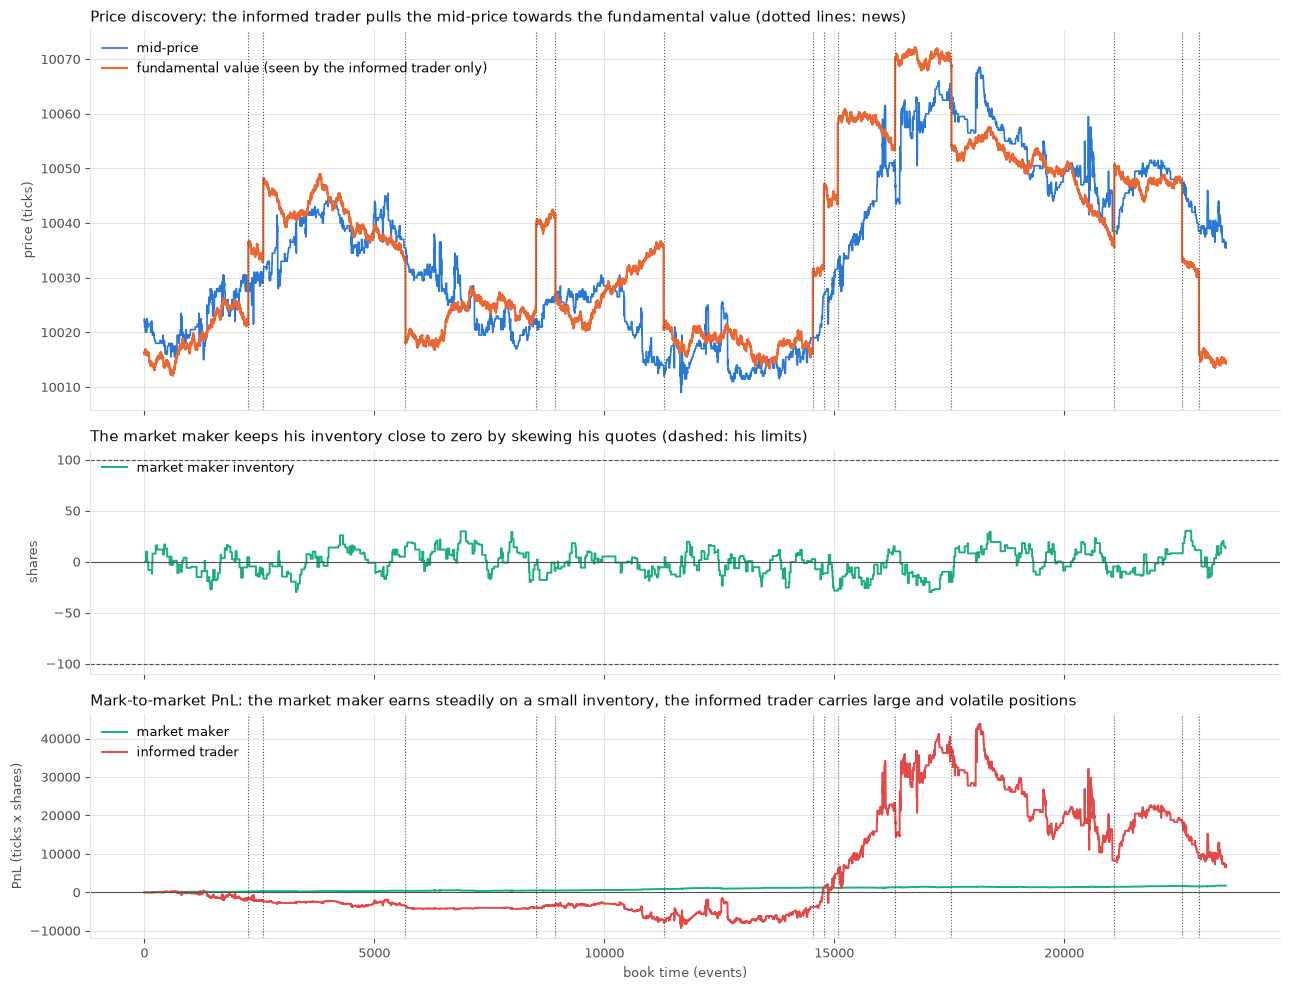

In [14]:
runs, eco_table = ecology_study()
print("runs:", len(runs), "| aggressive orders per run:", round(sum(len(r.orders) for r in runs)/len(runs)))
fig = plot_ecology_overview(runs[0])

## 9. Which ingredient creates which stylized fact?

The same statistics on four markets: the baseline market, the zero-intelligence flow alone, zero intelligence plus metaorders, and the full ecology (6 runs each).

                                 C(1)  C(10)  C(50)  gamma  R(1) ticks  R(20)/R(1)  mean spread (ticks)  P(spread = 1 tick)  excess kurtosis (20 events)  aggressive orders
market                                                                                                                                                                     
Baseline market (uniform flow) -0.177  0.012  0.001    NaN       2.615       0.388                6.089               0.117                       -0.799               6186
Zero intelligence               0.008  0.004  0.007    NaN       0.227       0.583                1.761               0.186                        7.190               7567
Zero intelligence + metaorders  0.054  0.035  0.015  0.262       0.332       0.878                2.521               0.127                        3.522              14210
Full ecology                    0.064  0.069  0.029  0.242       0.219       1.961                2.266               0.102                 

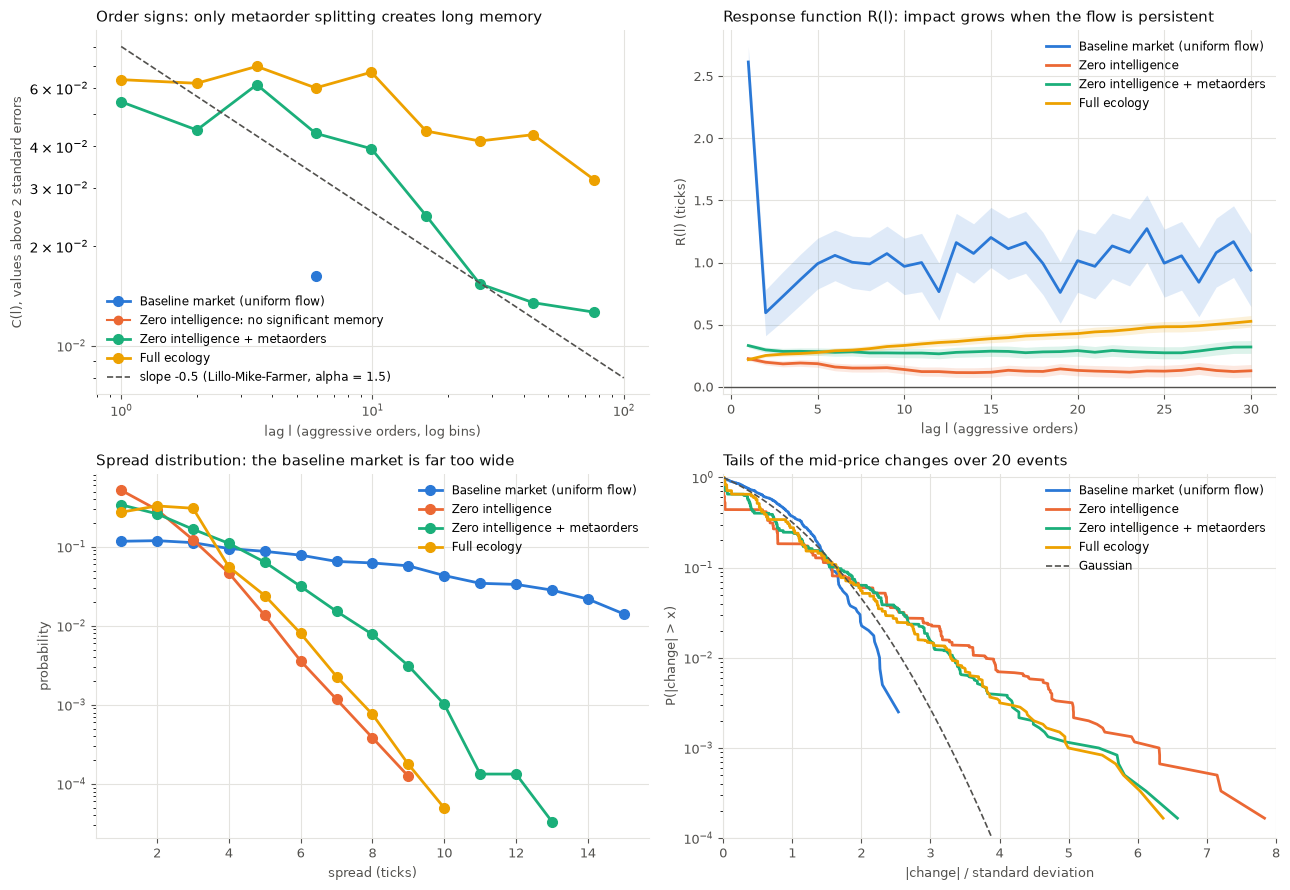

In [15]:
ab = ablation(baseline=result)
print(stylized_facts_table(ab).round(3).to_string())
fig = plot_stylized_facts(ab)

## 10. Who trades with whom, and who earns what

Left: share of the traded volume between each kind of aggressor and each kind of passive counterparty. Right: the **markout** of the market maker's passive fills, `s x (m(t + h) - price)` per share, split by who took his liquidity. At h = 0 it is the half-spread he earned, its evolution with h is the adverse selection.

Below: the PnL of every agent split exactly into the spread earned or paid against the mid, the price move in the 100 events after the fill, and the holding of the position until the end. The three parts add up to the mark-to-market PnL of the agent's own accounts (checked in `tests/test_ecology.py`).

passive_kind    noise maker  market maker
aggressor_kind                           
noise taker            18.1           9.5
informed               11.8           5.6
metaorder              15.3           7.6
strategies             29.7           2.4
                     spread  adverse  inventory  total  se_total  volume per run
kind                                                                            
Trader_Buy_and_sell   -1.16    -0.14       2.30   1.00      7.22           19.55
Trader_MA             -1.39     0.56      -3.45  -4.28      4.47          115.94
Trader_bearish        -6.20     2.29      -0.85  -4.76      0.12         3478.31
Trader_bullish        -6.36     2.59      -1.16  -4.92      0.17         2206.61
Trader_quantity       -1.25     0.07      -1.10  -2.28      2.16           67.29
Trader_random         -5.32     2.89      -2.91  -5.35      1.78          908.13
informed              -1.70     1.94       6.59   6.83      2.28         3688.00
market maker       

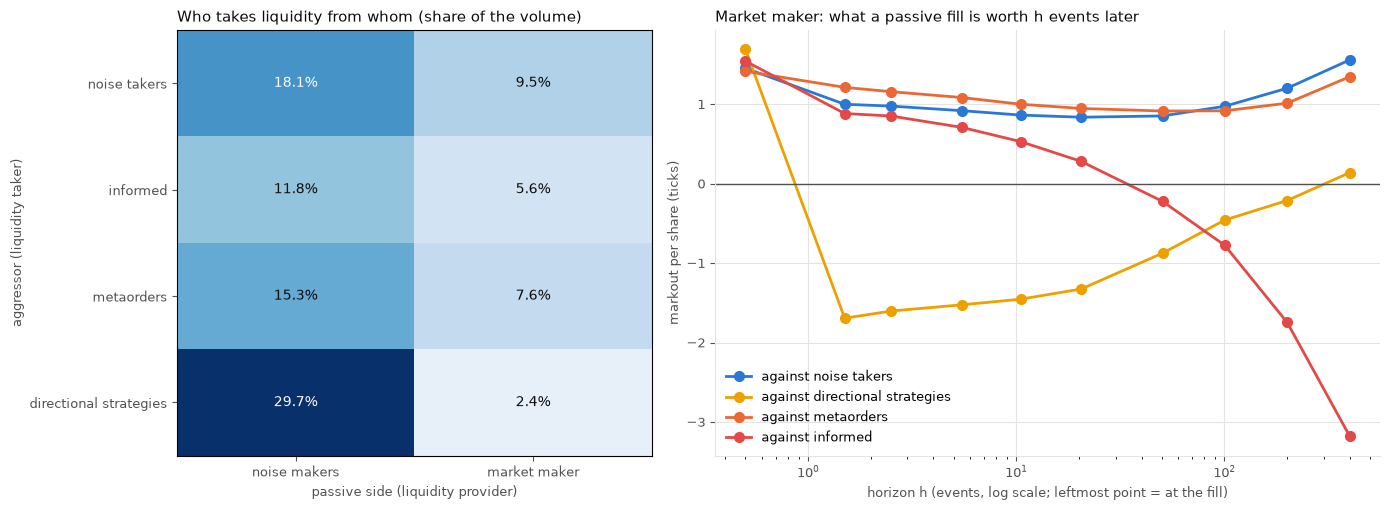

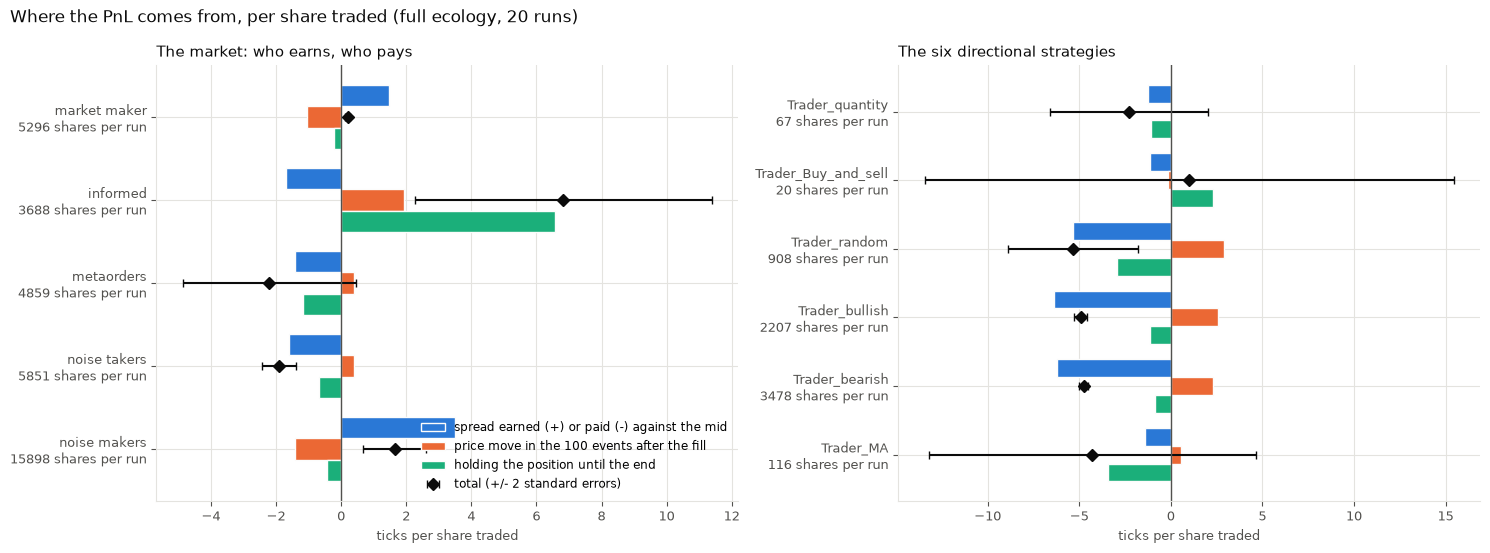

In [16]:
fig, fm, mk = plot_flows(runs)
print((100*fm).round(1).to_string())
fig, by_kind = plot_pnl_decomposition(eco_table)
print(by_kind.round(2).to_string())

## 11. How news gets into the price

Event study over every jump of the fundamental value larger than 5 ticks, in the direction of the news.

      mispricing  mm_inventory  mm_pnl  informed  metaorder  noise taker
dt                                                                      
0          15.80          0.01    0.00      0.10       0.07        -0.08
250        13.41         -8.10    2.36     58.32      -0.94        -2.56
500        10.33         -8.37   -5.97    103.20       1.81        -0.55
1000        7.94         -6.05   -2.66    177.36       4.43         0.78
1500        5.21         -2.65   19.22    220.46       7.12        -0.73


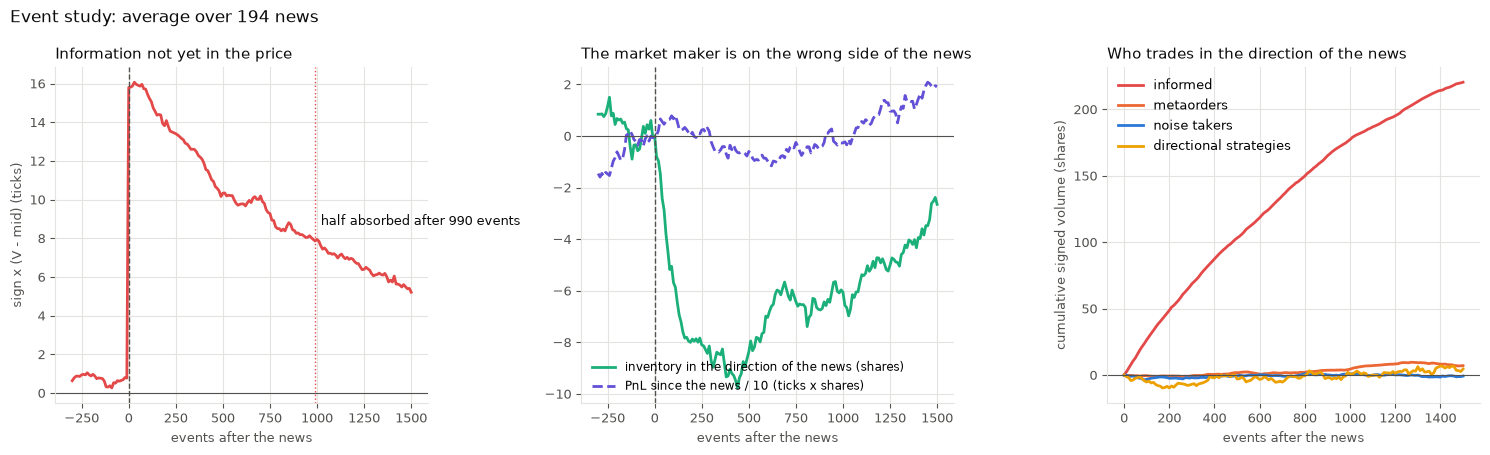

In [17]:
event, n_news = news_event_study(runs)
print(event.loc[[0, 250, 500, 1000, 1500], ['mispricing', 'mm_inventory', 'mm_pnl', 'informed', 'metaorder', 'noise taker']].round(2).to_string())
fig = plot_news(event, n_news)

## 12. The six strategies in both markets

The same six classes, with the same capital, in the baseline market and in the ecology. Costs and PnL are expressed in basis points so that the two markets (tick of 1 in the baseline market, 0.01 in the ecology) can be compared.

               strategy                          market  cost (bps of price)  PnL (bps of wealth)      se
0       Trader_quantity  Baseline market (uniform flow)               215.84              -278.16   72.29
1       Trader_quantity                    Full ecology                 1.25               -15.33    9.64
2   Trader_Buy_and_sell  Baseline market (uniform flow)               104.60                50.36   56.68
3   Trader_Buy_and_sell                    Full ecology                 1.16                -9.86    7.77
4         Trader_random  Baseline market (uniform flow)               524.66              -522.46   50.33
5         Trader_random                    Full ecology                 5.32               -32.36    6.55
6        Trader_bullish  Baseline market (uniform flow)               661.42             -1464.41  103.69
7        Trader_bullish                    Full ecology                 6.36              -108.60    6.12
8        Trader_bearish  Baseline market (unif

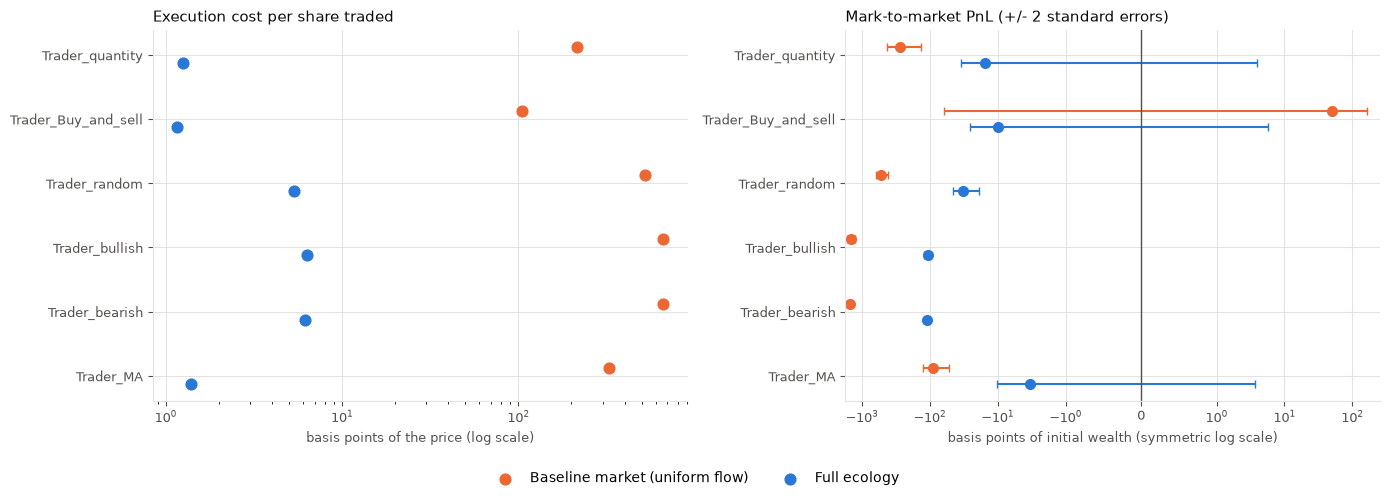

In [18]:
comparison = market_comparison(result, eco_table)
print(comparison.round(2).to_string())
fig = plot_market_comparison(comparison)

## 13. How wide should a market maker quote?

The market maker's PnL for five half-spreads and three intensities of informed trading (5 runs of 12,000 events each).

                total                  volume                
informed_rate     0.0     3.0     9.0     0.0     3.0     9.0
half_spread                                                  
0.5             770.6   437.3 -1563.8  2153.4  3095.2  3132.2
1.0            1143.6  1010.2  -617.9  1617.0  2369.6  2552.8
2.0            1119.0  1405.5    90.1   825.6  1543.2  1672.4
3.0             707.9  1198.9    53.6   368.2   856.2  1004.2
5.0             165.7   558.8  -112.1    68.2   265.0   360.4


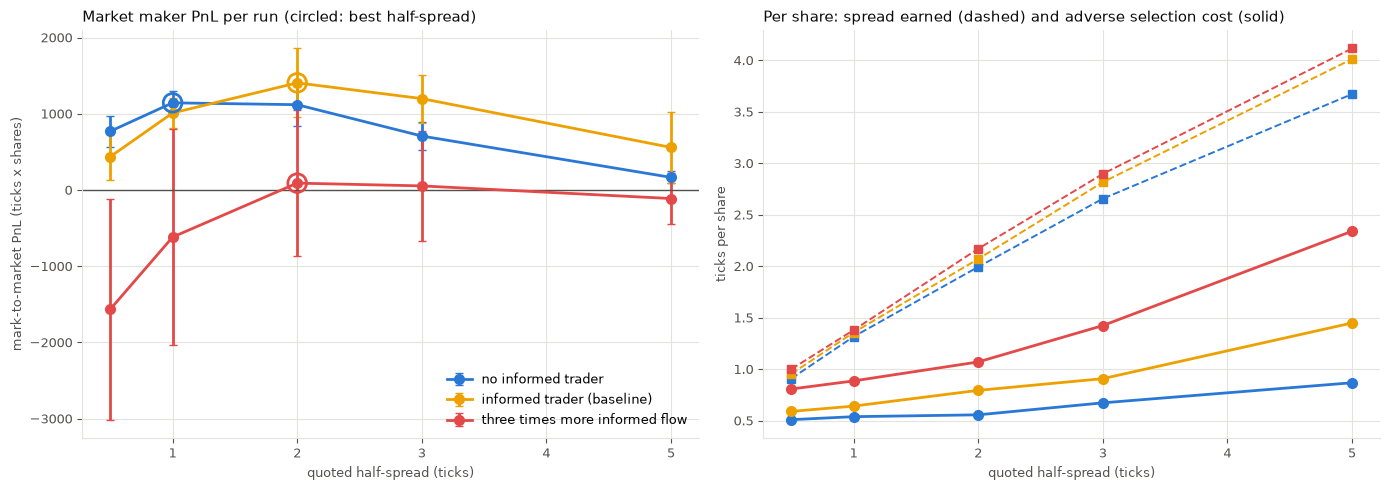

In [19]:
sweep = market_maker_sweep()
print(sweep.groupby(['informed_rate', 'half_spread'])[['total', 'volume']].mean().round(1).unstack(0).to_string())
fig = plot_market_maker_sweep(sweep)

## 14. The impact of a metaorder: linear or square root?

A buy metaorder of Q shares (25 to 1600) is executed with child market orders of 5 shares every 4 events, in three markets: Santa Fe liquidity only, the full ecology, and a market whose liquidity is mostly latent (`Trader_latent_liquidity` around a consensus price that does not move, a thin layer of noise liquidity at the touch). For every seed the market is run twice with the same random numbers, with and without the metaorder: the difference of the two mid-price paths is the impact of the metaorder alone. 16 seeds per market and size.

                         exponent (all Q)  exponent (Q <= 100)  exponent (Q >= 200)  impact kept after a further T (Q >= 200)  peak impact Q=1600 (ticks)
market                                                                                                                                                   
Santa Fe liquidity only              1.06                 0.94                 1.35                                      0.91                      116.66
Full ecology                         0.98                 1.02                 1.06                                      0.70                       68.12
Latent liquidity                     0.72                 1.04                 0.44                                      0.52                       43.84


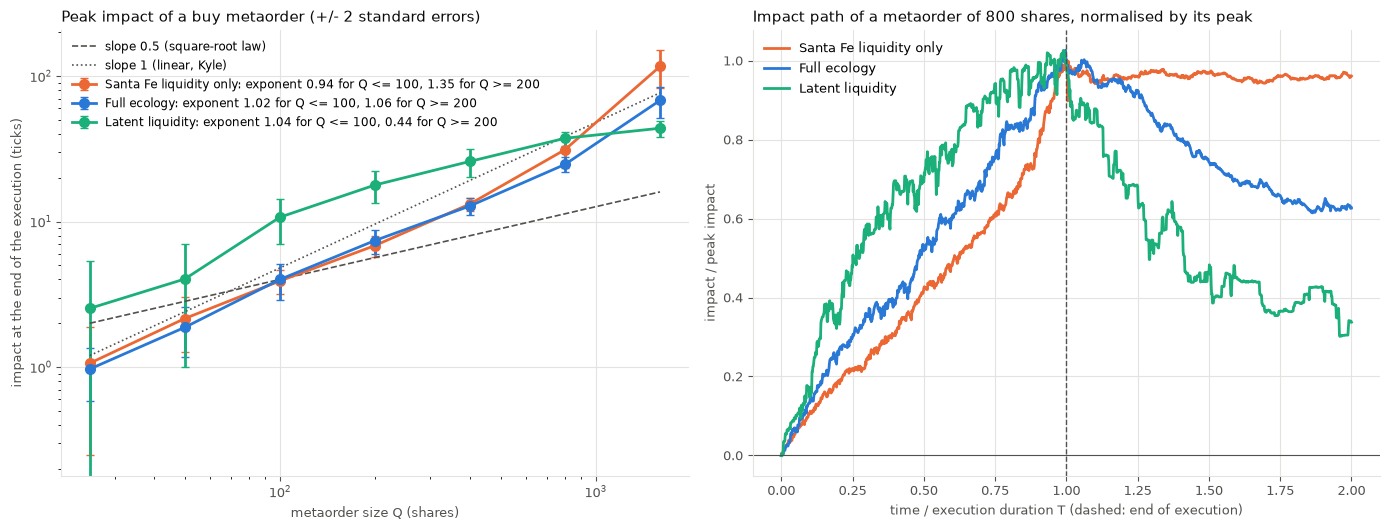

In [20]:
study = impact_study()
print(impact_table(study).round(2).to_string())
fig = plot_metaorder(study)

## 15. Insights

**1. Each stylized fact needs its own ingredient.** The baseline market reproduces none of them: anti-correlated order signs (C(1) = -0.18), thin-tailed price changes (excess kurtosis -0.8), and a spread of 6 ticks with a tick worth 1% of the price. The zero-intelligence flow alone already gives a realistic spread (1.8 ticks) and fat tails (kurtosis 7.2), as the book notes for the Santa Fe model, but no memory in the order signs. Only the splitting of metaorders makes the signs persistent (C(1) = 0.05 to 0.06, still 0.015 to 0.03 at lag 50). With the informed trader and the market maker on top, the response function R(l) grows with the lag (R(20) is twice R(1)), the shape of Figure 11.2 of the book. The decay of C(l) is slower than the l^-0.5 predicted by Lillo, Mike and Farmer (fitted exponent about 0.25), because with only three institutions and capped metaorders the runs are too short to reach the asymptotic regime.

**2. The market maker lives on a thin margin.** He earns 1.48 ticks per share of spread, gives back 1.05 to adverse selection and 0.23 to inventory, and keeps 0.20 ticks per share: 70% of what he earns is lost to better-informed counterparties. His markouts identify who is toxic. Against the informed trader a fill is worth +1.5 ticks at the fill and -3.2 ticks 400 events later: the loss grows with the horizon, the impact is permanent. Against the six directional strategies it falls to -1.7 ticks immediately, because their large orders run through his quote, and then recovers to about zero, because they carry no information and their impact is transient. Against noise takers and metaorders the markout stays positive.

**3. Information enters the price slowly.** After a news jump the informed trader alone trades in its direction (about 220 shares over 1,500 events). The mispricing decays from 16 ticks to 5 ticks over 1,500 events, while the market maker is pushed against the news (short about 8 shares) and loses on it before recovering. A capacity-limited informed trader brings information into the price gradually, as in the Kyle model of chapter 15.

**4. The ranking of the strategies is robust, the size of their losses is not.** In the ecology execution costs are about a hundred times smaller than in the baseline market (1.2 to 6.4 basis points against 105 to 662), because the baseline book is extremely illiquid. The strategies that sweep the book still lose with high significance (`Trader_bullish` -109 bps, `Trader_bearish` -110 bps, `Trader_random` -32 bps of initial wealth). The best-quote strategies (`Trader_quantity`, `Trader_Buy_and_sell`, `Trader_MA`) are not distinguishable from zero. Being aggressive costs the spread plus the impact, and none of the six strategies has information to pay for it.

**5. The optimal spread widens with informed flow, and quoting deep is not a free lunch.** The market maker's best half-spread is 1 tick without an informed trader and 2 ticks with the baseline informed trader. With three times more informed flow he barely breaks even at any spread and loses heavily when quoting tight. This is the Glosten-Milgrom logic of chapter 16. The adverse selection cost per share also rises with the quoted spread in all three markets (from 0.8 to 2.3 ticks with heavy informed flow): deep quotes are only reached by large or informed orders, so the fills they get are the worst ones.

**6. The square-root law is a property of liquidity, not of the metaorder.** With Santa Fe liquidity, impact is linear in the size Q (exponent 0.94 for Q up to 100) and becomes convex for large Q once the book is exhausted (1.35). It is also permanent: 91% of it remains after a further T. The full ecology is linear too (exponent 1.0), but only 70% of the impact remains, because the informed trader pulls the price back to the fundamental. With latent liquidity, whose depth grows linearly with the distance to a slow consensus price, impact is linear for small metaorders and crosses over to a square root for large ones (exponent 0.44 for Q of 200 and more). Most of it is transient: 52% remains on average, and less than 20% for Q = 1600. This is the crossover from Kyle-like to square-root impact of Eq. 18.19 and 18.20 and Figure 18.4, and the mechanism of chapter 19: the square-root law needs a V-shaped latent order book.

**Limits.** These are small simulated markets (20,000 events per run) whose parameters were set by hand to give a realistic spread and price discovery, not calibrated to data. The informed trader sees the fundamental exactly and the market maker has no latency. The point is the mechanisms, measured with the definitions of the book, not the exact values.